# ObraSegura · Grupo 10
**Cimiento Seguros: ¿tarifa estándar, recargo o garantías adicionales para un contrato público que se acaba de firmar?**

- **Decisión:** el día de la firma, el Gerente de Suscripción escoge entre tarifa estándar y recargo; a los contratos más riesgosos se les pueden pedir garantías adicionales. La Directora de Indemnizaciones alcanza a revisar unos 1.000 contratos en ejecución al año.
- **Fila:** un contrato de obra, interventoría o consultoría registrado en SECOP II.
- **Target:** `atraso` vale 1 si al contrato le agregaron más del 20 % del plazo pactado.
- **Costos:** dejar pasar un atraso con tarifa estándar (falso negativo) cuesta 5; cobrar recargo a un contrato que no se atrasa (falso positivo) cuesta 1. Por eso conviene cobrar recargo cuando la probabilidad de atraso pasa de 1/6 (5 × p > 1 × (1 − p)).
- **Regla simple:** recargo si la entidad contratante tiene una tasa de atraso previa alta. El corte se escoge con el entrenamiento.
- **Partición:** se entrena con los contratos firmados entre 2020 y 2023 y se prueba con los de 2024 y 2025. El radar son los contratos que siguen en ejecución.

Orden del cuaderno: entendimiento y preparación de los datos; después los modelos supervisados (regresión logística, árbol, random forest y red neuronal), que se entrenan, se validan y se comparan **todos juntos** contra la regla simple, con la misma partición, el mismo costo y las métricas del Test and Score de Orange (AUC, CA, F1, Prec, Recall y MCC); luego la parte no supervisada (segmentación de entidades con K-means, comparada con clustering jerárquico, y reglas de asociación) y al final el despliegue.

# Parte 0. Preparar el cuaderno

Instalar Orange

In [1]:
# Aquí instalo Orange, que Colab no trae por defecto.
# La uso para hacer el ranking de variables, igual que en clase.
# La q que está en el comando es para que no salga tanto texto mientras instala.
%pip install -q orange3

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


Cargar las herramientas

In [2]:
# En esta celda traigo todas las herramientas que voy a usar en el proyecto.
# Python no las tiene listas desde el inicio, por eso toca importarlas.
# Cuando escribo "as" le pongo un apodo corto a la herramienta para no escribir tanto.

# warnings me sirve para esconder los avisos de advertencia que no son errores
import warnings

# joblib me sirve para guardar el modelo en un archivo y poder usarlo en la app
import joblib

# numpy lo uso para hacer cuentas con muchos números al tiempo, como logaritmos o promedios
import numpy as np

# pandas es para manejar tablas, es como tener Excel dentro de Python
import pandas as pd

# matplotlib es para hacer los gráficos
import matplotlib.pyplot as plt

# La regresión logística da una probabilidad de atraso combinando todas las variables
from sklearn.linear_model import LogisticRegression

# El árbol de decisión, y dos funciones para dibujarlo y para escribir sus reglas
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text

# Random forest son muchos árboles que votan entre todos
from sklearn.ensemble import RandomForestClassifier

# La red neuronal, la misma que usa el widget Neural Network de Orange por dentro
from sklearn.neural_network import MLPClassifier

# StratifiedKFold parte los datos en batches con la misma proporción de atrasos, como en los cuadernos de clase
from sklearn.model_selection import StratifiedKFold

# El clustering jerárquico, igual que en el cuaderno de Redes II: linkage une los grupos, dendrogram los dibuja y fcluster corta
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

# roc_auc_score calcula el AUC, que me dice qué tan bien ordena el modelo de más riesgo a menos riesgo.
# silhouette_score me dice qué tan bien separados quedaron los grupos de K-means.
from sklearn.metrics import roc_auc_score, silhouette_score

# KMeans es el algoritmo para armar grupos, que es la parte no supervisada
from sklearn.cluster import KMeans

# PCA resume muchas variables en solo dos para poder dibujar los grupos en un plano
from sklearn.decomposition import PCA

# Esta función pasa una tabla de pandas al formato que entiende Orange
from Orange.data.pandas_compat import table_from_frames

# Aquí vienen las medidas del ranking: Info gain, Gain ratio, Gini, ReliefF y FCBF
from Orange.preprocess import score

# Con esto escondo las advertencias para que la pantalla quede limpia
warnings.filterwarnings('ignore')

# Para que en las tablas se lea el texto completo de las columnas largas, como las razones del radar
pd.set_option('display.max_colwidth', 200)

Conectar Google Drive

In [3]:
# Aquí conecto Colab con mi Google Drive porque ahí tengo guardado el archivo de los contratos.
# Cuando la corro me sale una ventana, escojo mi cuenta de Google y le doy permitir.
# Después de eso mi Drive queda disponible dentro de Colab en la carpeta /content/drive.
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Configuración del proyecto

In [4]:
# En esta celda dejo guardadas todas las decisiones importantes del proyecto.
# Las escribo en mayúscula para que se note que son configuraciones.
# Si quiero cambiar algo, por ejemplo los costos, solo lo cambio aquí y todo el cuaderno se actualiza.

# Esta es la ruta donde está el archivo dentro de mi Drive.
# Si otra persona corre el cuaderno, solo tiene que cambiar esta línea.
ARCHIVO = '/content/drive/MyDrive/SECOP2/obrasegura_contratos.csv'

# Esta es la columna que quiero predecir.
# atraso vale 1 si al contrato le agregaron más del 20 por ciento de los días que se habían pactado, y 0 si no.
# Por ejemplo, si pactaron 100 días y le agregaron 30, eso es un 30 por ciento, entonces cuenta como atraso.
OBJETIVO = 'atraso'

# Las columnas que no dejo entrar al modelo las separo por la razón por la que quedan afuera.

# Códigos y nombres: sirven para saber quién es quién, pero no explican el atraso.
# Además el nit y el nombre del contratista pueden ser de personas naturales, y por la Ley 1581 no los uso.
IDENTIFICADORES = ['id_contrato', 'codigo_entidad', 'nit', 'prov_key', 'nombre_entidad', 'proveedor_adjudicado']

# Textos y fechas: los uso para leer o para crear otras variables, pero no entran directo al modelo
TEXTOS_Y_FECHAS = ['duraci_n_del_contrato', 'objeto_del_contrato', 'objeto_n',
                   'fecha_de_firma', 'fecha_de_inicio', 'fin_pactado']

# Columnas de ayuda: el año lo uso para partir los datos, el mes para crear "firmado en diciembre",
# y observable solo dice si el contrato ya terminó
AYUDA = ['anio_firma', 'mes_firma', 'observable']

# Columnas de fuga: solo se conocen después de firmar el contrato.
# Cimiento tiene que decidir el día de la firma, entonces usarlas sería como hacer trampa.
FUGA = ['dias_adicionados', 'ratio_adic', 'estado_contrato', 'fecha_de_fin_del_contrato',
        'valor_pagado', 'liquidaci_n', 'ultima_actualizacion']

# Junto todas en una sola lista
IGNORAR = IDENTIFICADORES + TEXTOS_Y_FECHAS + AYUDA + FUGA

# Estas columnas tienen números muy desiguales, hay contratos de un millón y otros de miles de millones.
# A estas les saco el logaritmo para que los números gigantes no dominen al modelo.
TRANSFORMAR_LOG = ['valor_del_contrato', 'duracion_pactada_dias',
                   'prov_n_previos_obs', 'prov_n_firmados_prev',
                   'ent_n_previos_obs', 'ent_n_firmados_prev']

# En estas columnas recorto los valores extremos, porque hay datos mal digitados
RECORTAR = ['valor_del_contrato', 'duracion_pactada_dias', 'dias_firma_inicio']

# Estos son los costos que da el brief.
# Si no le cobro recargo a un contrato que sí se atrasó, eso es un falso negativo y cuesta 5.
COSTO_FN = 5
# Si le cobro recargo a un contrato que no se atrasó, eso es un falso positivo y cuesta 1.
COSTO_FP = 1

# Esta es la cantidad de contratos que la Directora de Indemnizaciones alcanza a revisar al año
CAPACIDAD = 1000

# Batches en que parto la prueba para ver si los resultados se sostienen, como el cross validation de clase
K = 5

# La semilla es un número fijo para que todo lo que se hace al azar me salga igual cada vez que corro el cuaderno
SEMILLA = 2559

# Si lo pongo en True, al final se descargan el modelo y el radar a mi computador.
# Lo dejo en False para que no salgan descargas cuando alguien corre todo el cuaderno.
DESCARGAR = False

# Parte 1. Entendimiento de los datos

Leer el archivo de contratos

In [5]:
# Aquí abro el archivo y lo guardo en una tabla que llamé df_secop.
# Lo de low_memory en False es para que lea todo el archivo de una vez y no salga una advertencia.
df_secop = pd.read_csv(ARCHIVO, low_memory=False)

# len cuenta cuántas filas tiene la tabla, y cada fila es un contrato.
# shape me dice cuántas filas y cuántas columnas hay.
print('Contratos en el archivo:', len(df_secop), '| columnas:', df_secop.shape[1])

# head me muestra las primeras cinco filas para ver cómo vienen los datos.
# No muestro el nombre ni el nit del contratista, porque pueden ser de personas naturales.
df_secop.drop(columns=['proveedor_adjudicado', 'nit', 'prov_key']).head()

Contratos en el archivo: 60955 | columnas: 50


,id_contrato,nombre_entidad,codigo_entidad,tipo_de_contrato,modalidad_de_contratacion,orden,sector,departamento,entidad_centralizada,es_pyme,...,fin_pactado,observable,dias_adicionados,ratio_adic,atraso,estado_contrato,fecha_de_fin_del_contrato,valor_pagado,liquidaci_n,ultima_actualizacion
0,CO1.PCCNTR.1527022,COMANDO GENERAL DE LAS FUERZAS MILITARES,700406036,Consultoría,Mínima cuantía,Nacional,defensa,Distrito Capital de Bogotá,Centralizada,Si,...,2020-12-28,False,0,0.0,0,Aprobado,2020-12-15,54288217.0,No,NaN
1,CO1.PCCNTR.1527824,INVIAS,700676059,Obra,Contratación directa,Nacional,Transporte,Distrito Capital de Bogotá,Centralizada,No,...,2021-04-28,True,0,0.0,0,terminado,2022-06-30,0.0,No,2025-01-02T00:00:00.000
2,CO1.PCCNTR.1527833,INVIAS,700676059,Obra,Contratación directa,Nacional,Transporte,Distrito Capital de Bogotá,Centralizada,No,...,2021-04-29,True,0,0.0,0,terminado,2022-06-30,0.0,No,2024-11-14T00:00:00.000
3,CO1.PCCNTR.1527917,INVIAS,700676059,Obra,Contratación directa,Nacional,Transporte,Distrito Capital de Bogotá,Centralizada,No,...,2022-02-25,True,0,0.0,0,terminado,2022-07-31,0.0,No,2025-02-13T00:00:00.000
4,CO1.PCCNTR.1527919,INVIAS,700676059,Obra,Contratación directa,Nacional,Transporte,Distrito Capital de Bogotá,Centralizada,No,...,2021-04-28,True,0,0.0,0,terminado,2022-07-31,0.0,No,2025-05-30T00:00:00.000


Separar entrenamiento, prueba y radar

In [6]:
# Aquí parto los contratos en tres tablas, como pide el brief.
# El radar son los contratos que siguen en ejecución, todavía no se sabe si se van a atrasar.
# Entrenamiento son los contratos de 2020 a 2023 que ya terminaron, con estos aprende el modelo.
# Prueba son los contratos de 2024 a 2025 que ya terminaron, son el examen final y el modelo no los ve antes.
# Lo parto por años porque en la vida real el modelo aprende del pasado y se usa con contratos nuevos.

# Me quedo con los contratos donde observable es 0, que son los que siguen en ejecución.
# El copy es para trabajar con una copia y no dañar la tabla original.
radar = df_secop[df_secop['observable'] == 0].copy()

# Y aquí con los que sí tienen resultado conocido
df_obs = df_secop[df_secop['observable'] == 1].copy()

# between me deja quedarme con los años que están entre esos dos números, incluyéndolos
entrenamiento = df_obs[df_obs['anio_firma'].between(2020, 2023)].copy()
prueba = df_obs[df_obs['anio_firma'].between(2024, 2025)].copy()

# Muestro cuántos contratos quedan después de cada filtro, porque el brief lo pide.
# Al sumar la columna de atraso me da cuántos contratos se atrasaron, porque cada atraso vale 1.
print('1. Todos los contratos:', len(df_secop))
print('2. Con desenlace conocido (observable = 1):', len(df_obs), '| atrasos:', df_obs[OBJETIVO].sum())
print('   En ejecución (radar):', len(radar))
print('3. Entrenamiento 2020-2023:', len(entrenamiento), '| atrasos:', entrenamiento[OBJETIVO].sum())
print('4. Prueba 2024-2025:', len(prueba), '| atrasos:', prueba[OBJETIVO].sum())
print('   Observables de 2026 que no entran ni a entrenamiento ni a prueba:', len(df_obs) - len(entrenamiento) - len(prueba))

# La tasa base es el porcentaje de contratos que se atrasan.
# El promedio de una columna de unos y ceros me da justo ese porcentaje.
TASA_BASE = entrenamiento[OBJETIVO].mean()
print('\nTasa base de atraso (entrenamiento):', round(TASA_BASE, 3))
print('Tasa de atraso en la prueba:', round(prueba[OBJETIVO].mean(), 3))

1. Todos los contratos: 60955
2. Con desenlace conocido (observable = 1): 47238 | atrasos: 9219
   En ejecución (radar): 13717
3. Entrenamiento 2020-2023: 29974 | atrasos: 5265
4. Prueba 2024-2025: 17245 | atrasos: 3952
   Observables de 2026 que no entran ni a entrenamiento ni a prueba: 19

Tasa base de atraso (entrenamiento): 0.176
Tasa de atraso en la prueba: 0.229


**Lectura.** De los 60.955 contratos, 47.238 ya tienen desenlace y 13.717 siguen en ejecución (el radar). Entreno con 29.974 contratos de 2020 a 2023, que se atrasan el 17,6 %, y pruebo con 17.245 de 2024 y 2025, que se atrasan el 22,9 %. Que la prueba tenga una tasa más alta importa: un modelo que aprende con años de menos atraso puede quedarse corto.

Tasa de atraso por año

In [7]:
# Aquí miro por cada año cuántos contratos hay y qué porcentaje se atrasó.
# count es la cantidad de contratos y mean es el porcentaje de atraso.
df_obs.groupby('anio_firma')[OBJETIVO].agg(['count', 'mean']).round(3)

,count,mean
anio_firma,,
2020,3310,0.149
2021,7068,0.186
2022,8741,0.171
2023,10855,0.181
2024,8412,0.206
2025,8833,0.251
2026,19,0.105


Tasa de atraso por año y plazo pactado

In [8]:
# 2025 sale con la tasa más alta, pero de ese año solo se conoce el resultado de los contratos que ya vencieron,
# que son sobre todo los cortos. Para saber si es por eso o si de verdad los contratos se atrasan más,
# comparo la tasa de cada año dentro de contratos con plazos parecidos.

# cut parte el plazo en rangos, y labels les pone nombre a los rangos
rangos_plazo = pd.cut(df_obs['duracion_pactada_dias'], [0, 30, 60, 90, 180, 365, 100000],
                      labels=['hasta 30', '31 a 60', '61 a 90', '91 a 180', '181 a 365', 'más de 365'])

# Primero la tasa de atraso de cada rango de plazo, con todos los años juntos.
# display muestra la tabla igual que cuando la tabla es lo último de la celda.
display(df_obs.groupby(rangos_plazo, observed=True)[OBJETIVO].agg(['count', 'mean']).round(3))

# Después la tasa por año y rango. unstack pone los rangos como columnas para que quede una tabla de doble entrada.
# La multiplico por cien para leerla en porcentaje.
por_anio = df_obs.groupby(['anio_firma', rangos_plazo], observed=True)[OBJETIVO].mean().unstack()
(por_anio * 100).round(1)

,count,mean
duracion_pactada_dias,,
hasta 30,7131,0.111
31 a 60,5187,0.209
61 a 90,7089,0.179
91 a 180,13540,0.225
181 a 365,10867,0.202
más de 365,3424,0.244


duracion_pactada_dias,hasta 30,31 a 60,61 a 90,91 a 180,181 a 365,más de 365
anio_firma,,,,,,
2020,12.4,17.0,15.2,17.6,12.7,13.5
2021,10.2,17.5,12.2,20.2,19.6,25.7
2022,8.3,18.8,15.7,18.3,18.6,18.7
2023,12.5,19.5,14.2,18.5,18.8,28.9
2024,7.5,16.4,16.3,26.6,27.6,43.1
2025,14.5,28.4,25.9,30.3,25.3,NaN
2026,10.5,NaN,NaN,NaN,NaN,NaN


**Lectura.** Los contratos de hasta 30 días son los que menos se atrasan (11,1 %), así que la tasa alta de 2025 no se explica solo porque de ese año conocemos sobre todo los cortos. En 2025 la tasa es más alta que en 2020-2023 en todos los rangos de plazo, y en 2024 en todos los contratos de más de 60 días (por ejemplo, de 91 a 180 días: 18,5 % en 2023, 26,6 % en 2024 y 30,3 % en 2025). Para Cimiento quiere decir que el riesgo de atraso viene subiendo y que lo aprendido con 2020-2023 puede subestimarlo.

Valores extremos

In [9]:
# El brief pide revisar los valores extremos antes de usarlos.
# Aquí miro los cinco contratos más caros con su identificador, para poder buscarlos en SECOP II,
# y también los contratos con valores muy bajos y con fechas que no tienen sentido.

columnas_ver = ['id_contrato', 'nombre_entidad', 'tipo_de_contrato', 'valor_del_contrato', 'duracion_pactada_dias']
extremos = df_secop.nlargest(5, 'valor_del_contrato')[columnas_ver].copy()

# El valor por día ayuda a ver si el valor es absurdo para el plazo que tiene el contrato
extremos['valor_por_dia'] = extremos['valor_del_contrato'] / extremos['duracion_pactada_dias']

# Escribo los valores en pesos con separador de miles para que se lean bien
for col in ['valor_del_contrato', 'valor_por_dia']:
    extremos[col] = extremos[col].map('{:,.0f}'.format)

# Cuento los contratos muy baratos y los que tienen fechas raras
dias = (pd.to_datetime(df_secop['fecha_de_inicio'], errors='coerce') - pd.to_datetime(df_secop['fecha_de_firma'], errors='coerce')).dt.days
print('Contratos por menos de un millón de pesos:', (df_secop['valor_del_contrato'] < 1e6).sum())
print('Contratos con valor 0:', (df_secop['valor_del_contrato'] == 0).sum())
print('Contratos que inician antes de la firma:', (dias < 0).sum())
print('Contratos sin fecha de inicio:', dias.isna().sum())
extremos

Contratos por menos de un millón de pesos: 520
Contratos con valor 0: 0
Contratos que inician antes de la firma: 187
Contratos sin fecha de inicio: 2160


,id_contrato,nombre_entidad,tipo_de_contrato,valor_del_contrato,duracion_pactada_dias,valor_por_dia
31288,CO1.PCCNTR.5972834,INSTITUCION EDUCATIVA ELISEO PAYAN,Obra,"6,453,840,000,000,000",60.0,"107,564,000,000,000"
43914,CO1.PCCNTR.8069219,ALCALDIA MUNICIPIO DE SITIONUEVO,Obra,"998,049,859,557",166.0,"6,012,348,552"
39866,CO1.PCCNTR.7171517,DEPARTAMENTO DE ANTIOQUIA//,Obra,"712,569,236,855",30.0,"23,752,307,895"
11561,CO1.PCCNTR.3633179,INVIAS,Obra,"657,176,378,088",2405.0,"273,254,211"
56448,CO1.PCCNTR.9496559,INVIAS,Obra,"650,399,558,495",3483.0,"186,735,446"


**Lectura.** Hay errores de digitación evidentes. El contrato más caro (CO1.PCCNTR.5972834, de una institución educativa) dice valer $6,45 mil billones a 60 días, y hay 520 contratos por menos de un millón de pesos (el más barato vale un centavo). Según la clase de datos atípicos, estos son atípicos globales: se alejan de toda la distribución. Un valor por día absurdo para el plazo del contrato es un atípico contextual: el valor solo no parece raro, pero sí para ese plazo. También hay 187 contratos que inician antes de la firma y 2.160 sin fecha de inicio. No borro estos contratos: en la Parte 2 recorto el valor, el plazo y los días entre firma e inicio a los percentiles 1 y 99 del entrenamiento, antes de sacar el logaritmo.

Datos faltantes

In [10]:
# Aquí miro qué columnas tienen datos vacíos en el entrenamiento, cuántos son y qué porcentaje representan.
# Un vacío no siempre es un error. Por ejemplo, si falta la tasa de atraso previa del contratista,
# normalmente es porque ese contratista no tenía contratos anteriores terminados.

# Armo una tabla con dos columnas: la cantidad de vacíos y el porcentaje.
# isna marca dónde hay vacíos y sum los cuenta. Con mean y por cien saco el porcentaje.
nulos = pd.DataFrame({
    'nulos': entrenamiento.isna().sum(),
    'porcentaje': (entrenamiento.isna().mean() * 100).round(1),
})

# Muestro solo las columnas que tienen al menos un vacío, ordenadas de más a menos
nulos[nulos['nulos'] > 0].sort_values('porcentaje', ascending=False)

,nulos,porcentaje
prov_tasa_atraso_prev,20447,68.2
prov_ratio_medio_prev,20447,68.2
edad_proveedor_anios,17389,58.0
ent_ratio_medio_prev,6223,20.8
ent_tasa_atraso_prev,6223,20.8
ultima_actualizacion,5475,18.3
nit,2993,10.0
unspsc_segmento,1762,5.9
prov_key,687,2.3


**Lectura.** Los vacíos más grandes son de historia: el 68,2 % de los contratos son de contratistas sin contratos anteriores terminados, por eso falta su tasa de atraso previa, y el 20,8 % son de entidades sin historia. La edad del contratista falta en el 58 % porque el contratista no está en el RUES. Con la clasificación de clase, ninguno de estos vacíos es MCAR (completamente al azar): son MAR, porque los explica otra variable (si el contratista o la entidad tenían contratos anteriores terminados, y si el NIT cruza con el RUES). No borro filas: en los números lleno los vacíos con el promedio del entrenamiento, y las variables prov_sin_historia y ent_sin_historia marcan a los que no tenían historia, para que el modelo distinga a un contratista promedio de uno desconocido. nit, prov_key y ultima_actualizacion no entran al modelo.

Distribución del valor y del plazo

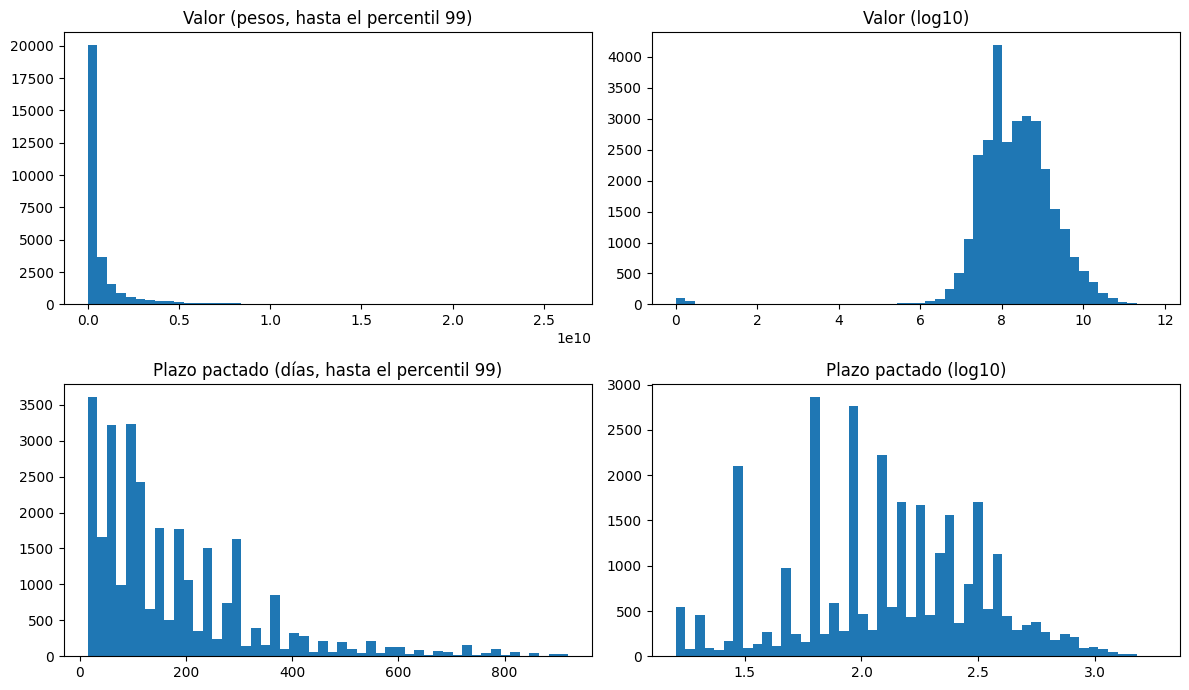

In [11]:
# Aquí hago cuatro histogramas para ver cómo se reparten el valor y el plazo de los contratos.
# Arriba está el valor en pesos y en logaritmo, abajo el plazo en días y en logaritmo.
# El logaritmo en base 10 más o menos cuenta los ceros: un millón da 6 y mil millones da 9.
# Le sumo 1 antes porque el logaritmo de 0 no existe.
# Para que los errores de digitación no dañen el dibujo, solo dibujo hasta el percentil 99.

# Creo una figura con cuatro cuadros, dos arriba y dos abajo
fig, ejes = plt.subplots(2, 2, figsize=(12, 7))

valor = entrenamiento['valor_del_contrato']
plazo = entrenamiento['duracion_pactada_dias']

# En cada cuadro dibujo un histograma con 50 barras y le pongo título
ejes[0, 0].hist(valor[valor <= valor.quantile(0.99)], bins=50)
ejes[0, 0].set_title('Valor (pesos, hasta el percentil 99)')

ejes[0, 1].hist(np.log10(valor + 1), bins=50)
ejes[0, 1].set_title('Valor (log10)')

ejes[1, 0].hist(plazo[plazo <= plazo.quantile(0.99)], bins=50)
ejes[1, 0].set_title('Plazo pactado (días, hasta el percentil 99)')

ejes[1, 1].hist(np.log10(plazo + 1), bins=50)
ejes[1, 1].set_title('Plazo pactado (log10)')

# Acomodo los cuadros para que no se monten y muestro la figura
plt.tight_layout()
plt.show()

**Lectura.** El valor y el plazo están muy cargados a la izquierda: muchos contratos pequeños y unos pocos enormes. Con el logaritmo la forma queda más pareja, por eso al modelo le paso el logaritmo del valor y del plazo.

Tasa de atraso por grupos

In [12]:
# Aquí miro el porcentaje de atraso según distintas características del contrato.
# Para cada variable sale una tabla con cuántos contratos hay en cada categoría y qué porcentaje se atrasó.
# Si una categoría está muy por encima de la tasa base, esos contratos son más riesgosos.

# Estas son las variables por las que quiero agrupar
GRUPOS = ['tipo_de_contrato', 'modalidad_de_contratacion', 'orden', 'sector', 'es_consorcio_ut']

# Para cada variable hago la tabla y la muestro ordenada de la categoría más grande a la más pequeña.
# display muestra cada tabla igual que cuando la tabla es lo último de la celda.
for col in GRUPOS:
    tabla = entrenamiento.groupby(col)[OBJETIVO].agg(['count', 'mean'])
    display(tabla.sort_values('count', ascending=False).round(3))

,count,mean
tipo_de_contrato,,
Obra,20221,0.168
Interventoría,5689,0.232
Consultoría,4064,0.133


,count,mean
modalidad_de_contratacion,,
Mínima cuantía,6820,0.142
Concurso de méritos abierto,6485,0.198
Selección Abreviada de Menor Cuantía,5588,0.150
Contratación directa,4456,0.231
Licitación pública Obra Publica,4179,0.195
Contratación régimen especial,877,0.082
Contratación Directa (con ofertas),809,0.157
Contratación régimen especial (con ofertas),506,0.186
Seleccion Abreviada Menor Cuantia Sin Manifestacion Interes,174,0.155


,count,mean
orden,,
Territorial,20182,0.186
Nacional,9122,0.159
Corporación Autónoma,670,0.104


,count,mean
sector,,
Servicio Público,9759,0.192
No aplica/No pertenece,5483,0.177
Transporte,5475,0.213
defensa,1581,0.062
Ambiente y Desarrollo Sostenible,1510,0.123
Educación Nacional,1080,0.221
Ley de Justicia,797,0.176
"Vivienda, Ciudad y Territorio",605,0.150
Salud y Protección Social,543,0.103


,count,mean
es_consorcio_ut,,
0,22079,0.167
1,7895,0.200


**Lectura.** Las interventorías se atrasan más (23,2 %) que las obras (16,8 %) y las consultorías (13,3 %), y la contratación directa (23,1 %) más que la mínima cuantía (14,2 %). Las entidades territoriales (18,6 %) y los consorcios o uniones temporales (20,0 %) también quedan por encima de la tasa base. Por sector, Transporte (21,3 %) y Servicio Público (19,2 %), que son de los más grandes, quedan por encima de la tasa base, igual que Educación (22,1 %); los que menos se atrasan son defensa (6,2 %) y salud (10,3 %). Para Cimiento, el tipo de contrato y la modalidad ya dan una primera idea de dónde cobrar recargo, pero ninguna categoría grande pasa del 25 %.

Matriz de correlaciones

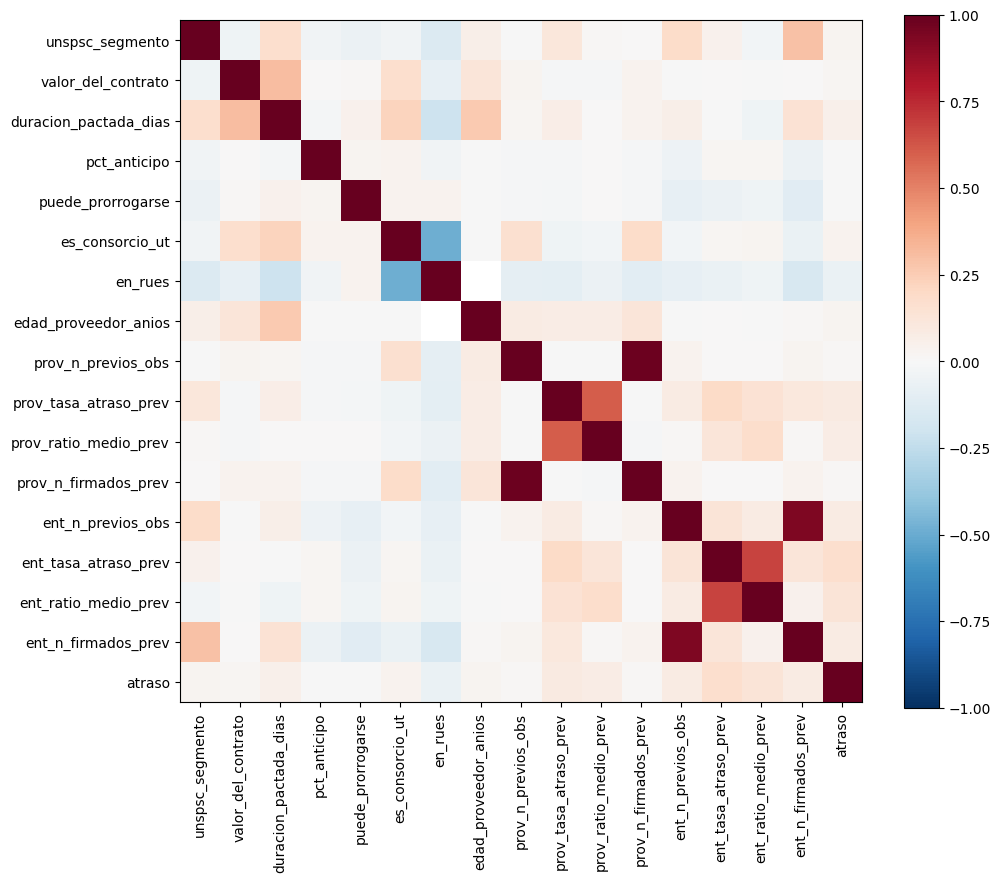

In [13]:
# Aquí hago un mapa de calor con la correlación entre las variables numéricas.
# La correlación va de -1 a 1. Rojo fuerte quiere decir que suben juntas,
# azul fuerte que cuando una sube la otra baja, y blanco que casi no tienen relación.
# Me sirve para ver qué variables dicen casi lo mismo.

# Me quedo solo con las columnas numéricas que sí pueden entrar al modelo, y le agrego el atraso
numericas = entrenamiento.drop(columns=IGNORAR, errors='ignore').select_dtypes(include='number').columns

# corr calcula la correlación de todas contra todas
correlaciones = entrenamiento[numericas].corr()

# Dibujo el mapa de calor con colores de rojo a azul y una barra al lado que sirve de leyenda.
# Los nombres de abajo los pongo de lado para que quepan.
plt.figure(figsize=(11, 9))
plt.imshow(correlaciones, cmap='RdBu_r', vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(len(numericas)), numericas, rotation=90)
plt.yticks(range(len(numericas)), numericas)
plt.show()

**Lectura.** Hay variables que dicen casi lo mismo: los contratos previos terminados y los firmados del contratista (0,98) y de la entidad (0,93), y la tasa de atraso previa con los días que suele agregar la entidad (0,68). Con el atraso, la más relacionada es la tasa de atraso previa de la entidad (0,17), la misma que usa la regla simple. Ninguna correlación con el atraso es fuerte, así que ninguna variable sola va a predecir bien.

Detector de fuga

In [14]:
# Este es el detector de fuga que pide el brief.
# Para cada variable calculo el AUC usándola sola, para ver qué tan bien separa los contratos que se atrasan.
# Un AUC de 0.5 es como lanzar una moneda, o sea que la variable no ayuda.
# Si da muy cerca de 1, o muy cerca de 0, la variable separa demasiado bien y toca sospechar que es fuga.
# A propósito dejo entrar las columnas de fuga para mostrar que el detector sí las encuentra.

# Esto es lo que quiero detectar, el atraso real
y_detector = entrenamiento[OBJETIVO]

# Aquí voy guardando el AUC de cada variable
auc_variables = {}

# Primero las variables numéricas, menos el atraso y los números de identificación.
# El AUC no acepta vacíos, entonces los lleno con la mediana de la columna.
# observable tampoco, porque en el entrenamiento todos los contratos tienen observable igual a 1.
candidatas = entrenamiento.select_dtypes(include='number').columns.drop([OBJETIVO, 'observable'] + IDENTIFICADORES, errors='ignore')
for col in candidatas:
    x = entrenamiento[col].fillna(entrenamiento[col].median())
    auc_variables[col] = roc_auc_score(y_detector, x)

# Después las variables de texto. Como el AUC necesita números, cambio cada categoría por su porcentaje de atraso.
# Ese porcentaje lo aprendo con 2020 a 2022 y mido el AUC en 2023.
# Si lo aprendiera y lo midiera con los mismos contratos, las categorías con pocos contratos se verían mejores de lo que son.
antes_2023 = entrenamiento[entrenamiento['anio_firma'] < 2023]
en_2023 = entrenamiento[entrenamiento['anio_firma'] == 2023]
texto = entrenamiento.select_dtypes(exclude='number').columns.drop(IDENTIFICADORES + TEXTOS_Y_FECHAS, errors='ignore')
texto = [col for col in texto if col not in ['fecha_de_fin_del_contrato', 'ultima_actualizacion']]
for col in texto:
    tasa = antes_2023.groupby(col)[OBJETIVO].mean()
    x = en_2023[col].map(tasa).fillna(TASA_BASE)
    auc_variables[col] = roc_auc_score(en_2023[OBJETIVO], x)

# Armo la tabla de resultados.
# La distancia a 0.5 me dice qué tan informativa es la variable.
# El rol dice por qué está o no está en el modelo, y la última columna si entra o no.
detector = pd.DataFrame({'AUC': auc_variables})
detector['distancia a 0.5'] = (detector['AUC'] - 0.5).abs()
detector['rol'] = np.where(detector.index.isin(FUGA), 'Fuga', np.where(detector.index.isin(AYUDA), 'Ayuda', 'Variable'))
detector['entra al modelo'] = np.where(detector.index.isin(IGNORAR), 'No', 'Sí')

# Las más sospechosas quedan arriba
detector.sort_values('distancia a 0.5', ascending=False).round(3)

,AUC,distancia a 0.5,rol,entra al modelo
ratio_adic,1.000,0.500,Fuga,No
dias_adicionados,0.978,0.478,Fuga,No
estado_contrato,0.869,0.369,Fuga,No
ent_ratio_medio_prev,0.635,0.135,Variable,Sí
ent_tasa_atraso_prev,0.622,0.122,Variable,Sí
departamento,0.596,0.096,Variable,Sí
ent_n_firmados_prev,0.587,0.087,Variable,Sí
ent_n_previos_obs,0.575,0.075,Variable,Sí
tipo_de_contrato,0.573,0.073,Variable,Sí
valor_del_contrato,0.561,0.061,Variable,Sí


**Lectura.** El detector encuentra las tres columnas de fuga: ratio_adic (AUC 1,000), dias_adicionados (0,978) y estado_contrato (0,869). Todas se conocen después de la firma y no entran al modelo. Las variables que sí entran tienen AUC entre 0,46 y 0,64, y las más informativas son las de la historia de la entidad (ent_ratio_medio_prev con 0,635 y ent_tasa_atraso_prev con 0,622), que es la base de la regla simple. Ninguna separa sospechosamente bien.

# Parte 2. Preparación de los datos

Crear variables nuevas

In [15]:
# En esta celda creo columnas nuevas que pueden ayudar a predecir el atraso.
# Todas se saben el día de la firma, entonces no hay problema de fuga.
# Las escribo como una función, que es como una receta: la escribo una vez y la uso con las tres tablas.

def crear_variables(tabla):
    tabla = tabla.copy()

    # Las fechas vienen como texto, así que primero las convierto en fechas para poder restarlas.
    # Lo de errors en coerce es para que si alguna fecha viene mal escrita la deje vacía y no se dañe todo.
    firma = pd.to_datetime(tabla['fecha_de_firma'], errors='coerce')
    inicio = pd.to_datetime(tabla['fecha_de_inicio'], errors='coerce')

    # Primera variable: los días que pasan entre la firma y el inicio del contrato.
    # Mi idea es que si un contrato se demora mucho en arrancar, puede que esté mal planeado.
    tabla['dias_firma_inicio'] = (inicio - firma).dt.days

    # Segunda variable: pongo 1 si el contrato se firmó en diciembre y 0 si no.
    # Lo hago porque a fin de año se firma a las carreras para no perder el presupuesto.
    tabla['firma_diciembre'] = (tabla['mes_firma'] == 12).astype(int)

    # Tercera variable: pongo 1 si el contratista no tiene contratos anteriores terminados.
    # Si no hay historia de él, no hay forma de saber si suele atrasarse.
    tabla['prov_sin_historia'] = (tabla['prov_n_previos_obs'] == 0).astype(int)

    # Cuarta variable: lo mismo pero para la entidad que contrata
    tabla['ent_sin_historia'] = (tabla['ent_n_previos_obs'] == 0).astype(int)

    # Estos dos códigos tienen números, pero en realidad son categorías.
    # El segmento 80 no es el doble del segmento 40, son solo etiquetas. Por eso los paso a texto.
    # apply le aplica la instrucción a cada valor: si hay número lo vuelvo texto sin el punto cero, y si no, pongo Sin dato.
    tabla['unspsc_segmento'] = tabla['unspsc_segmento'].apply(lambda v: str(int(v)) if pd.notna(v) else 'Sin dato')
    tabla['ciiu_seccion'] = tabla['ciiu_seccion'].fillna('Sin dato').astype(str)
    return tabla

entrenamiento = crear_variables(entrenamiento)
prueba = crear_variables(prueba)
radar = crear_variables(radar)
print('Listo:', entrenamiento.shape[1], 'columnas en el entrenamiento')

Listo: 54 columnas en el entrenamiento


Tipo de obra según la descripción del contrato

In [16]:
# Aquí leo el texto que describe cada contrato y según las palabras que tenga le pongo un tipo de obra.
# Por ejemplo, si dice mejoramiento de vías rurales, queda como vías.

# Armo una lista de palabras clave para cada tipo de obra.
# La barra vertical significa "o", entonces acueducto o alcantarillado cuentan como agua.
# Lo de \b es para que busque la palabra desde su inicio, así via no se confunde con previa.
PALABRAS = {
    r'\bvia|\bvial|pavimento|carretera': 'vias',
    r'acueducto|alcantarillado|agua potable': 'agua',
    r'colegio|escuela|educativ': 'educacion',
    r'hospital|salud': 'salud',
    r'edificio|edificacion|sede': 'edificacion',
    r'mantenimiento|mejoramiento': 'mantenimiento',
    r'interventoria': 'interventoria',
    r'estudios|disenos|consultoria': 'estudios_disenos',
}

def tipo_de_obra(textos):
    # Primero pongo todos los contratos como otro
    tipo = pd.Series('otro', index=textos.index)
    # Después reviso tipo por tipo. Si un contrato tiene palabras de varios tipos, se queda con el último.
    for patron, grupo in PALABRAS.items():
        # Busco las palabras en el texto, y si el texto está vacío lo cuento como que no las encontró
        tiene = textos.str.contains(patron, na=False, regex=True)
        tipo[tiene] = grupo
    return tipo

# Le pongo el tipo de obra a las tres tablas
for tabla in (entrenamiento, prueba, radar):
    tabla['tipo_obra'] = tipo_de_obra(tabla['objeto_n'])

# Al final cuento cuántos contratos quedaron en cada tipo
entrenamiento['tipo_obra'].value_counts()

,count
tipo_obra,
mantenimiento,10939
otro,6442
interventoria,5516
estudios_disenos,2888
vias,1643
edificacion,1086
agua,672
salud,415
educacion,373


Recortar valores extremos

In [17]:
# Aquí recorto los valores muy exagerados de algunas columnas, por los errores que vi en la Parte 1.
# Con el entrenamiento calculo dos límites: el percentil 1 y el percentil 99.
# Lo que esté por debajo del límite bajo lo subo hasta ese límite, y lo que esté por encima del alto lo bajo.
# No borro ningún contrato, solo aplano los extremos. Esto es winsorizar, como en la clase de datos atípicos.
# En clase se usaron los percentiles 5 y 95; yo uso 1 y 99 porque el brief sugiere el 99 y así aplano menos contratos.
# Lo hago antes de sacar el logaritmo, como pide el brief.
# Los límites los saco solo del entrenamiento y después los uso igual en las otras dos tablas.

# Antes de recortar guardo una copia de las tres tablas sin recortar.
# La necesito en la Parte 3: allá cada ventana de validación calcula sus propios límites,
# su plazo normal y sus promedios, solo con los años con los que aprende.
entrenamiento_crudo = entrenamiento.copy()
prueba_crudo = prueba.copy()
radar_crudo = radar.copy()

# Aquí voy a guardar los límites de cada columna
limites = {}

for col in RECORTAR:
    # Calculo el límite bajo y el alto con el entrenamiento
    bajo = entrenamiento[col].quantile(0.01)
    alto = entrenamiento[col].quantile(0.99)
    # Los guardo porque después los necesito en la app
    limites[col] = (bajo, alto)
    # clip hace el recorte, y lo aplico con los mismos límites en las tres tablas
    entrenamiento[col] = entrenamiento[col].clip(bajo, alto)
    prueba[col] = prueba[col].clip(bajo, alto)
    radar[col] = radar[col].clip(bajo, alto)

# Muestro los límites en una tablita. La T es para voltearla y que se lea mejor
pd.DataFrame(limites, index=['p1', 'p99']).T

,p1,p99
valor_del_contrato,3010701.6,2.636594e+10
duracion_pactada_dias,15.0,9.200800e+02
dias_firma_inicio,0.0,1.890000e+02


Plazo relativo

In [18]:
# Aquí creo la variable plazo relativo, que el brief sugiere.
# La idea es comparar el plazo de un contrato con el plazo normal de contratos parecidos.
# Si da 1 el plazo es normal, si da 0.5 es la mitad de lo normal y puede ser que lo planearon muy apretado,
# y si da 2 es el doble de lo normal.
# Para mí, contratos parecidos son los del mismo tipo y con un valor parecido.

# Paso 1. Parto los contratos en cinco grupos de valor, del más barato al más caro.
# Estos son los cuatro valores que hacen de corte entre un grupo y otro.
cortes_valor = entrenamiento['valor_del_contrato'].quantile([0.2, 0.4, 0.6, 0.8]).values

# digitize le dice a cada contrato en qué grupo cae, del 0 que son los más baratos al 4 que son los más caros
for tabla in (entrenamiento, prueba, radar):
    tabla['banda_valor'] = np.digitize(tabla['valor_del_contrato'], cortes_valor)

# Paso 2. Calculo el plazo normal, o sea la mediana, para cada tipo de contrato dentro de cada grupo de valor.
# Esto lo hago solo con el entrenamiento.
mediana_plazo = entrenamiento.groupby(['tipo_de_contrato', 'banda_valor'])['duracion_pactada_dias'].median()
mediana_plazo.name = 'plazo_mediano_grupo'

# Paso 3. A cada contrato le pego el plazo normal de su grupo, parecido a un buscarv de Excel.
# El drop borra esa columna si ya existía, así no sale error si corro la celda dos veces.
entrenamiento = entrenamiento.drop(columns='plazo_mediano_grupo', errors='ignore').join(mediana_plazo, on=['tipo_de_contrato', 'banda_valor'])
prueba = prueba.drop(columns='plazo_mediano_grupo', errors='ignore').join(mediana_plazo, on=['tipo_de_contrato', 'banda_valor'])
radar = radar.drop(columns='plazo_mediano_grupo', errors='ignore').join(mediana_plazo, on=['tipo_de_contrato', 'banda_valor'])

# Paso 4. Divido el plazo del contrato entre el plazo normal de su grupo.
# El clip es para que nada pase de 5 veces lo normal y no queden números absurdos.
for tabla in (entrenamiento, prueba, radar):
    tabla['plazo_relativo'] = (tabla['duracion_pactada_dias'] / tabla['plazo_mediano_grupo']).clip(0, 5)

# La banda de valor y el plazo normal eran solo de ayuda, entonces las agrego a las que el modelo ignora.
# El if es para no agregarlas dos veces si vuelvo a correr la celda.
for col in ['banda_valor', 'plazo_mediano_grupo']:
    if col not in IGNORAR:
        AYUDA.append(col)
        IGNORAR.append(col)

# Para ver si la variable sirve, parto el plazo relativo en rangos y miro el porcentaje de atraso en cada uno
rangos = pd.cut(entrenamiento['plazo_relativo'], [0, 0.5, 0.8, 1.2, 2, 5])
entrenamiento.groupby(rangos, observed=True)[OBJETIVO].agg(['count', 'mean']).round(3)

,count,mean
plazo_relativo,,
"(0.0, 0.5]",5296,0.169
"(0.5, 0.8]",6250,0.158
"(0.8, 1.2]",6038,0.184
"(1.2, 2.0]",6317,0.180
"(2.0, 5.0]",6073,0.188


**Lectura.** La idea era que los contratos con un plazo corto para su tipo y su valor se atrasarían más, pero no se cumple: la tasa va de 15,8 % a 18,8 % sin un patrón claro, y los de plazo más apretado no son los más riesgosos. La dejo en el modelo porque los árboles la pueden combinar con otras variables, pero sola no aporta.

Experiencia frente a historia del contratista y valor por día

In [19]:
# Aquí creo dos variables más que sugiere el brief. Las dos se saben el día de la firma.

# 1. Experiencia frente a historia. Un contratista nuevo y uno con muchos contratos sin atrasos no son lo mismo,
# aunque los dos tengan cero atrasos. Por eso junto la experiencia (contratos firmados antes)
# con la historia (contratos anteriores ya terminados y si se atrasaron) en una sola categoría:
# - Nuevo: no había firmado ningún contrato antes.
# - Con experiencia, sin historia: ya había firmado, pero ninguno había terminado el día de la firma.
# - Con historia, sin atrasos: tiene contratos terminados y ninguno se atrasó.
# - Con historia y atrasos: tiene contratos terminados y alguno se atrasó.
def perfil_contratista(tabla):
    perfil = pd.Series('Con historia y atrasos', index=tabla.index)
    perfil[tabla['prov_tasa_atraso_prev'] == 0] = 'Con historia, sin atrasos'
    perfil[tabla['prov_n_previos_obs'] == 0] = 'Con experiencia, sin historia'
    perfil[tabla['prov_n_firmados_prev'] == 0] = 'Nuevo'
    return perfil

# 2. Valor por día: el valor del contrato dividido por su plazo pactado.
# Un contrato con mucha plata para pocos días puede estar mal planeado.
# Uso el valor y el plazo ya recortados, para que los errores de digitación no den números absurdos.
for tabla in (entrenamiento, prueba, radar):
    tabla['perfil_contratista'] = perfil_contratista(tabla)
    tabla['valor_por_dia'] = tabla['valor_del_contrato'] / tabla['duracion_pactada_dias']

# El valor por día también es muy desigual, así que le saco el logaritmo como al valor y al plazo.
# El if es para no agregarlo dos veces si vuelvo a correr la celda.
if 'valor_por_dia' not in TRANSFORMAR_LOG:
    TRANSFORMAR_LOG.append('valor_por_dia')

# Evidencia de que sirven: la tasa de atraso de cada perfil y de cada rango de valor por día
display(entrenamiento.groupby('perfil_contratista')[OBJETIVO].agg(['count', 'mean']).round(3))
rangos_valor_dia = pd.qcut(entrenamiento['valor_por_dia'], 5)
entrenamiento.groupby(rangos_valor_dia, observed=True)[OBJETIVO].agg(['count', 'mean']).round(3)

,count,mean
perfil_contratista,,
"Con experiencia, sin historia",4806,0.190
Con historia y atrasos,3575,0.201
"Con historia, sin atrasos",5951,0.143
Nuevo,15642,0.178


,count,mean
valor_por_dia,,
"(3272.216, 488888.889]",6004,0.154
"(488888.889, 1282474.905]",5986,0.161
"(1282474.905, 2857129.292]",5994,0.172
"(2857129.292, 6954190.429]",5995,0.184
"(6954190.429, 1550937420.214]",5995,0.207


**Lectura.** Las dos variables aportan. Entre los contratistas con historia, los que nunca se habían atrasado se atrasan el 14,3 %, y los que ya tenían atrasos el 20,1 %: tener historia limpia es una buena señal, y no es lo mismo que ser nuevo (17,8 %). El valor por día sube de forma ordenada: los contratos más baratos por día se atrasan el 15,4 % y los más caros el 20,7 %.

¿Las variables nuevas sirven?

In [20]:
# Aquí reviso si cada variable nueva de verdad separa a los contratos que se atrasan.
# Para cada señal comparo la tasa de atraso de los contratos que la tienen con la de los que no la tienen.
# Si la tasa con la señal es claramente más alta, la variable aporta.

senales = {
    'Firmado en diciembre': entrenamiento['firma_diciembre'] == 1,
    'Más de 30 días entre la firma y el inicio': entrenamiento['dias_firma_inicio'] > 30,
    'Contratista sin historia': entrenamiento['prov_sin_historia'] == 1,
    'Entidad sin historia': entrenamiento['ent_sin_historia'] == 1,
    'Plazo relativo menor a 0.7': entrenamiento['plazo_relativo'] < 0.7,
}

# Para cada señal guardo cuántos contratos la tienen y las dos tasas
filas = []
for nombre, marca in senales.items():
    filas.append({
        'señal': nombre,
        'contratos con la señal': marca.sum(),
        'tasa con la señal': entrenamiento.loc[marca, OBJETIVO].mean(),
        'tasa sin la señal': entrenamiento.loc[~marca, OBJETIVO].mean(),
    })
display(pd.DataFrame(filas).set_index('señal').round(3))

# El tipo de obra tiene varias categorías, entonces muestro la tasa de cada una
entrenamiento.groupby('tipo_obra')[OBJETIVO].agg(['count', 'mean']).sort_values('mean', ascending=False).round(3)

,contratos con la señal,tasa con la señal,tasa sin la señal
señal,,,
Firmado en diciembre,5293,0.223,0.165
Más de 30 días entre la firma y el inicio,6698,0.254,0.153
Contratista sin historia,20447,0.181,0.165
Entidad sin historia,6223,0.139,0.185
Plazo relativo menor a 0.7,9636,0.160,0.183


,count,mean
tipo_obra,,
educacion,373,0.231
interventoria,5516,0.229
estudios_disenos,2888,0.176
mantenimiento,10939,0.170
agua,672,0.167
edificacion,1086,0.167
vias,1643,0.159
otro,6442,0.146
salud,415,0.128


**Lectura.** Firmar en diciembre (22,3 % frente a 16,5 %) y tardar más de 30 días en iniciar (25,4 % frente a 15,3 %) sí marcan más riesgo, así que esas dos variables aportan. Que el contratista no tenga historia sube un poco el riesgo (18,1 % frente a 16,5 %). Las entidades sin historia se atrasan menos (13,9 %), y por eso en la regla simple quedan con tarifa estándar. Un plazo relativo corto no sube el riesgo (16,0 % frente a 18,3 %). En el tipo de obra, educación (23,1 %) e interventoría (22,9 %) son los más riesgosos y salud el menos (12,8 %).

Diagramas de caja según atraso

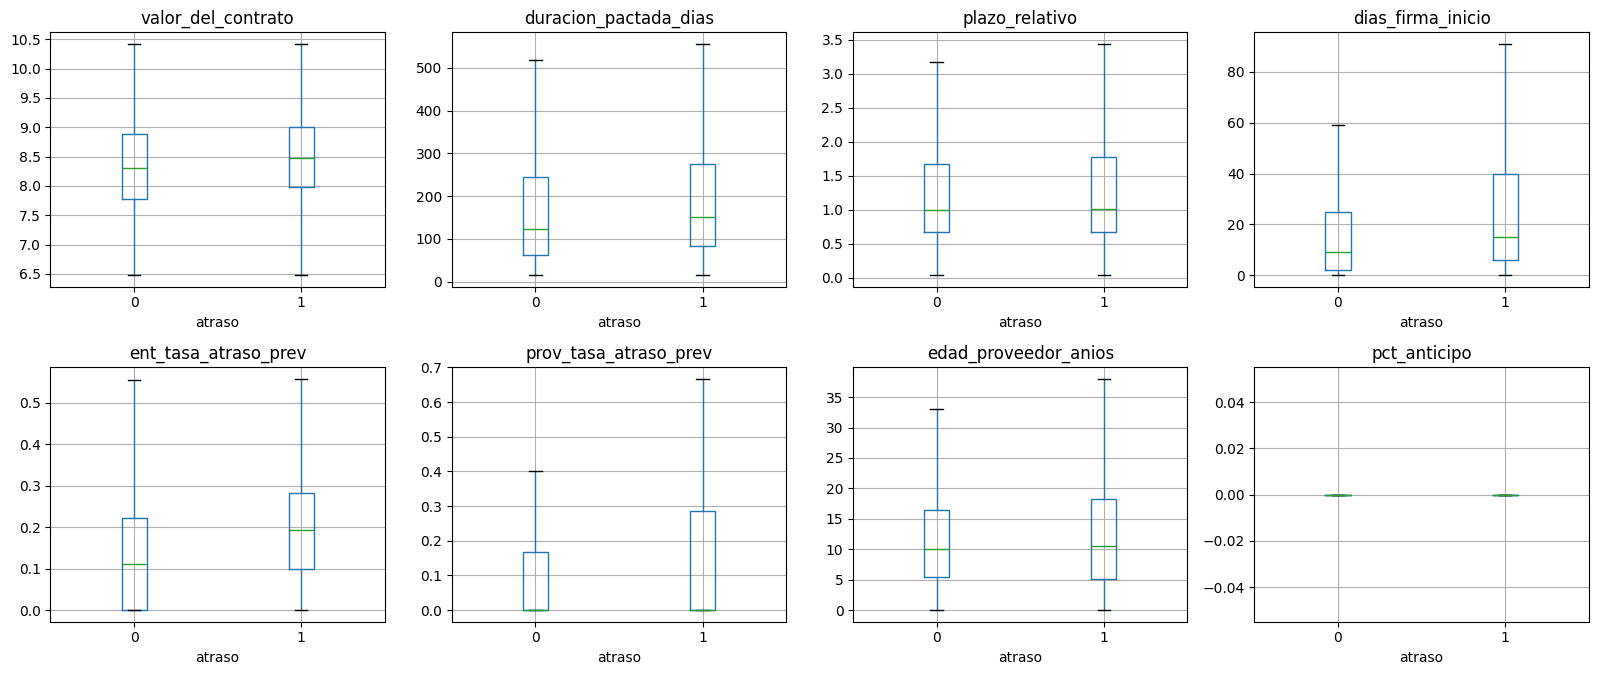

In [21]:
# Aquí hago un diagrama de caja por cada variable para comparar los contratos que se atrasaron con los que no.
# En cada gráfico, la caja 0 son los que no se atrasaron y la caja 1 los que sí.
# La línea del medio de la caja es la mediana, y la caja va desde el 25 hasta el 75 por ciento de los contratos.
# Si la caja 1 queda más arriba que la 0, esa variable suele ser más alta en los contratos que se atrasan.

# Estas son las variables que quiero comparar
CAJAS = ['valor_del_contrato', 'duracion_pactada_dias', 'plazo_relativo', 'dias_firma_inicio',
         'ent_tasa_atraso_prev', 'prov_tasa_atraso_prev', 'edad_proveedor_anios', 'pct_anticipo']

# Hago una copia con esas columnas y el atraso, para no tocar la tabla de entrenamiento
cajas = entrenamiento[CAJAS + [OBJETIVO]].copy()

# El valor en pesos es tan desigual que la caja no se alcanza a ver, entonces solo para el gráfico uso el logaritmo
cajas['valor_del_contrato'] = np.log10(cajas['valor_del_contrato'] + 1)

# Pongo los ocho gráficos en una sola figura de dos filas y cuatro columnas.
# showfliers en False es para no dibujar los puntos extremos y que se vea más limpio.
fig, ejes = plt.subplots(2, 4, figsize=(16, 7))
for eje, col in zip(ejes.ravel(), CAJAS):
    cajas.boxplot(column=col, by=OBJETIVO, showfliers=False, ax=eje)
    eje.set_title(col)
    eje.set_xlabel('atraso')
plt.suptitle('')
plt.tight_layout()
plt.show()

**Lectura.** Los contratos que se atrasan tienen la caja más arriba en los días entre la firma y el inicio (mediana de 15 días frente a 9), en la tasa de atraso previa de la entidad y en la del contratista, y un poco en el valor y el plazo. La edad del contratista casi no cambia, y el anticipo es 0 en el 98 % de los contratos, así que no ayuda a separar.

Ranking de variables con Orange

In [22]:
# Aquí hago el ranking de variables como en las clases, con cinco medidas.
# Info gain mide cuánto me ayuda conocer la variable para saber si el contrato se atrasa.
# Gain ratio es parecida, pero no premia a las variables que tienen muchas categorías.
# Gini es la medida que usa el árbol de decisión para escoger dónde cortar.
# ReliefF compara cada contrato con los contratos más parecidos a él.
# FCBF escoge las variables útiles que no repiten información, y a las repetidas les pone 0.
# En todas, entre más alto el número, más útil es la variable.
# Uso solo 3000 contratos al azar porque ReliefF se demora muchísimo con todos.

# Me quedo con las columnas permitidas y saco 3000 contratos al azar
X_ranking = entrenamiento.drop(columns=IGNORAR + [OBJETIVO], errors='ignore').sample(3000, random_state=SEMILLA)

# Separo las columnas de texto de las de números
texto_ranking = X_ranking.select_dtypes(exclude='number').columns
numeros_ranking = X_ranking.select_dtypes(include='number').columns

# Lleno los vacíos porque Orange se enreda con ellos.
# En las de texto pongo Sin dato y en las de números pongo la mediana.
X_ranking[texto_ranking] = X_ranking[texto_ranking].fillna('Sin dato')
X_ranking[numeros_ranking] = X_ranking[numeros_ranking].fillna(X_ranking[numeros_ranking].median())

# Paso el atraso a Si y No para que Orange lo entienda como categoría.
# Tomo el atraso de los mismos 3000 contratos que escogí arriba.
clase = entrenamiento.loc[X_ranking.index, OBJETIVO].map({0: 'No', 1: 'Si'}).to_frame()

# Convierto todo al formato de Orange y saco la lista de variables que va a calificar
tabla_orange = table_from_frames(X_ranking, clase, pd.DataFrame(index=X_ranking.index))
variables = tabla_orange.domain.attributes

# Calculo Info gain, Gain ratio y Gini variable por variable, igual que lo hace el profe.
# Voy guardando cada resultado en su lista con append.
nombres = []
puntajes_ganancia = []
puntajes_razon = []
puntajes_gini = []
for variable in variables:
    nombres.append(variable.name)
    puntajes_ganancia.append(float(score.InfoGain()(tabla_orange, variable)))
    puntajes_razon.append(float(score.GainRatio()(tabla_orange, variable)))
    puntajes_gini.append(float(score.Gini()(tabla_orange, variable)))

# Armo la tabla final. ReliefF y FCBF calculan todas las variables de una sola vez.
ranking = pd.DataFrame({
    'Variable': nombres,
    'Info. gain': puntajes_ganancia,
    'Gain ratio': puntajes_razon,
    'Gini': puntajes_gini,
    'ReliefF': score.ReliefF(random_state=SEMILLA)(tabla_orange),
    'FCBF': score.FCBF()(tabla_orange),
})

# Ordeno de la variable más útil a la menos útil según Gain ratio
ranking.sort_values('Gain ratio', ascending=False).round(4)

,Variable,Info. gain,Gain ratio,Gini,ReliefF,FCBF
9,espostconflicto,0.0010,0.0295,0.0002,0.0020,0.0029
25,ent_ratio_medio_prev,0.0183,0.0094,0.0073,0.0072,0.0142
24,ent_tasa_atraso_prev,0.0147,0.0076,0.0059,0.0288,0.0000
18,ciiu_seccion,0.0143,0.0063,0.0050,0.0440,0.0000
8,destino_gasto,0.0043,0.0058,0.0016,-0.0120,0.0000
21,prov_ratio_medio_prev,0.0045,0.0055,0.0021,0.0032,0.0000
20,prov_tasa_atraso_prev,0.0037,0.0051,0.0017,0.0200,0.0000
4,departamento,0.0197,0.0050,0.0073,0.0940,0.0000
3,sector,0.0130,0.0043,0.0043,0.0640,0.0000
27,dias_firma_inicio,0.0084,0.0042,0.0035,0.0277,0.0000


**Lectura.** Ordenado por Gain ratio, como en clase, la primera es espostconflicto, pero es una variable rara (el 99,6 % de los contratos dice No) y Gain ratio tiende a premiar ese tipo de variables; con Info gain casi no aporta. Después vienen las que salen altas en casi todas las medidas: la historia de la entidad (ent_ratio_medio_prev y ent_tasa_atraso_prev), el departamento, el sector y la sección CIIU. FCBF solo se queda con espostconflicto, ent_ratio_medio_prev y en_rues, porque las demás repiten información.

Preparar los datos para los modelos

In [23]:
# Los modelos solo entienden números, así que aquí dejo las tablas listas para ellos.
# La receta hace cuatro cosas:
# primero quita las columnas que no pueden entrar al modelo y también el atraso, porque eso es lo que quiero predecir,
# segundo les saca el logaritmo a las columnas con números muy desiguales,
# tercero llena los vacíos de las columnas de texto con Sin dato,
# y cuarto convierte cada columna de texto en varias columnas de 0 y 1.
# Por ejemplo, tipo de contrato se vuelve una columna para Obra, otra para Interventoría y otra para Consultoría,
# y cada contrato tiene 1 en la que le corresponde y 0 en las demás.
def preparar(tabla):
    X = tabla.drop(columns=IGNORAR + [OBJETIVO], errors='ignore').copy()
    X[TRANSFORMAR_LOG] = np.log1p(X[TRANSFORMAR_LOG])
    texto = X.select_dtypes(exclude='number').columns
    X[texto] = X[texto].fillna('Sin dato')
    return pd.get_dummies(X, columns=texto, dtype=float)

# Le aplico la receta al entrenamiento.
# Aquí guardo cuáles columnas quedaron y el promedio de cada una.
# Con esos promedios lleno los vacíos que quedan en las columnas de números.
# Por ejemplo, a un contratista sin historia le pongo la tasa de atraso promedio, y prov_sin_historia avisa que era un vacío.
X_ent = preparar(entrenamiento)
COLUMNAS = list(X_ent.columns)
MEDIAS = X_ent.mean()
X_ent = X_ent.fillna(MEDIAS)

# La prueba y el radar tienen que quedar exactamente con las mismas columnas que el entrenamiento.
# Puede pasar que en la prueba falte alguna categoría, entonces con reindex les pongo las mismas columnas
# en el mismo orden, y si alguna no existe la lleno con 0.
# Los vacíos los lleno con los promedios del entrenamiento, no con los de la prueba.
def alinear(tabla):
    X = preparar(tabla).reindex(columns=COLUMNAS, fill_value=0)
    return X.fillna(MEDIAS)

X_prueba = alinear(prueba)
X_radar = alinear(radar)

# Aquí guardo aparte la respuesta, o sea si cada contrato se atrasó o no
y_ent = entrenamiento[OBJETIVO].astype(int).values
y_prueba = prueba[OBJETIVO].astype(int).values

# Para la regresión logística hago lo mismo que el profe en su cuaderno de logística (drop_first=True):
# de cada variable de texto quito una categoría, que queda como referencia.
# Si dejo todas, las columnas de una misma variable siempre suman 1 y la logística no puede separar sus efectos.
# También quito en_rues, porque dice exactamente lo mismo que la columna ciiu_seccion_SIN_RUES.
CATEGORICAS = list(entrenamiento.drop(columns=IGNORAR + [OBJETIVO], errors='ignore').select_dtypes(exclude='number').columns)
REFERENCIAS = []
for col in CATEGORICAS:
    columnas_de_la_variable = sorted([c for c in COLUMNAS if c.startswith(col + '_')])
    REFERENCIAS.append(columnas_de_la_variable[0])
COLUMNAS_LOG = [c for c in COLUMNAS if c not in REFERENCIAS and c != 'en_rues']

# También guardo de qué variable original salió cada columna, porque lo necesito para explicar el modelo
ORIGEN = {}
for c in COLUMNAS:
    ORIGEN[c] = c
    for col in CATEGORICAS:
        if c.startswith(col + '_'):
            ORIGEN[c] = col

print('Columnas para los árboles, el bosque y la red:', len(COLUMNAS))
print('Columnas para la logística:', len(COLUMNAS_LOG))

Columnas para los árboles, el bosque y la red: 245
Columnas para la logística: 230


Receta para preparar los datos de cualquier periodo

In [24]:
# Todo lo que hice en la Parte 2 (recortar, plazo relativo, perfil del contratista, valor por día,
# columnas de 0 y 1 y llenar vacíos con promedios) usa números que salen de 2020-2023.
# Si valido en 2022 o en 2023 con esos números, el modelo ya "vio" un poco del año que estoy validando.
# Por eso armo una receta que repite toda la preparación, pero calculando todo solo con los años con los que aprende.
# La uso para las dos ventanas de validación y para el modelo que se despliega al final.
def preparar_periodo(aprende, otras):
    aprende = aprende.copy()
    otras = [t.copy() for t in otras]
    tablas = [aprende] + otras
    info = {'limites': {}}

    # 1. Recorte con el percentil 1 y el 99 de los años con los que aprende
    for col in RECORTAR:
        bajo, alto = aprende[col].quantile(0.01), aprende[col].quantile(0.99)
        info['limites'][col] = (bajo, alto)
        for t in tablas:
            t[col] = t[col].clip(bajo, alto)

    # 2. Plazo relativo con los grupos de valor y el plazo normal de esos mismos años
    cortes = aprende['valor_del_contrato'].quantile([0.2, 0.4, 0.6, 0.8]).values
    for t in tablas:
        t['banda_valor'] = np.digitize(t['valor_del_contrato'], cortes)
    mediana = aprende.groupby(['tipo_de_contrato', 'banda_valor'])['duracion_pactada_dias'].median()
    mediana.name = 'plazo_mediano_grupo'

    # 3. Plazo relativo, perfil del contratista y valor por día en cada tabla
    listas = []
    for t in tablas:
        t = t.drop(columns='plazo_mediano_grupo', errors='ignore').join(mediana, on=['tipo_de_contrato', 'banda_valor'])
        t['plazo_relativo'] = (t['duracion_pactada_dias'] / t['plazo_mediano_grupo']).clip(0, 5)
        t['perfil_contratista'] = perfil_contratista(t)
        t['valor_por_dia'] = t['valor_del_contrato'] / t['duracion_pactada_dias']
        listas.append(t)

    # 4. Columnas de 0 y 1 y vacíos llenos con los promedios de los años con los que aprende
    X_aprende = preparar(listas[0])
    columnas = list(X_aprende.columns)
    medias = X_aprende.mean()
    X_aprende = X_aprende.fillna(medias)
    X_otras = [preparar(t).reindex(columns=columnas, fill_value=0).fillna(medias) for t in listas[1:]]

    info.update({'cortes_valor': cortes, 'mediana_plazo': mediana, 'medias': medias, 'columnas': columnas})
    return X_aprende, X_otras, info

# Y esta saca las columnas de la logística para cualquier periodo: quito una categoría de referencia por variable y en_rues
def columnas_logistica(columnas):
    referencias = []
    for col in CATEGORICAS:
        de_la_variable = sorted([c for c in columnas if c.startswith(col + '_')])
        if de_la_variable:
            referencias.append(de_la_variable[0])
    return [c for c in columnas if c not in referencias and c != 'en_rues']

# Parte 3. Modelos supervisados: todos en la misma competencia

Aquí entreno los cuatro modelos que vimos en clase (regresión logística, árbol de decisión, random forest y red neuronal) y los pongo a competir entre ellos y contra la regla simple con las mismas reglas de juego. En la entrega 1 escogí todo con un solo año (2023). Ahora, como recomendó el profe, uso dos ventanas: aprendo con 2020-2021 y valido en 2022, y aprendo con 2020-2022 y valido en 2023. Promedio la curva de costo de las dos y con ese promedio escojo el umbral, los parámetros y el modelo final. La prueba (2024-2025) no la toco hasta la Parte 4.

Funciones de costo y elección del umbral

In [25]:
# Aquí escribo tres recetas que uso en el resto del cuaderno para medir cuánto le cuestan los errores a Cimiento.

# La primera calcula el costo de cada contrato.
# Si el contrato se atrasó y no le cobré recargo, cuesta 5.
# Si no se atrasó y sí le cobré recargo, cuesta 1.
# Si acerté, cuesta 0.
def costo_por_fila(real, recargo):
    return COSTO_FN * ((real == 1) & ~recargo) + COSTO_FP * ((real == 0) & recargo)

# La segunda saca el costo promedio y lo multiplica por mil, para hablar de costo por cada 1000 contratos como pide el brief
def costo_por_1000(real, recargo):
    return costo_por_fila(real, recargo).mean() * 1000

# La tercera busca el mejor umbral.
# El modelo da una probabilidad de atraso, y el umbral es a partir de qué probabilidad cobro recargo.
# Pruebo todos los umbrales desde 0.01 hasta 0.99, calculo el costo de cada uno y me quedo con el más barato.
# argmin me dice en qué posición está el costo más bajo.
def mejor_umbral(real, prob):
    umbrales = np.round(np.arange(0.01, 1.0, 0.01), 2)
    costos = [costo_por_1000(real, prob >= u) for u in umbrales]
    posicion = np.argmin(costos)
    return umbrales[posicion], costos[posicion]

Validación con dos ventanas de tiempo

In [26]:
# La prueba solo se puede usar al final, entonces para escoger necesito validar dentro de 2020-2023.
# En vez de un solo año uso dos ventanas, siempre aprendiendo con años anteriores y validando con el siguiente:
# - Ventana 1: aprendo con 2020 y 2021, y valido con 2022.
# - Ventana 2: aprendo con 2020, 2021 y 2022, y valido con 2023.
# En cada ventana preparo los datos solo con los años con los que aprende (la receta de arriba),
# y también saco el corte de la regla simple con esos mismos años.
VENTANAS = [('2020-2021 → 2022', [2020, 2021], 2022),
            ('2020-2022 → 2023', [2020, 2021, 2022], 2023)]

cortes_posibles = np.round(np.arange(0.01, 0.51, 0.01), 2)
VENTANAS_DATOS = []
for nombre, anios_aprende, anio_valida in VENTANAS:
    marca_a = entrenamiento_crudo['anio_firma'].isin(anios_aprende)
    marca_v = entrenamiento_crudo['anio_firma'] == anio_valida
    X_a, (X_v,), info = preparar_periodo(entrenamiento_crudo[marca_a], [entrenamiento_crudo[marca_v]])
    y_a = entrenamiento_crudo.loc[marca_a, OBJETIVO].astype(int).values
    y_v = entrenamiento_crudo.loc[marca_v, OBJETIVO].astype(int).values

    # Regla simple de la ventana: el corte más barato con los años con los que aprende
    regla_a = entrenamiento_crudo.loc[marca_a, 'ent_tasa_atraso_prev'].fillna(0).values
    regla_v = entrenamiento_crudo.loc[marca_v, 'ent_tasa_atraso_prev'].fillna(0).values
    corte = cortes_posibles[np.argmin([costo_por_1000(y_a, regla_a > c) for c in cortes_posibles])]

    VENTANAS_DATOS.append({'nombre': nombre, 'X_a': X_a, 'y_a': y_a, 'X_v': X_v, 'y_v': y_v,
                           'cols': info['columnas'], 'cols_log': columnas_logistica(info['columnas']),
                           'regla_v': regla_v, 'corte_regla': corte})
    print(nombre, '| aprende:', len(y_a), 'contratos | valida:', len(y_v), 'contratos, atraso', round(y_v.mean(), 3),
          '| corte de la regla:', corte)

2020-2021 → 2022 | aprende: 10378 contratos | valida: 8741 contratos, atraso 0.171 | corte de la regla: 0.07
2020-2022 → 2023 | aprende: 19119 contratos | valida: 10855 contratos, atraso 0.181 | corte de la regla: 0.06


Métricas para comparar los modelos (como el Test and Score de Orange)

In [27]:
# Aquí escribo la receta que mide cada forma de decidir con las mismas métricas que muestra Orange en Test and Score.
# El costo es la métrica principal, porque es lo que pierde Cimiento. Las demás ayudan a entender al modelo.
# AUC: qué tan bien ordena los contratos de más riesgo a menos riesgo. 0.5 es como lanzar una moneda.
# CA: exactitud, o sea en qué porcentaje de los contratos acertó.
# F1: junta la precisión y el recall en un solo número.
# Prec: de los contratos a los que les cobré recargo, cuántos sí se atrasaron.
# Recall: de los contratos que se atrasaron, a cuántos les cobré recargo. Es lo mismo que la sensibilidad.
# MCC: va de -1 a 1 y mira las cuatro casillas de la matriz de confusión al tiempo. 0 es como adivinar.
# Ojo: Orange calcula CA, F1, Prec, Recall y MCC con un umbral de 0.5.
# Yo los calculo con el umbral que escogí con los costos, porque esa es la decisión que tomaría Cimiento.
def medir(real, recargo, puntaje):
    vp = ((real == 1) & recargo).sum()
    fp = ((real == 0) & recargo).sum()
    fn = ((real == 1) & ~recargo).sum()
    vn = ((real == 0) & ~recargo).sum()
    # Si no le cobro recargo a nadie no se puede calcular la precisión, por eso queda vacía
    if vp + fp > 0:
        precision = vp / (vp + fp)
    else:
        precision = np.nan
    # El MCC tampoco se puede calcular cuando una de las cuatro sumas da cero
    denominador = np.sqrt(float(vp + fp) * float(vp + fn) * float(vn + fp) * float(vn + fn))
    if denominador > 0:
        mcc = (float(vp) * vn - float(fp) * fn) / denominador
    else:
        mcc = np.nan
    return {
        'Costo por 1.000': costo_por_1000(real, recargo),
        'AUC': roc_auc_score(real, puntaje) if puntaje is not None else np.nan,
        'CA': (vp + vn) / len(real),
        'F1': 2 * vp / (2 * vp + fp + fn),
        'Prec': precision,
        'Recall': vp / (vp + fn),
        'MCC': mcc,
    }

Regla simple y decisiones triviales

In [28]:
# Antes de los modelos necesito algo con qué compararlos.
# La regla simple de la ficha es: cobrar recargo si la entidad tiene una tasa de atraso previa alta.

# Tomo la tasa de atraso previa de la entidad. Si la entidad no tiene historia, le pongo 0,
# o sea que le cobro tarifa estándar. Abajo muestro por qué.
regla_ent = entrenamiento['ent_tasa_atraso_prev'].fillna(0).values
regla_prueba = prueba['ent_tasa_atraso_prev'].fillna(0).values

# Pruebo cortes desde 0.01 hasta 0.50, de uno en uno, y escojo el que salga más barato en el entrenamiento.
# La regla es "más del corte", como la escribimos en la ficha.
cortes = np.round(np.arange(0.01, 0.51, 0.01), 2)
costos_regla = [costo_por_1000(y_ent, regla_ent > c) for c in cortes]
CORTE_REGLA = cortes[np.argmin(costos_regla)]

# Muestro la regla y su costo.
# También muestro las dos decisiones triviales que pide el brief:
# no cobrarle recargo a nadie, y cobrarle recargo a todos.
print('Regla: recargo si la entidad se atrasó en más del', round(CORTE_REGLA * 100), '% de sus contratos anteriores')
print('Costo de la regla en entrenamiento:', round(min(costos_regla), 1))
print('Tarifa estándar a todos:', round(costo_por_1000(y_ent, np.zeros(len(y_ent), dtype=bool)), 1))
print('Recargo a todos:', round(costo_por_1000(y_ent, np.ones(len(y_ent), dtype=bool)), 1))

# Las entidades sin historia se atrasan menos de 1 en 6, por eso con ellas conviene la tarifa estándar
sin_historia = entrenamiento['ent_tasa_atraso_prev'].isna()
print('\nEntidades sin historia:', sin_historia.sum(), 'contratos | tasa de atraso:', round(entrenamiento.loc[sin_historia, OBJETIVO].mean(), 3))

Regla: recargo si la entidad se atrasó en más del 6 % de sus contratos anteriores
Costo de la regla en entrenamiento: 661.5
Tarifa estándar a todos: 878.3
Recargo a todos: 824.3

Entidades sin historia: 6223 contratos | tasa de atraso: 0.139


**Lectura.** El corte que menos cuesta en el entrenamiento es 6 %: recargo si la entidad se atrasó en más del 6 % de sus contratos anteriores. Cuesta 661,5 por cada 1.000 contratos, menos que cobrar recargo a todos (824,3) o tarifa estándar a todos (878,3). Las entidades sin historia se atrasan el 13,9 %, menos de 1 en 6, así que tiene sentido dejarlas con tarifa estándar.

El z-score para la logística y la red

In [29]:
# La logística y la red neuronal necesitan que todas las variables estén en la misma escala,
# así que les hago el z-score igual que el profe en sus cuadernos de logística y de redes:
# a cada columna le resto su promedio (centro) y la divido por su desviación estándar (escala).
# El centro y la escala se sacan solo con los contratos con los que el modelo aprende,
# y con esos mismos números se transforman los contratos que predice.
# replace(0, 1) es para no dividir por cero en las columnas que no cambian.
# El árbol y el random forest no lo necesitan, porque cortan por umbrales y la escala no les cambia nada.
USAN_ZSCORE = ['Logística', 'Red neuronal']

def centro_y_escala(X_aprende):
    centro = X_aprende.mean()
    escala = X_aprende.std().replace(0, 1)
    return centro, escala

Receta para probar un modelo en las dos ventanas

In [30]:
# Esta receta toma un modelo, lo entrena y lo valida en las dos ventanas, y promedia las dos curvas de costo.
# La curva de costo es el costo por cada 1.000 contratos con cada umbral posible, de 0.01 a 0.99.
# El umbral que escojo es el más barato en la curva promedio, no en un solo año.
# crear_modelo es una receta que me arma el modelo desde cero, para que cada ventana empiece limpia.
UMBRALES = np.round(np.arange(0.01, 1.0, 0.01), 2)

def probar_en_ventanas(crear_modelo, usa_logistica=False, usa_zscore=False):
    curvas, probs, aucs, modelos_ventana = [], [], [], []
    for v in VENTANAS_DATOS:
        cols = v['cols_log'] if usa_logistica else v['cols']
        X_a, X_v = v['X_a'][cols], v['X_v'][cols]
        if usa_zscore:
            centro, escala = centro_y_escala(X_a)
            X_a = (X_a - centro) / escala
            X_v = (X_v - centro) / escala
        modelo = crear_modelo()
        modelo.fit(X_a, v['y_a'])
        prob = modelo.predict_proba(X_v)[:, 1]
        curvas.append([costo_por_1000(v['y_v'], prob >= u) for u in UMBRALES])
        probs.append(prob)
        aucs.append(roc_auc_score(v['y_v'], prob))
        modelos_ventana.append(modelo)
    curva = np.mean(curvas, axis=0)
    posicion = np.argmin(curva)
    return {'umbral': UMBRALES[posicion], 'costo': curva[posicion], 'curva': curva,
            'costo_2022': curvas[0][posicion], 'costo_2023': curvas[1][posicion],
            'auc': np.mean(aucs), 'probs': probs, 'modelos': modelos_ventana}

Red neuronal: escoger el tamaño y la activación

In [31]:
# A la red le busco el tamaño y la activación, igual que con el número de grupos de K-means: pruebo y comparo.
# Cada neurona es como una regresión logística pequeña, y varias juntas pueden seguir curvas que una recta no alcanza.
# Tamaños que pruebo: 2 es una capa con 2 neuronas, como el ejemplo del profe; 16 es una capa con 16;
# y 32, 16 son dos capas, la primera con 32 y la segunda con 16.
# Activaciones: la logística es la curva en S, y la ReLU apaga los valores negativos. Son las mismas de Orange.
OPCIONES_CAPAS = [(2,), (16,), (32, 16)]
OPCIONES_ACTIVACION = ['logistic', 'relu']

# La red con las opciones del widget de Orange. Uso Adam porque tengo muchos datos (según la clase, L-BFGS-B es para pocos).
# alpha es la regularización, max_iter el máximo de vueltas y early_stopping hace que pare cuando deja de mejorar.
def crear_red(capas, activacion):
    return MLPClassifier(hidden_layer_sizes=capas, activation=activacion, solver='adam',
                         alpha=0.0001, max_iter=200, early_stopping=True, random_state=SEMILLA)

filas = []
resultados_red = {}
for capas in OPCIONES_CAPAS:
    for activacion in OPCIONES_ACTIVACION:
        r = probar_en_ventanas(lambda: crear_red(capas, activacion), usa_zscore=True)
        resultados_red[(capas, activacion)] = r
        filas.append({'capas': capas, 'activación': activacion, 'umbral': r['umbral'],
                      'costo 2022': r['costo_2022'], 'costo 2023': r['costo_2023'],
                      'costo promedio': r['costo'], 'AUC promedio': r['auc']})

tabla_red = pd.DataFrame(filas)
mejor = tabla_red['costo promedio'].idxmin()
CAPAS_RED = tabla_red.loc[mejor, 'capas']
ACTIVACION_RED = tabla_red.loc[mejor, 'activación']
print('Red escogida:', CAPAS_RED, ACTIVACION_RED)
tabla_red.round(3)

Red escogida: (16,) relu


,capas,activación,umbral,costo 2022,costo 2023,costo promedio,AUC promedio
0,"(2,)",logistic,0.28,719.941,701.336,710.638,0.628
1,"(2,)",relu,0.15,704.496,702.810,703.653,0.596
2,"(16,)",logistic,0.20,656.332,655.182,655.757,0.651
3,"(16,)",relu,0.15,646.150,653.155,649.653,0.654
4,"(32, 16)",logistic,0.17,829.081,666.145,747.613,0.623
5,"(32, 16)",relu,0.13,647.409,652.787,650.098,0.655


**Lectura.** La red más barata es la de una capa con 16 neuronas y ReLU: cuesta 649,7 en promedio, con umbral de 0,15. La de dos capas (32 y 16) con ReLU queda casi igual (650,1), así que agregar la segunda capa no ayuda. Con activación logística siempre queda peor, y la de dos capas con logística se dañó en 2022: le cobró recargo a todos (829,1). La de 2 neuronas es la peor, porque con tan pocas no alcanza a aprender los patrones.

Regresión logística: ¿Ridge, Lasso o Elastic Net?

In [32]:
# Como vimos en la clase de regularización, hay varias formas de castigar los coeficientes grandes:
# - Ridge (L2): los achica, pero nunca los deja en cero.
# - Lasso (L1): deja en cero los de las variables que no aportan, y queda un modelo más corto y fácil de explicar.
# - Elastic Net: mezcla las dos. Con l1_ratio = 0.5 es mitad Ridge y mitad Lasso.
# C es la fuerza de la regularización en Orange: entre más pequeño, más castigo.
# Pruebo las tres con tres valores de C y escojo la más barata en el promedio de las dos ventanas.
OPCIONES_LOGISTICA = [('Ridge (L2)', 0.01), ('Ridge (L2)', 0.1), ('Ridge (L2)', 1),
                      ('Lasso (L1)', 0.01), ('Lasso (L1)', 0.1), ('Lasso (L1)', 1),
                      ('Elastic Net', 0.01), ('Elastic Net', 0.1), ('Elastic Net', 1)]

# Cada una necesita su forma de ajustar los pesos (solver). Elastic Net es la más lenta, puede tardar unos minutos.
def crear_logistica(regularizacion, c):
    if regularizacion == 'Lasso (L1)':
        return LogisticRegression(penalty='l1', C=c, solver='liblinear', max_iter=2000)
    if regularizacion == 'Elastic Net':
        return LogisticRegression(penalty='elasticnet', l1_ratio=0.5, C=c, solver='saga', max_iter=2000, random_state=SEMILLA)
    return LogisticRegression(C=c, max_iter=2000)

filas = []
resultados_log = {}
for regularizacion, c in OPCIONES_LOGISTICA:
    r = probar_en_ventanas(lambda: crear_logistica(regularizacion, c), usa_logistica=True, usa_zscore=True)
    resultados_log[(regularizacion, c)] = r
    filas.append({'regularización': regularizacion, 'C': c, 'umbral': r['umbral'],
                  'costo 2022': r['costo_2022'], 'costo 2023': r['costo_2023'],
                  'costo promedio': r['costo'], 'AUC promedio': r['auc'],
                  'variables con coeficiente (ventana 2)': (r['modelos'][1].coef_[0] != 0).sum()})

tabla_log = pd.DataFrame(filas)
mejor = tabla_log['costo promedio'].idxmin()
REGULARIZACION_LOG = tabla_log.loc[mejor, 'regularización']
C_LOG = tabla_log.loc[mejor, 'C']
print('Logística escogida:', REGULARIZACION_LOG, '| C =', C_LOG)
tabla_log.round(3)

Logística escogida: Elastic Net | C = 0.01


,regularización,C,umbral,costo 2022,costo 2023,costo promedio,AUC promedio,variables con coeficiente (ventana 2)
0,Ridge (L2),0.01,0.17,674.637,651.681,663.159,0.645,222
1,Ridge (L2),0.10,0.17,678.412,662.552,670.482,0.643,222
2,Ridge (L2),1.00,0.19,675.666,662.828,669.247,0.643,222
3,Lasso (L1),0.01,0.17,663.654,654.445,659.050,0.643,53
4,Lasso (L1),0.10,0.16,666.285,654.445,660.365,0.648,187
5,Lasso (L1),1.00,0.17,678.298,660.801,669.550,0.644,214
6,Elastic Net,0.01,0.16,668.917,646.246,657.581,0.649,106
7,Elastic Net,0.10,0.17,671.891,655.643,663.767,0.646,200
8,Elastic Net,1.00,0.19,676.353,663.289,669.821,0.644,221


**Lectura.** Otra vez gana Elastic Net con C = 0,01 (657,6 en promedio), que deja vivas 106 de las 230 columnas. Lasso con el mismo C usa solo 53 columnas y cuesta casi lo mismo (659,1), y el mejor Ridge cuesta 663,2. En las tres gana el castigo más fuerte, porque muchas columnas (departamentos, segmentos UNSPSC) solo meten ruido.

Árbol y random forest: escoger el mínimo de contratos por hoja

In [33]:
# Al árbol y al bosque les pruebo el mínimo de contratos por hoja, que es lo que evita que se aprendan los datos de memoria.
# Para el árbol uso la regla de clase: el mínimo por hoja debe estar entre el 1 % y el 5 % de los contratos.
# Cuando le paso un número con decimales (0.01), sklearn lo entiende como ese porcentaje de los contratos.
# También dejo los 50 contratos que usé en la entrega 1, para comparar.
# Para el bosque pruebo 10, 20 y 50 contratos por hoja, siempre con 200 árboles.
OPCIONES_HOJA_ARBOL = [50, 0.01, 0.02, 0.05]
OPCIONES_HOJA_BOSQUE = [10, 20, 50]

filas = []
resultados_arbol = {}
for hoja in OPCIONES_HOJA_ARBOL:
    r = probar_en_ventanas(lambda: DecisionTreeClassifier(max_depth=5, min_samples_leaf=hoja, random_state=SEMILLA))
    resultados_arbol[hoja] = r
    filas.append({'modelo': 'Árbol', 'mínimo por hoja': hoja, 'umbral': r['umbral'], 'costo 2022': r['costo_2022'],
                  'costo 2023': r['costo_2023'], 'costo promedio': r['costo'], 'AUC promedio': r['auc']})

resultados_bosque = {}
for hoja in OPCIONES_HOJA_BOSQUE:
    r = probar_en_ventanas(lambda: RandomForestClassifier(n_estimators=200, min_samples_leaf=hoja, random_state=SEMILLA))
    resultados_bosque[hoja] = r
    filas.append({'modelo': 'Random Forest', 'mínimo por hoja': hoja, 'umbral': r['umbral'], 'costo 2022': r['costo_2022'],
                  'costo 2023': r['costo_2023'], 'costo promedio': r['costo'], 'AUC promedio': r['auc']})

tabla_arboles = pd.DataFrame(filas)
HOJA_ARBOL = min(resultados_arbol, key=lambda h: resultados_arbol[h]['costo'])
HOJA_BOSQUE = min(resultados_bosque, key=lambda h: resultados_bosque[h]['costo'])
print('Árbol escogido: mínimo por hoja', HOJA_ARBOL, '| Bosque escogido: mínimo por hoja', HOJA_BOSQUE)
tabla_arboles.round(3)

Árbol escogido: mínimo por hoja 0.05 | Bosque escogido: mínimo por hoja 10


,modelo,mínimo por hoja,umbral,costo 2022,costo 2023,costo promedio,AUC promedio
0,Árbol,50.00,0.14,695.687,654.353,675.020,0.620
1,Árbol,0.01,0.11,695.687,631.414,663.551,0.642
2,Árbol,0.02,0.13,674.294,644.956,659.625,0.641
3,Árbol,0.05,0.19,673.950,634.915,654.433,0.646
4,Random Forest,10.00,0.18,623.842,583.234,603.538,0.683
5,Random Forest,20.00,0.19,631.735,599.724,615.730,0.679
6,Random Forest,50.00,0.18,634.367,613.634,624.001,0.674


**Lectura.** En el árbol gana la regla de clase: con un mínimo del 5 % de los contratos por hoja cuesta 654,4, y con los 50 contratos que usé en la entrega 1 cuesta 675,0. Con hojas tan pequeñas el árbol se aprendía detalles de los datos que no se repiten. En el bosque pasa lo contrario: gana el mínimo más pequeño, 10 contratos por hoja (603,5), porque cada árbol puede ser muy detallado y al votar entre 200 se corrigen los errores.

Los cuatro modelos con su mejor configuración

In [34]:
# Aquí dejo armados los cuatro modelos con la configuración que ganó en las dos ventanas.
# CREAR guarda la receta de cada uno, porque más adelante vuelvo a armar el modelo final para desplegarlo.
CREAR = {
    'Logística': lambda: crear_logistica(REGULARIZACION_LOG, C_LOG),
    'Árbol': lambda: DecisionTreeClassifier(max_depth=5, min_samples_leaf=HOJA_ARBOL, random_state=SEMILLA),
    'Random Forest': lambda: RandomForestClassifier(n_estimators=200, min_samples_leaf=HOJA_BOSQUE, random_state=SEMILLA),
    'Red neuronal': lambda: crear_red(CAPAS_RED, ACTIVACION_RED),
}
modelos = {nombre: crear() for nombre, crear in CREAR.items()}
NOMBRES_MODELOS = list(modelos)

# Cada modelo usa sus columnas: la logística las que dejé sin referencia, y los demás todas
COLUMNAS_MODELO = {'Logística': COLUMNAS_LOG, 'Árbol': COLUMNAS, 'Random Forest': COLUMNAS, 'Red neuronal': COLUMNAS}

# Los resultados en las dos ventanas ya los tengo de las búsquedas de arriba, no hace falta volver a entrenar
VALIDACION = {
    'Logística': resultados_log[(REGULARIZACION_LOG, C_LOG)],
    'Árbol': resultados_arbol[HOJA_ARBOL],
    'Random Forest': resultados_bosque[HOJA_BOSQUE],
    'Red neuronal': resultados_red[(CAPAS_RED, ACTIVACION_RED)],
}
umbrales = {nombre: VALIDACION[nombre]['umbral'] for nombre in NOMBRES_MODELOS}
costo_val = {nombre: VALIDACION[nombre]['costo'] for nombre in NOMBRES_MODELOS}

# Para las partes que miran 2023 (deciles, segmentos) guardo las probabilidades de la ventana 2
prob_val = {nombre: VALIDACION[nombre]['probs'][1] for nombre in NOMBRES_MODELOS}
y_val = VENTANAS_DATOS[1]['y_v']
es_2023 = (entrenamiento['anio_firma'] == 2023).values
for nombre in NOMBRES_MODELOS:
    print(nombre, '| umbral:', umbrales[nombre], '| costo promedio:', round(costo_val[nombre], 1))

Logística | umbral: 0.16 | costo promedio: 657.6
Árbol | umbral: 0.19 | costo promedio: 654.4
Random Forest | umbral: 0.18 | costo promedio: 603.5
Red neuronal | umbral: 0.15 | costo promedio: 649.7


Tabla de validación (promedio de 2022 y 2023) y elección del modelo final

In [35]:
# Aquí junto en una sola tabla todas las formas de decidir, con las mismas métricas,
# medidas en cada ventana y promediadas. Las triviales y la regla simple también entran.
filas = {}
for nombre in ['Tarifa estándar a todos', 'Recargo a todos', 'Regla simple'] + NOMBRES_MODELOS:
    medidas_ventanas = []
    for k, v in enumerate(VENTANAS_DATOS):
        n = len(v['y_v'])
        if nombre == 'Tarifa estándar a todos':
            m = medir(v['y_v'], np.zeros(n, dtype=bool), None)
        elif nombre == 'Recargo a todos':
            m = medir(v['y_v'], np.ones(n, dtype=bool), None)
        elif nombre == 'Regla simple':
            m = medir(v['y_v'], v['regla_v'] > v['corte_regla'], v['regla_v'])
        else:
            prob = VALIDACION[nombre]['probs'][k]
            m = medir(v['y_v'], prob >= umbrales[nombre], prob)
        medidas_ventanas.append(m)
    fila = pd.DataFrame(medidas_ventanas).mean()
    fila['Costo 2022'] = medidas_ventanas[0]['Costo por 1.000']
    fila['Costo 2023'] = medidas_ventanas[1]['Costo por 1.000']
    filas[nombre] = fila

validacion = pd.DataFrame(filas).T
validacion = validacion.rename(columns={'Costo por 1.000': 'Costo promedio'})
validacion.insert(0, 'Umbral', pd.Series(umbrales))
costo_val['Regla simple'] = validacion.loc['Regla simple', 'Costo promedio']

# El modelo final es el que tenga el costo promedio más bajo. La prueba no la toco para esto.
MEJOR = min(NOMBRES_MODELOS, key=lambda nombre: costo_val[nombre])
UMBRAL_MEJOR = umbrales[MEJOR]
print('Modelo final:', MEJOR, '| umbral:', UMBRAL_MEJOR, '\n')
COLUMNAS_VAL = ['Umbral', 'Costo 2022', 'Costo 2023', 'Costo promedio', 'AUC', 'CA', 'F1', 'Prec', 'Recall', 'MCC']
validacion[COLUMNAS_VAL].sort_values('Costo promedio').round(3)

Modelo final: Random Forest | umbral: 0.18 



,Umbral,Costo 2022,Costo 2023,Costo promedio,AUC,CA,F1,Prec,Recall,MCC
Random Forest,0.18,623.842,583.234,603.538,0.683,0.624,0.387,0.272,0.675,0.222
Red neuronal,0.15,646.150,653.155,649.653,0.654,0.547,0.358,0.239,0.720,0.175
Regla simple,NaN,659.192,647.536,653.364,0.646,0.525,0.355,0.233,0.745,0.171
Árbol,0.19,673.950,634.915,654.433,0.646,0.565,0.359,0.244,0.689,0.175
Logística,0.16,668.917,646.246,657.581,0.649,0.549,0.354,0.237,0.705,0.168
Recargo a todos,NaN,829.081,819.438,824.260,NaN,0.176,0.299,0.176,1.000,NaN
Tarifa estándar a todos,NaN,854.593,902.810,878.702,NaN,0.824,0.000,NaN,0.000,NaN


**Lectura.** El random forest es el más barato en las dos ventanas: 623,8 en 2022 y 583,2 en 2023, frente a 659,2 y 647,5 de la regla. Es el único que le gana a la regla en los dos años. La red le gana en 2022 pero pierde en 2023, y el árbol y la logística quedan por encima de la regla en el promedio. Mi modelo final es el random forest con umbral de 0,18, escogido sin mirar la prueba.

Curva de costo promedio según el umbral (los cuatro modelos)

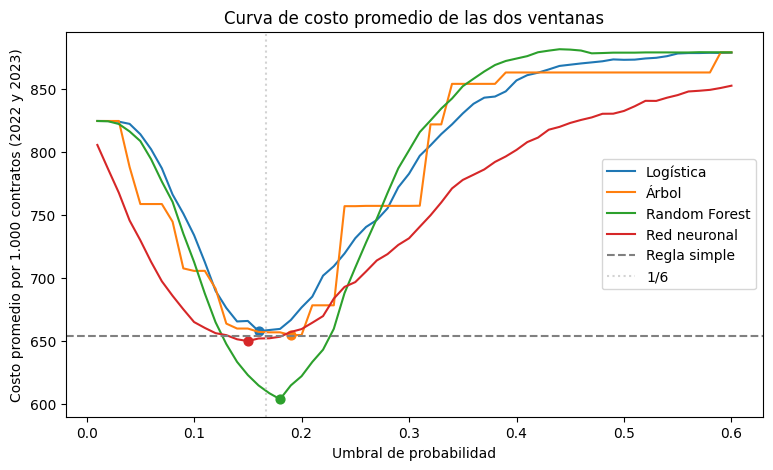

In [36]:
# Esta es la curva de costo promedio de las dos ventanas, la que uso para escoger el umbral.
# Si el umbral es muy bajo le cobro recargo a casi todos y pago muchos falsos positivos.
# Si es muy alto casi no cobro recargo y pago muchos atrasos sin cubrir, que son los más caros.
# La línea gris es el costo promedio de la regla simple, para ver qué modelos la superan.
hasta = 60  # muestro los umbrales de 0.01 a 0.60, que es donde pasa todo

plt.figure(figsize=(9, 5))
for nombre in NOMBRES_MODELOS:
    plt.plot(UMBRALES[:hasta], VALIDACION[nombre]['curva'][:hasta], label=nombre)
    plt.scatter(umbrales[nombre], costo_val[nombre], s=40)

plt.axhline(costo_val['Regla simple'], color='gray', linestyle='--', label='Regla simple')
plt.axvline(1 / 6, color='lightgray', linestyle=':', label='1/6')
plt.xlabel('Umbral de probabilidad')
plt.ylabel('Costo promedio por 1.000 contratos (2022 y 2023)')
plt.title('Curva de costo promedio de las dos ventanas')
plt.legend()
plt.show()

**Lectura.** Las cuatro curvas tienen su punto más bajo entre 0,15 y 0,19, cerca de 1/6, que es lo esperado con costos de 5 a 1. Solo la curva del random forest queda claramente por debajo de la línea de la regla; las otras tres quedan casi encima de ella.

# Parte 4. Evaluación: los cuatro modelos en la prueba (2024-2025)

Ya están escogidos el modelo final, los umbrales y el corte de la regla. Ahora los cuatro modelos aprenden con todo 2020-2023 y se miden una sola vez en la prueba.

Entrenar con todo 2020-2023 y predecir la prueba y el radar

In [37]:
# Con los umbrales ya escogidos, cada modelo aprende con todo el entrenamiento, de 2020 a 2023.
# Así aprende también de 2023, que es lo más reciente.
# Después calculo la probabilidad de atraso de los contratos de prueba y de los del radar.
# El z-score de la logística y la red ahora sale de todo 2020-2023, y lo guardo porque la app lo necesita.
prob_prueba = {}
prob_radar = {}
ZSCORE_FINAL = {}
for nombre, modelo in modelos.items():
    cols = COLUMNAS_MODELO[nombre]
    X_aprende, X_p, X_r = X_ent[cols], X_prueba[cols], X_radar[cols]
    if nombre in USAN_ZSCORE:
        centro, escala = centro_y_escala(X_aprende)
        ZSCORE_FINAL[nombre] = (centro, escala)
        X_aprende = (X_aprende - centro) / escala
        X_p = (X_p - centro) / escala
        X_r = (X_r - centro) / escala
    modelo.fit(X_aprende, y_ent)
    prob_prueba[nombre] = modelo.predict_proba(X_p)[:, 1]
    prob_radar[nombre] = modelo.predict_proba(X_r)[:, 1]

# Decisión de cada forma de decidir en la prueba: si cobra recargo o no, y su puntaje para el AUC
n_prueba = len(y_prueba)
recargo_regla = regla_prueba > CORTE_REGLA
costo_regla = costo_por_fila(y_prueba, recargo_regla)
decisiones = {
    'Tarifa estándar a todos': (np.zeros(n_prueba, dtype=bool), None),
    'Recargo a todos': (np.ones(n_prueba, dtype=bool), None),
    'Regla simple': (recargo_regla, regla_prueba),
}
for nombre in NOMBRES_MODELOS:
    decisiones[nombre] = (prob_prueba[nombre] >= umbrales[nombre], prob_prueba[nombre])
print('Listo')

Listo


Tabla de resultados en la prueba (Test and Score)

In [38]:
# Esta es la tabla principal del proyecto. Aquí uso la prueba por primera vez, con todos los modelos al mismo tiempo.
# Cada fila es una forma de decidir y cada columna una métrica, como en el Test and Score de Orange.
tabla_final = {}
for nombre, (recargo, puntaje) in decisiones.items():
    tabla_final[nombre] = medir(y_prueba, recargo, puntaje)
tabla_final = pd.DataFrame(tabla_final).T
tabla_final.sort_values('Costo por 1.000').round(3)

,Costo por 1.000,AUC,CA,F1,Prec,Recall,MCC
Random Forest,716.034,0.699,0.680,0.449,0.371,0.568,0.248
Logística,748.217,0.653,0.641,0.424,0.335,0.575,0.203
Regla simple,753.668,0.624,0.560,0.407,0.294,0.658,0.159
Red neuronal,755.639,0.661,0.659,0.424,0.346,0.548,0.210
Recargo a todos,770.832,NaN,0.229,0.373,0.229,1.000,NaN
Árbol,798.782,0.644,0.663,0.403,0.339,0.497,0.186
Tarifa estándar a todos,1145.839,NaN,0.771,0.000,NaN,0.000,NaN


**Lectura.** En la prueba el random forest es el más barato (716,0 por cada 1.000 contratos) y el mejor de los cuatro modelos en AUC (0,699), CA (0,680), F1 (0,449), precisión (0,371) y MCC (0,248). La regla cuesta 753,7. La logística le gana por poco (748,2), la red queda casi igual (755,6) y el árbol queda peor que cobrarle recargo a todos (798,8 frente a 770,8).

La exactitud (CA) no sirve para escoger aquí: lo más "exacto" sería no cobrarle recargo a nadie (0,771), y es lo más caro (1.145,8) porque deja pasar todos los atrasos. Por eso uso el costo. La regla es la que más atrasos detecta (recall de 0,658), pero le cobra recargo a la mitad de los contratos y por eso tiene la precisión más baja (0,294).

Las métricas de los modelos lado a lado

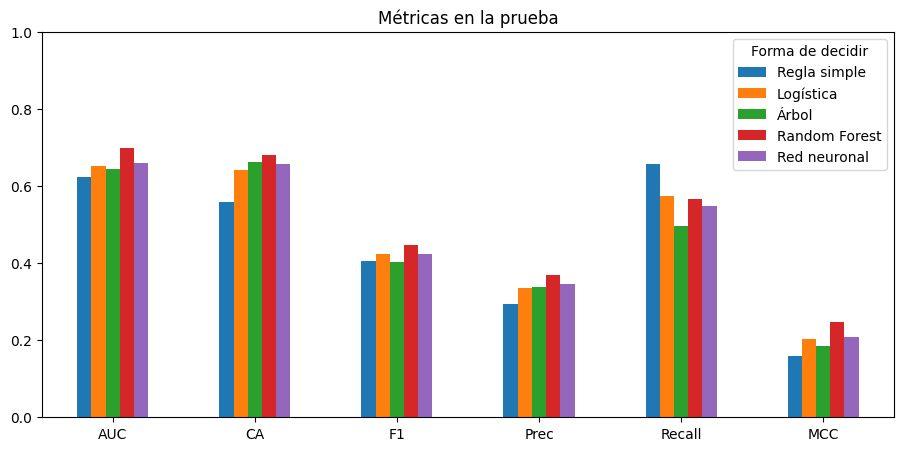

In [39]:
# Aquí pongo en barras las métricas de la regla y los cuatro modelos, como la gráfica de logística contra red de la clase.
# Todas van de 0 a 1 (el MCC podría ser negativo, pero aquí no pasa) y entre más alta la barra, mejor.
# El costo no va aquí porque está en otra escala; ya está en la tabla de arriba.
comparar = tabla_final.loc[['Regla simple'] + NOMBRES_MODELOS, ['AUC', 'CA', 'F1', 'Prec', 'Recall', 'MCC']]
comparar.T.plot.bar(figsize=(11, 5))
plt.ylim(0, 1)
plt.title('Métricas en la prueba')
plt.xticks(rotation=0)
plt.legend(title='Forma de decidir')
plt.show()

**Lectura.** Entre los cuatro modelos, el random forest tiene la barra más alta en todo menos en recall, donde la logística lo pasa por poco (0,575 frente a 0,568). La red y la logística quedan muy parecidas, así que en estos datos la red no le saca ventaja a la logística como en el ejemplo de clase.

¿El resultado se sostiene? La prueba partida en batches

In [40]:
# Una sola cifra puede salir buena por suerte. En los cuadernos de clase eso se revisa con varios batches:
# se mide el modelo en cada uno y se mira la media y la DE.
# Aquí hago lo mismo con la prueba: la parto en 5 batches con StratifiedKFold, para que cada uno tenga
# la misma proporción de atrasos, y mido cada forma de decidir en cada batch.
# No entreno nada aquí: los modelos ya están entrenados, solo los mido en cinco pedazos de la prueba.
batches_prueba = StratifiedKFold(n_splits=K, shuffle=True, random_state=SEMILLA)
filas = []
for numero, (_, pedazo) in enumerate(batches_prueba.split(np.zeros(n_prueba), y_prueba), start=1):
    for nombre in ['Regla simple'] + NOMBRES_MODELOS:
        recargo, puntaje = decisiones[nombre]
        medidas = medir(y_prueba[pedazo], recargo[pedazo], puntaje[pedazo])
        medidas['Batch'] = numero
        medidas['Forma de decidir'] = nombre
        filas.append(medidas)
por_batch = pd.DataFrame(filas)

# Costo de cada forma de decidir en cada batch: una fila por batch y una columna por forma de decidir
costo_por_batch = por_batch.pivot(index='Batch', columns='Forma de decidir', values='Costo por 1.000')
display(costo_por_batch.round(1))

# Media y DE de cada métrica en los 5 batches, como en los cuadernos de clase
METRICAS = ['Costo por 1.000', 'AUC', 'CA', 'F1', 'Prec', 'Recall', 'MCC']
por_batch.groupby('Forma de decidir')[METRICAS].agg(['mean', 'std']).round(3)

Forma de decidir,Logística,Random Forest,Red neuronal,Regla simple,Árbol
Batch,,,,,
1,756.2,731.2,755.6,770.1,805.7
2,751.5,701.7,757.3,728.3,797.0
3,757.3,726.6,773.8,775.0,815.6
4,755.0,724.8,755.0,756.2,801.4
5,721.1,695.9,736.4,738.8,774.1


Costo por 1.000            AUC            CA            F1  \
                            mean     std   mean    std   mean    std   mean   
Forma de decidir                                                              
Logística                748.217  15.325  0.653  0.011  0.641  0.007  0.423   
Random Forest            716.034  16.077  0.699  0.009  0.680  0.006  0.449   
Red neuronal             755.639  13.259  0.661  0.006  0.659  0.008  0.424   
Regla simple             753.668  19.970  0.624  0.009  0.560  0.009  0.407   
Árbol                    798.782  15.398  0.644  0.008  0.663  0.007  0.403   

                          Prec        Recall           MCC         
                    std   mean    std   mean    std   mean    std  
Forma de decidir                                                   
Logística         0.008  0.335  0.007  0.575  0.014  0.203  0.012  
Random Forest     0.009  0.371  0.007  0.568  0.016  0.248  0.012  
Red neuronal      0.007  0.346  0.007  0.548  0.015  0.210  0.011  
Regla simple      0.009  0.294  0.007  0.658  0.014  0.159  0.017  
Árbol             0.009  0.339  0.008  0.497  0.014  0.186  0.013

¿Cuáles modelos le ganan a la regla simple?

In [41]:
# Para cada modelo resto su costo menos el de la regla en cada batch.
# Si la diferencia es negativa, ese batch le costó menos a Cimiento con el modelo.
# Si el modelo le gana a la regla en los 5 batches, la ventaja es firme.
# Si unas veces gana y otras pierde, no puedo decir que sea mejor que la regla.
filas = []
for nombre in NOMBRES_MODELOS:
    diferencia = costo_por_batch[nombre] - costo_por_batch['Regla simple']
    filas.append({
        'Modelo': nombre,
        'Modelo - regla en toda la prueba': (costo_por_fila(y_prueba, decisiones[nombre][0]) - costo_regla).mean() * 1000,
        'Media en los batches': diferencia.mean(),
        'DE en los batches': diferencia.std(),
        'Batches en que le gana': (diferencia < 0).sum(),
    })
pd.DataFrame(filas).set_index('Modelo').round(1)

,Modelo - regla en toda la prueba,Media en los batches,DE en los batches,Batches en que le gana
Modelo,,,,
Logística,-5.5,-5.5,17.4,4
Árbol,45.1,45.1,13.8,0
Random Forest,-37.6,-37.6,8.7,5
Red neuronal,2.0,2.0,16.1,4


**Lectura.** El random forest le gana a la regla en los cinco batches: le ahorra 37,6 unidades por cada 1.000 contratos con una DE de 8,7. La logística gana en cuatro batches, pero en promedio solo ahorra 5,5 y varía mucho (DE de 17,4), así que no puedo decir que sea mejor que la regla. La red gana en cuatro batches pero en promedio cuesta 2,0 más, y el árbol pierde en los cinco (+45,1).

Matrices de confusión en costo

In [42]:
# Aquí pongo en una sola tabla las cuatro casillas de la matriz de confusión de cada forma de decidir,
# y cuánto cuestan sus errores en unidades.
# VP: atrasos con recargo. FP: recargo sin atraso. FN: atrasos con tarifa estándar. VN: sin atraso y sin recargo.
filas = []
for nombre in ['Regla simple'] + NOMBRES_MODELOS:
    recargo = decisiones[nombre][0]
    vp = ((y_prueba == 1) & recargo).sum()
    fp = ((y_prueba == 0) & recargo).sum()
    fn = ((y_prueba == 1) & ~recargo).sum()
    vn = ((y_prueba == 0) & ~recargo).sum()
    filas.append({'Forma de decidir': nombre, 'VP': vp, 'FP': fp, 'FN': fn, 'VN': vn,
                  'Costo FN (x5)': fn * COSTO_FN, 'Costo FP (x1)': fp * COSTO_FP,
                  'Costo total': fn * COSTO_FN + fp * COSTO_FP})
pd.DataFrame(filas).set_index('Forma de decidir')

,VP,FP,FN,VN,Costo FN (x5),Costo FP (x1),Costo total
Forma de decidir,,,,,,,
Regla simple,2601,6242,1351,7051,6755,6242,12997
Logística,2274,4513,1678,8780,8390,4513,12903
Árbol,1963,3830,1989,9463,9945,3830,13775
Random Forest,2244,3808,1708,9485,8540,3808,12348
Red neuronal,2164,4091,1788,9202,8940,4091,13031


In [43]:
# Y aquí el detalle del modelo final.
# Primero la matriz en cantidad y después en proporción de cada fila, como "Proportion of actual" en Orange.
# Las filas dicen si el contrato se atrasó de verdad y las columnas si le cobré recargo.
def matriz_en_costo(nombre, umbral):
    recargo = prob_prueba[nombre] >= umbral
    print(pd.crosstab(y_prueba, recargo, rownames=['Atraso real'], colnames=['Recargo']), '\n')
    print(pd.crosstab(y_prueba, recargo, rownames=['Atraso real'], colnames=['Recargo'], normalize='index').round(3), '\n')
    fn = ((y_prueba == 1) & ~recargo).sum()
    fp = ((y_prueba == 0) & recargo).sum()
    print('Falsos negativos (atrasos con tarifa estándar):', fn, 'x', COSTO_FN, '=', fn * COSTO_FN, 'unidades')
    print('Falsos positivos (recargo sin atraso):', fp, 'x', COSTO_FP, '=', fp * COSTO_FP, 'unidades')
    total = fn * COSTO_FN + fp * COSTO_FP
    print('Costo total:', total, 'unidades en', n_prueba, 'contratos =', round(total / n_prueba * 1000, 1), 'por cada 1.000')

print('Modelo final:', MEJOR, '| umbral:', UMBRAL_MEJOR, '\n')
matriz_en_costo(MEJOR, UMBRAL_MEJOR)
recargo_mejor = prob_prueba[MEJOR] >= UMBRAL_MEJOR

# Las columnas que usa el modelo final, las necesito para guardar el modelo
cols_mejor = COLUMNAS_MODELO[MEJOR]

Modelo final: Random Forest | umbral: 0.18 

Recargo      False  True 
Atraso real              
0             9485   3808
1             1708   2244 

Recargo      False  True 
Atraso real              
0            0.714  0.286
1            0.432  0.568 

Falsos negativos (atrasos con tarifa estándar): 1708 x 5 = 8540 unidades
Falsos positivos (recargo sin atraso): 3808 x 1 = 3808 unidades
Costo total: 12348 unidades en 17245 contratos = 716.0 por cada 1.000


**Lectura.** La regla deja pasar menos atrasos que cualquier modelo (1.351), pero le cobra recargo a 6.242 contratos que no se atrasaron. El random forest detecta el 56,8 % de los atrasos, deja pasar 1.708 (8.540 unidades) y cobra 3.808 recargos de más, unos 2.400 menos que la regla. El árbol es el que más atrasos deja pasar (1.989). En todos los casos lo que más pesa en el costo son los atrasos no detectados, porque cada uno vale cinco.

Cómo decide cada modelo

Árbol de decisión: sus reglas

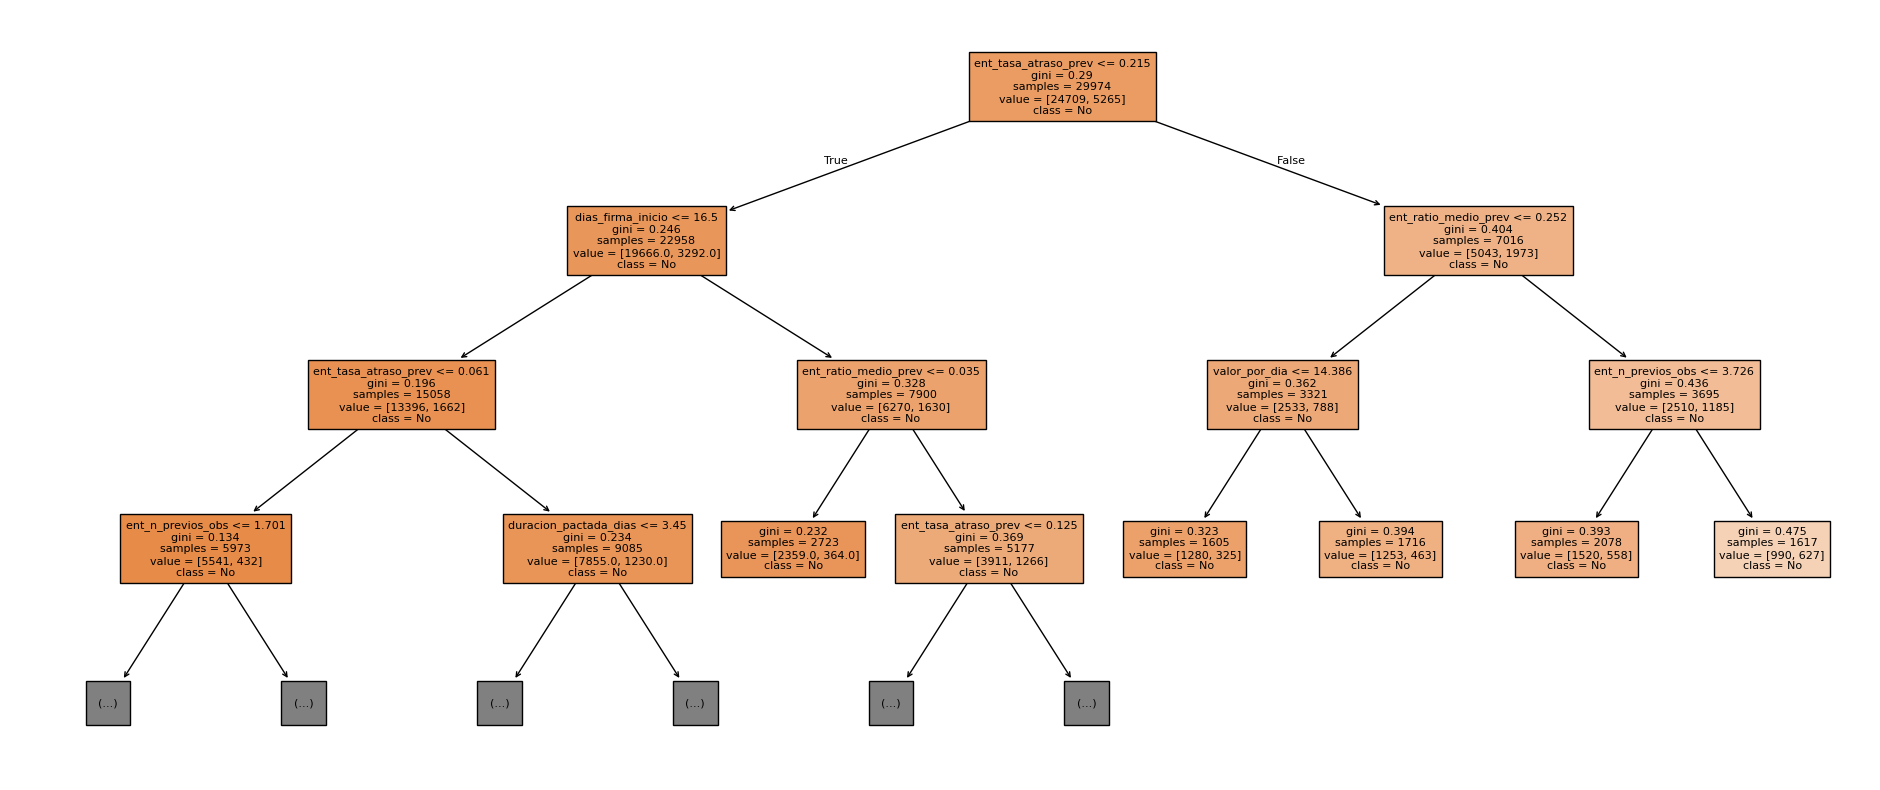

|--- ent_tasa_atraso_prev <= 0.21
|   |--- dias_firma_inicio <= 16.50
|   |   |--- ent_tasa_atraso_prev <= 0.06
|   |   |   |--- ent_n_previos_obs <= 1.70
|   |   |   |   |--- class: 0
|   |   |   |--- ent_n_previos_obs >  1.70
|   |   |   |   |--- truncated branch of depth 2
|   |   |--- ent_tasa_atraso_prev >  0.06
|   |   |   |--- duracion_pactada_dias <= 3.45
|   |   |   |   |--- class: 0
|   |   |   |--- duracion_pactada_dias >  3.45
|   |   |   |   |--- truncated branch of depth 2
|   |--- dias_firma_inicio >  16.50
|   |   |--- ent_ratio_medio_prev <= 0.03
|   |   |   |--- class: 0
|   |   |--- ent_ratio_medio_prev >  0.03
|   |   |   |--- ent_tasa_atraso_prev <= 0.13
|   |   |   |   |--- class: 0
|   |   |   |--- ent_tasa_atraso_prev >  0.13
|   |   |   |   |--- truncated branch of depth 2
|--- ent_tasa_atraso_prev >  0.21
|   |--- ent_ratio_medio_prev <= 0.25
|   |   |--- valor_por_dia <= 14.39
|   |   |   |--- class: 0
|   |   |--- valor_por_dia >  14.39
|   |   |   |--- clas

In [44]:
# Aquí dibujo el árbol de decisión para ver qué preguntas hace para decidir.
# Solo muestro los tres primeros niveles para que se pueda leer.
# Cada cuadro es una pregunta sobre una variable. El color indica hacia dónde se inclina:
# un color es para no atraso y el otro para atraso, y entre más fuerte el color, más seguro está.
# Ojo: el valor, el plazo y los conteos están en logaritmo, por eso los cortes salen en números pequeños.
plt.figure(figsize=(24, 10))
plot_tree(modelos['Árbol'], feature_names=COLUMNAS, class_names=['No', 'Atraso'], filled=True, max_depth=3, fontsize=8)
plt.show()

# Aquí saco las mismas reglas del árbol pero escritas en texto, que a veces se leen más fácil que el dibujo
print(export_text(modelos['Árbol'], feature_names=COLUMNAS, max_depth=3))

**Lectura.** La primera pregunta del árbol es la misma de la regla simple: si la entidad se atrasó en más del 21 % de sus contratos anteriores. Si no, mira los días entre la firma y el inicio (más de 16,5 días sube el riesgo). Si sí, mira cuántos días suele agregar la entidad a sus contratos. Con un mínimo del 5 % de los contratos por hoja el árbol hace pocas preguntas, así que es fácil de explicar, pero en la prueba fue el peor modelo.

Regresión logística: coeficientes y odds ratio

In [45]:
# Aquí miro los coeficientes de la regresión logística.
# Un coeficiente positivo quiere decir que, cuando la variable sube, sube el riesgo de atraso.
# Un coeficiente negativo quiere decir que el riesgo baja.
# Como hice el z-score, el odds ratio se lee así: si da 1.3, las chances de atraso suben un 30 por ciento
# cuando la variable sube una desviación estándar. Si da menor a 1, las chances bajan.
# En las categorías, la comparación es contra la categoría que quedó de referencia.

# Tomo la regresión logística que aprendió con todo 2020-2023
logistica = modelos['Logística']

# Armo una tabla con el coeficiente de cada variable y calculo el odds ratio con la exponencial
coeficientes = pd.DataFrame({'coeficiente': logistica.coef_[0]}, index=COLUMNAS_LOG)
coeficientes['odds ratio'] = np.exp(coeficientes['coeficiente'])

# Muestro las 10 que más suben el riesgo y las 10 que más lo bajan
coeficientes = coeficientes.sort_values('coeficiente', ascending=False)
pd.concat([coeficientes.head(10), coeficientes.tail(10)]).round(3)

,coeficiente,odds ratio
ent_tasa_atraso_prev,0.238,1.269
modalidad_de_contratacion_Contratación directa,0.210,1.234
dias_firma_inicio,0.153,1.165
ent_n_firmados_prev,0.116,1.123
tipo_de_contrato_Interventoría,0.105,1.111
valor_por_dia,0.104,1.109
valor_del_contrato,0.089,1.093
firma_diciembre,0.087,1.091
tipo_obra_interventoria,0.086,1.090
sector_Educación Nacional,0.082,1.085


**Lectura.** Lo que más sube el riesgo en la logística es la tasa de atraso previa de la entidad (odds ratio de 1,27 por cada desviación estándar), la contratación directa (1,23), los días entre la firma y el inicio (1,17), el tamaño de la entidad (1,12), las interventorías (1,11) y el valor por día (1,11). Lo que más lo baja es el sector defensa (0,87) y algunos departamentos como Boyacá (0,91), comparados con su categoría de referencia. Como es Elastic Net, muchas columnas quedan en cero. Son asociaciones, no causas.

Red neuronal: cómo fue aprendiendo

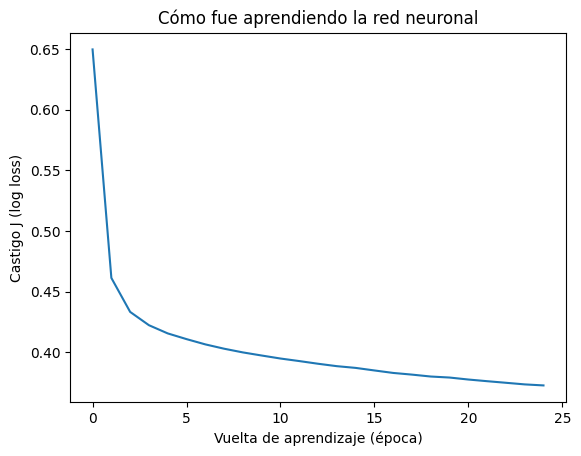

Vueltas que dio antes de parar: 25
Parámetros en total: 3953


,Entradas,Neuronas,Pesos,Sesgos
Capa,,,,
1,245,16,3920,16
2,16,1,16,1


In [46]:
# Como vimos en clase, la red aprende en vueltas, que se llaman épocas.
# En cada vuelta predice, mide el castigo J, que es qué tanto se equivocó, y corrige los pesos hacia atrás.
# Eso último es el backpropagation. Si la curva baja y después se queda plana, la red ya aprendió lo que podía.
red_final = modelos['Red neuronal']
plt.plot(red_final.loss_curve_)
plt.xlabel('Vuelta de aprendizaje (época)')
plt.ylabel('Castigo J (log loss)')
plt.title('Cómo fue aprendiendo la red neuronal')
plt.show()

# Los pesos y los sesgos son los números que aprendió la red, igual que en la tabla de capas del cuaderno de clase.
# Son tantos y están tan mezclados que no se pueden leer uno por uno como los coeficientes de la logística.
# Por eso a la red se le dice caja negra.
print('Vueltas que dio antes de parar:', red_final.n_iter_)
capas = []
for numero_capa in range(len(red_final.coefs_)):
    capas.append({'Capa': numero_capa + 1, 'Entradas': red_final.coefs_[numero_capa].shape[0],
                  'Neuronas': red_final.coefs_[numero_capa].shape[1],
                  'Pesos': red_final.coefs_[numero_capa].size, 'Sesgos': red_final.intercepts_[numero_capa].size})
capas = pd.DataFrame(capas).set_index('Capa')
print('Parámetros en total:', capas['Pesos'].sum() + capas['Sesgos'].sum())
capas

**Lectura.** La red paró sola después de 25 vueltas, cuando el castigo dejó de bajar. Tiene 3.953 pesos y sesgos en una sola capa de 16 neuronas, así que no se puede leer como la logística o el árbol: es una caja negra.

Importancia de las variables en el árbol y el bosque

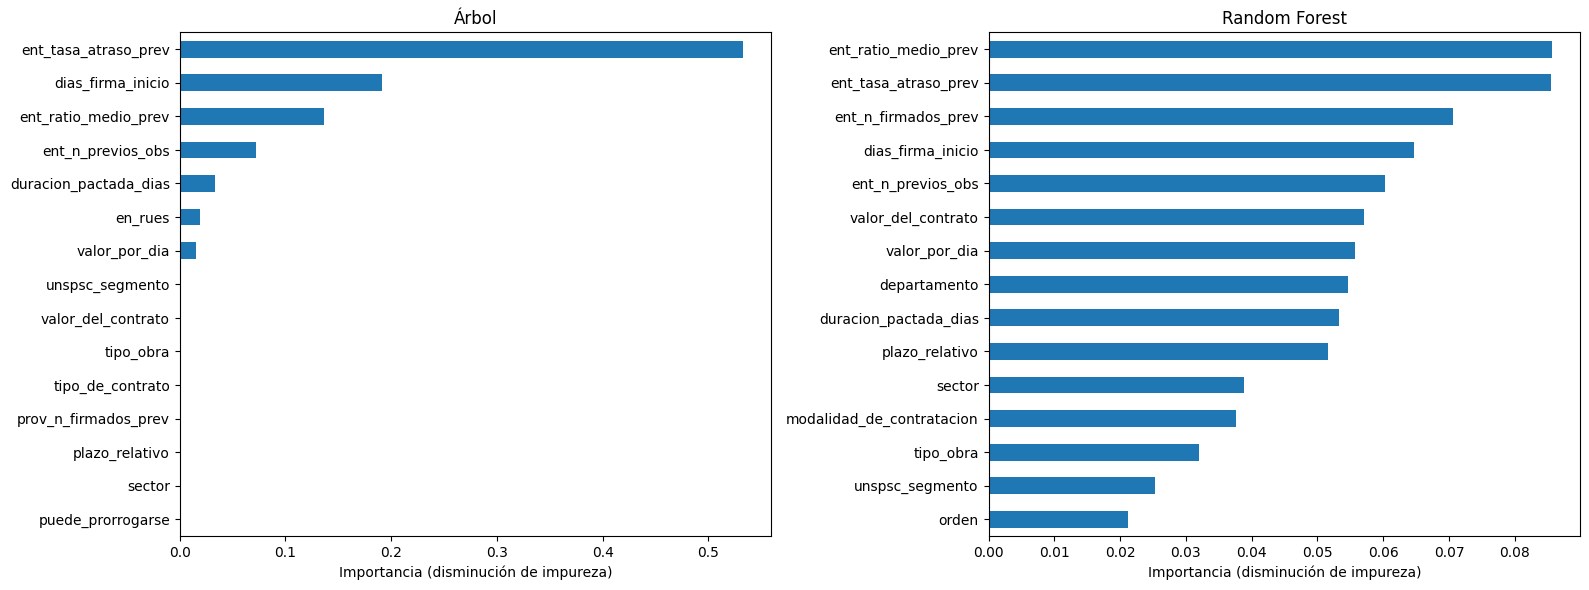

,Árbol,Random Forest
ent_ratio_medio_prev,0.1365,0.0856
ent_tasa_atraso_prev,0.5328,0.0855
ent_n_firmados_prev,0.0000,0.0706
dias_firma_inicio,0.1909,0.0647
ent_n_previos_obs,0.0725,0.0603
valor_del_contrato,0.0000,0.0570
valor_por_dia,0.0150,0.0557
departamento,0.0000,0.0546
duracion_pactada_dias,0.0334,0.0533
plazo_relativo,0.0000,0.0516


In [47]:
# El árbol y el random forest traen su propia importancia, la misma que usa el profe en su cuaderno de random forest:
# cuánto ayuda cada variable a reducir la impureza (Gini) en los cortes de los árboles.
# Las variables de texto quedaron partidas en varias columnas de 0 y 1, por ejemplo departamento en 33 columnas.
# Por eso sumo la importancia de todas las columnas que salieron de la misma variable.
# Ojo, esto dice qué usa el modelo, no qué causa el atraso.
importancia_todos = {}
for nombre in ['Árbol', 'Random Forest']:
    importancia = pd.Series(modelos[nombre].feature_importances_, index=COLUMNAS_MODELO[nombre])
    importancia_todos[nombre] = importancia.groupby(ORIGEN).sum()
importancia_todos = pd.DataFrame(importancia_todos)

# Dibujo las 15 más importantes de cada uno, lado a lado
fig, ejes = plt.subplots(1, 2, figsize=(16, 6))
for eje, nombre in zip(ejes, ['Árbol', 'Random Forest']):
    importancia_todos[nombre].sort_values().tail(15).plot.barh(ax=eje)
    eje.set_title(nombre)
    eje.set_xlabel('Importancia (disminución de impureza)')
plt.tight_layout()
plt.show()

importancia_todos.sort_values('Random Forest', ascending=False).head(15).round(4)

**Lectura.** En los dos modelos lo que más pesa es la historia de la entidad. En el árbol, la tasa de atraso previa de la entidad sola es más de la mitad de la importancia (0,533), seguida de los días entre la firma y el inicio (0,191) y de los días que suele agregar la entidad (0,137). El bosque reparte mucho más: la historia de la entidad, el tamaño de la entidad, los días entre la firma y el inicio, el valor, el valor por día y el departamento quedan todos entre 0,05 y 0,09. Que el modelo use una variable no quiere decir que cambiarla evite atrasos: la demora en iniciar puede venir de diseños incompletos o predios sin comprar.

Análisis de errores del modelo final

In [48]:
# Aquí reviso en qué tipo de contratos se equivoca más el modelo final.
# Para cada grupo calculo cuántos contratos hay, cuánto se atrasan, cuánto cuestan los errores por cada 1000 contratos,
# y cuánto costaría la regla simple en ese mismo grupo, para ver dónde el modelo ayuda y dónde no.

# Tomo algunas columnas de la prueba y les pego el costo de cada contrato y si se atrasó
errores = prueba[['tipo_de_contrato', 'modalidad_de_contratacion', 'tipo_obra']].copy()
errores['costo_modelo'] = costo_por_fila(y_prueba, recargo_mejor)
errores['costo_regla'] = costo_regla
errores['atraso'] = y_prueba
errores['falso_negativo'] = (y_prueba == 1) & ~recargo_mejor

# Para cada variable armo una tabla por grupo y la ordeno del grupo más costoso al menos costoso.
# Solo muestro los grupos con al menos 100 contratos, porque con menos el costo cambia mucho por azar.
for col in ['tipo_de_contrato', 'modalidad_de_contratacion', 'tipo_obra']:
    tabla = errores.groupby(col).agg(contratos=('atraso', 'size'), tasa_atraso=('atraso', 'mean'),
                                     atrasos_no_detectados=('falso_negativo', 'sum'),
                                     costo_modelo=('costo_modelo', 'mean'), costo_regla=('costo_regla', 'mean'))
    tabla[['costo_modelo', 'costo_regla']] = tabla[['costo_modelo', 'costo_regla']] * 1000
    tabla = tabla[tabla['contratos'] >= 100]
    display(tabla.sort_values('costo_modelo', ascending=False).round(3))

,contratos,tasa_atraso,atrasos_no_detectados,costo_modelo,costo_regla
tipo_de_contrato,,,,,
Interventoría,1976,0.367,151,778.846,845.648
Consultoría,2793,0.193,317,721.446,759.757
Obra,12476,0.215,1240,704.873,737.736


,contratos,tasa_atraso,atrasos_no_detectados,costo_modelo,costo_regla
modalidad_de_contratacion,,,,,
Contratación Directa (con ofertas),335,0.203,41,877.612,934.328
Licitación pública Obra Publica,1110,0.355,98,813.514,825.225
Selección Abreviada de Menor Cuantía,4058,0.230,494,800.641,765.648
Concurso de méritos abierto,2455,0.313,230,798.778,840.326
Contratación régimen especial (con ofertas),518,0.207,53,720.077,774.131
Mínima cuantía,5159,0.178,526,661.368,718.162
Contratación régimen especial,816,0.200,85,640.931,648.284
Contratación directa,2738,0.214,176,580.716,696.859


,contratos,tasa_atraso,atrasos_no_detectados,costo_modelo,costo_regla
tipo_obra,,,,,
edificacion,563,0.227,69,818.828,793.961
agua,625,0.219,74,804.800,838.400
interventoria,1894,0.353,154,796.199,864.836
estudios_disenos,1989,0.237,243,791.352,821.016
salud,285,0.179,32,705.263,835.088
vias,788,0.256,52,704.315,705.584
otro,3675,0.223,393,700.952,780.680
mantenimiento,7202,0.199,671,670.230,687.170
educacion,224,0.179,20,638.393,638.393


**Lectura.** Donde más le gana el modelo a la regla es en la contratación directa (580,7 frente a 696,9) y en las interventorías (778,8 frente a 845,6). Donde pierde es en la selección abreviada de menor cuantía (800,6 frente a 765,6) y en las edificaciones (818,8 frente a 794,0). Para Cimiento, en interventorías y contratación directa conviene confiar en el modelo, y en selección abreviada y edificaciones revisar a mano antes de cobrar recargo.

¿Qué pasa con las entidades y los contratistas sin historia?

In [49]:
# La ficha del modelo tiene que decir qué pasa con los que tienen pocos contratos anteriores.
# Aquí comparo cómo le va al modelo final y a la regla con los contratos de prueba con y sin historia.
# Sin historia quiere decir que no tenían contratos anteriores terminados el día de la firma.
# Ojo: para una entidad sin historia la regla siempre da tarifa estándar, porque no tiene tasa previa.
grupos_historia = {
    'Entidad con historia': prueba['ent_sin_historia'].values == 0,
    'Entidad sin historia': prueba['ent_sin_historia'].values == 1,
    'Contratista con historia': prueba['prov_sin_historia'].values == 0,
    'Contratista sin historia': prueba['prov_sin_historia'].values == 1,
}
filas = []
for nombre, marca in grupos_historia.items():
    # Si un grupo no tiene contratos, o no tiene atrasos y no atrasos, no se puede medir
    if marca.sum() == 0 or y_prueba[marca].min() == y_prueba[marca].max():
        continue
    filas.append({
        'Grupo': nombre,
        'Contratos': marca.sum(),
        'Tasa de atraso real': y_prueba[marca].mean(),
        'Probabilidad media del modelo': prob_prueba[MEJOR][marca].mean(),
        'AUC del modelo': roc_auc_score(y_prueba[marca], prob_prueba[MEJOR][marca]),
        'Costo modelo por 1.000': costo_por_fila(y_prueba[marca], recargo_mejor[marca]).mean() * 1000,
        'Costo regla por 1.000': costo_regla[marca].mean() * 1000,
    })
pd.DataFrame(filas).set_index('Grupo').round(3)

,Contratos,Tasa de atraso real,Probabilidad media del modelo,AUC del modelo,Costo modelo por 1.000,Costo regla por 1.000
Grupo,,,,,,
Entidad con historia,15360,0.235,0.168,0.701,703.776,736.133
Entidad sin historia,1885,0.179,0.123,0.663,815.915,896.552
Contratista con historia,7684,0.224,0.159,0.674,754.555,763.535
Contratista sin historia,9561,0.234,0.166,0.720,685.075,745.738


**Lectura.** El modelo le gana a la regla en los cuatro grupos, pero con las entidades sin historia ordena peor (AUC de 0,663 frente a 0,701) y les da una probabilidad media de 12,3 % cuando se atrasaron el 17,9 %. Ahí la regla es muy cara (896,6) porque siempre les da tarifa estándar. Con los contratistas es al revés: el modelo ordena mejor a los que no tienen historia (AUC de 0,720), porque se apoya en la entidad. Para la ficha: las entidades nuevas son el punto débil del modelo y conviene revisarlas a mano.

# Parte 5. No supervisado: segmentación de entidades con K-means

Perfil de cada entidad contratante

In [50]:
# En esta parte no quiero predecir nada. Quiero agrupar a las entidades que contratan parecido,
# para que Cimiento pueda tratar distinto a cada tipo de entidad.
# Primero armo una tabla donde cada fila es una entidad, con datos de cómo contrata.
# Ojo, esto lo hago solo con el entrenamiento.

# Solo tengo en cuenta entidades con al menos 5 contratos.
# Con menos contratos el perfil no es confiable, porque un solo contrato raro lo cambia todo.
MIN_CONTRATOS_ENTIDAD = 5

# Hago una copia del entrenamiento para no dañarlo, y le agrego tres columnas de ayuda con 1 o 0.
# es_obra vale 1 si el contrato es de obra, es_interventoria si es interventoría,
# y es_directa si fue por contratación directa, o sea sin concurso.
# case en False es para que no importe si está escrito con mayúscula o minúscula.
base = entrenamiento.copy()
base['es_obra'] = base['tipo_de_contrato'].str.contains('obra', case=False, na=False).astype(int)
base['es_interventoria'] = base['tipo_de_contrato'].str.contains('interventor', case=False, na=False).astype(int)
base['es_directa'] = base['modalidad_de_contratacion'].str.contains('directa', case=False, na=False).astype(int)

# Agrupo todos los contratos por entidad y calculo su perfil.
# Cuento cuántos contratos tiene, saco la mediana del valor, del plazo y de los días para iniciar,
# y saco el porcentaje de obras, interventorías, contratación directa, consorcios, firmas en diciembre y anticipo.
# Como las columnas de ayuda son de 1 y 0, el promedio me da el porcentaje.
entidades = base.groupby('codigo_entidad').agg(
    contratos=('id_contrato', 'count'),
    valor_mediano=('valor_del_contrato', 'median'),
    plazo_mediano=('duracion_pactada_dias', 'median'),
    dias_firma_inicio=('dias_firma_inicio', 'median'),
    pct_obra=('es_obra', 'mean'),
    pct_interventoria=('es_interventoria', 'mean'),
    pct_directa=('es_directa', 'mean'),
    pct_consorcio=('es_consorcio_ut', 'mean'),
    pct_diciembre=('firma_diciembre', 'mean'),
    pct_anticipo=('pct_anticipo', 'mean'),
)

# Me quedo solo con las entidades que tienen 5 contratos o más
entidades = entidades[entidades['contratos'] >= MIN_CONTRATOS_ENTIDAD]
print('Entidades con al menos', MIN_CONTRATOS_ENTIDAD, 'contratos:', len(entidades))

Entidades con al menos 5 contratos: 730


Variables para agrupar y z-score

In [51]:
# Aquí escojo con qué variables voy a armar los grupos.
# La tasa de atraso no la meto a propósito, porque la idea es agrupar por cómo contratan
# y después ver si algún grupo se atrasa más. Si la meto, estaría haciendo trampa.
VARIABLES_SEGMENTO = ['contratos', 'valor_mediano', 'plazo_mediano', 'dias_firma_inicio', 'pct_obra',
                      'pct_interventoria', 'pct_directa', 'pct_consorcio', 'pct_diciembre', 'pct_anticipo']

# Copio esas columnas en una tabla aparte
X_seg = entidades[VARIABLES_SEGMENTO].copy()

# A la cantidad de contratos, al valor y al plazo les saco el logaritmo porque tienen números muy desiguales
X_seg[['contratos', 'valor_mediano', 'plazo_mediano']] = np.log1p(X_seg[['contratos', 'valor_mediano', 'plazo_mediano']])

# Si queda algún vacío, lo lleno con el promedio de esa columna
X_seg = X_seg.fillna(X_seg.mean())

# Hago el z-score, como en la clase: a cada valor le resto el promedio y lo divido por la desviación estándar.
# K-means agrupa por distancia, y sin esto el valor en pesos pesaría muchísimo más que un porcentaje.
# Después del z-score, 0 es el promedio, 1 es una desviación por encima y -1 una por debajo.
Z = (X_seg - X_seg.mean()) / X_seg.std()
print('Listo:', Z.shape[0], 'entidades y', Z.shape[1], 'variables')

Listo: 730 entidades y 10 variables


Cuántos grupos hacer: codo y silhouette

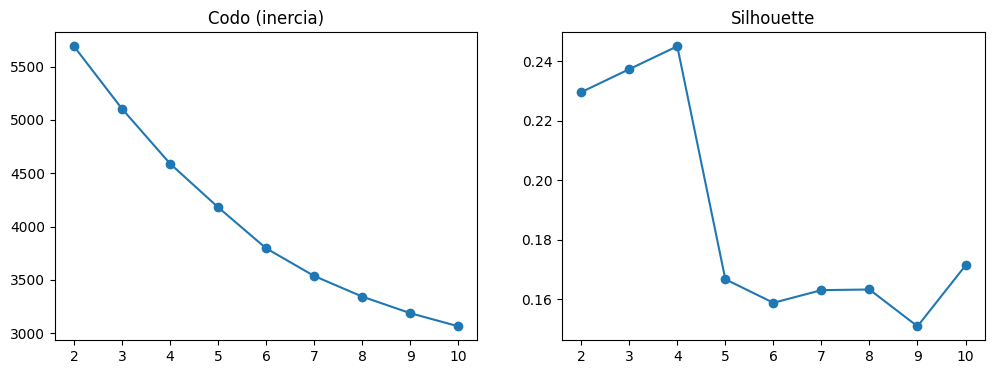

,k,inercia,silhouette
0,2,5690.045,0.230
1,3,5104.383,0.237
2,4,4590.375,0.245
3,5,4181.314,0.167
4,6,3796.272,0.159
5,7,3537.046,0.163
6,8,3343.708,0.163
7,9,3188.303,0.151
8,10,3065.153,0.171


In [52]:
# K-means necesita que yo le diga cuántos grupos hacer, que es el k.
# Para escogerlo pruebo desde 2 hasta 10 grupos y miro dos cosas.
# La inercia mide qué tan cerca está cada entidad del centro de su grupo, y entre más baja mejor.
# Siempre baja al agregar grupos, entonces busco el codo, que es donde deja de bajar tanto.
# El silhouette mide qué tan bien separados quedan los grupos. Va de -1 a 1 y entre más alto mejor.

valores_k = list(range(2, 11))
inercias = []
siluetas = []

# Para cada k corro K-means y guardo la inercia y el silhouette.
# n_init en 10 quiere decir que lo intenta 10 veces con puntos de inicio distintos y se queda con el mejor.
for k in valores_k:
    km = KMeans(n_clusters=k, n_init=10, max_iter=300, random_state=SEMILLA)
    km.fit(Z)
    inercias.append(km.inertia_)
    siluetas.append(silhouette_score(Z, km.labels_))

# Dibujo los dos gráficos lado a lado: a la izquierda el codo y a la derecha el silhouette
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
ejes[0].plot(valores_k, inercias, marker='o')
ejes[0].set_title('Codo (inercia)')
ejes[1].plot(valores_k, siluetas, marker='o')
ejes[1].set_title('Silhouette')
plt.show()

# También muestro los números en una tabla
pd.DataFrame({'k': valores_k, 'inercia': inercias, 'silhouette': siluetas}).round(3)

**Lectura.** El silhouette más alto es con 4 grupos (0,245), y desde 5 grupos baja a 0,17 o menos. El codo no es muy marcado, así que me guío por el silhouette. Un silhouette de 0,245 quiere decir que los grupos se separan, pero no del todo, así que hay que leerlos como tendencias.

Aplicar K-means con el k escogido

In [53]:
# Escojo el k con el silhouette más alto. argmax me dice en qué posición está el más alto.
K_ELEGIDO = valores_k[int(np.argmax(siluetas))]

# Corro K-means con ese número de grupos
kmeans = KMeans(n_clusters=K_ELEGIDO, n_init=10, max_iter=300, random_state=SEMILLA)
kmeans.fit(Z)

# K-means numera los grupos desde 0. Le sumo 1 y le pongo una S adelante para que queden S1, S2, S3 y así.
entidades['Segmento'] = 'S' + (kmeans.labels_ + 1).astype(str)

# Muestro el k, el silhouette final y cuántas entidades quedaron en cada segmento
print('k elegido:', K_ELEGIDO, '| silhouette:', round(silhouette_score(Z, kmeans.labels_), 3))
entidades['Segmento'].value_counts().sort_index()

k elegido: 4 | silhouette: 0.245


,count
Segmento,
S1,241
S2,420
S3,54
S4,15


Perfil de cada segmento y su tasa de atraso

In [54]:
# Aquí describo cada segmento con el promedio de sus variables, en las unidades normales.
perfil = entidades.groupby('Segmento')[VARIABLES_SEGMENTO].mean()
perfil['entidades'] = entidades['Segmento'].value_counts()

# Ahora le pego la tasa de atraso de cada segmento, contando contratos, no entidades,
# porque a Cimiento le importa cuántos contratos se atrasan.
# A cada contrato de entrenamiento le pongo el segmento de su entidad.
seg_ent = entrenamiento[['codigo_entidad', OBJETIVO]].copy()
seg_ent['Segmento'] = seg_ent['codigo_entidad'].map(entidades['Segmento'])
perfil['contratos_entrenamiento'] = seg_ent.groupby('Segmento').size()
perfil['tasa_atraso_entrenamiento'] = seg_ent.groupby('Segmento')[OBJETIVO].mean()

# Las acciones las decido con el entrenamiento. La prueba solo la uso para revisar si el patrón se mantiene.
# Si la entidad no tenía segmento, por ejemplo porque tenía menos de 5 contratos, queda vacío.
seg_prueba = prueba[['codigo_entidad', OBJETIVO]].copy()
seg_prueba['Segmento'] = seg_prueba['codigo_entidad'].map(entidades['Segmento'])
perfil['contratos_prueba'] = seg_prueba.groupby('Segmento').size()
perfil['tasa_atraso_prueba'] = seg_prueba.groupby('Segmento')[OBJETIVO].mean()

sin_segmento = seg_prueba['Segmento'].isna()
print('Contratos de prueba de entidades sin segmento:', sin_segmento.sum(), '| tasa:', round(seg_prueba.loc[sin_segmento, OBJETIVO].mean(), 3))
print('Tasa base: entrenamiento', round(TASA_BASE, 3), '| prueba', round(y_prueba.mean(), 3), '\n')
perfil.round(3)

Contratos de prueba de entidades sin segmento: 6189 | tasa: 0.174
Tasa base: entrenamiento 0.176 | prueba 0.229 



,contratos,valor_mediano,plazo_mediano,dias_firma_inicio,pct_obra,pct_interventoria,pct_directa,pct_consorcio,pct_diciembre,pct_anticipo,entidades,contratos_entrenamiento,tasa_atraso_entrenamiento,contratos_prueba,tasa_atraso_prueba
Segmento,,,,,,,,,,,,,,,
S1,58.124,8.248050e+08,191.654,21.349,0.500,0.293,0.032,0.437,0.221,0.006,241,14008,0.198,4619,0.321
S2,20.095,2.357932e+08,94.344,6.660,0.748,0.099,0.028,0.148,0.142,0.003,420,8440,0.138,4524,0.209
S3,99.389,1.929183e+08,102.500,8.046,0.866,0.066,0.612,0.068,0.191,0.008,54,5367,0.197,1631,0.239
S4,35.333,4.790012e+08,115.700,13.533,0.760,0.117,0.106,0.276,0.242,0.240,15,530,0.166,282,0.195


**Lectura.** S1 son 241 entidades con contratos grandes y largos (valor mediano de unos $825 millones y 192 días), con muchas interventorías (29 %) y consorcios (44 %), que tardan más en iniciar (21 días). S2 son 420 entidades con obras más baratas y cortas que arrancan rápido. S3 son 54 entidades con muchos contratos cada una, casi todos obras (87 %) y por contratación directa (61 %). S4 son 15 entidades con anticipos altos (24 %) y más firmas en diciembre. Contando contratos, S1 y S3 se atrasan casi el 20 % en el entrenamiento, S4 el 16,6 % y S2 el 13,8 %. En la prueba todo sube, pero S1 sigue siendo el más riesgoso (32,1 %) y S2 queda entre los menos riesgosos (20,9 %). Hay 6.189 contratos de prueba de entidades sin segmento (con menos de 5 contratos), que se atrasan el 17,4 %.

Mapa de calor de los segmentos

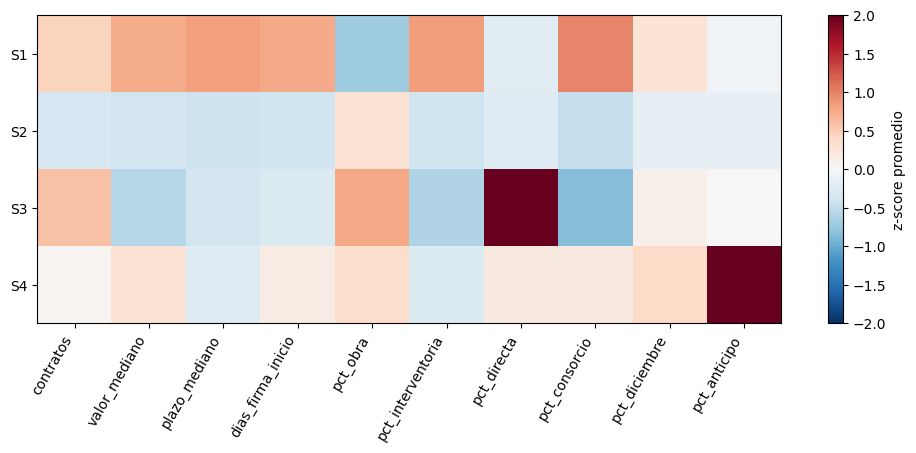

In [55]:
# Aquí hago un mapa de calor para ver rápido en qué se diferencia cada segmento.
# Uso los valores en z-score, entonces rojo quiere decir que el segmento está por encima del promedio,
# azul que está por debajo, y blanco que está más o menos en el promedio.

# Saco el promedio en z-score de cada variable para cada segmento
perfil_z = Z.groupby(entidades['Segmento']).mean()

# Dibujo el mapa con la escala de -2 a 2 y los nombres de las variables inclinados para que quepan
plt.figure(figsize=(12, 4))
plt.imshow(perfil_z, cmap='RdBu_r', vmin=-2, vmax=2, aspect='auto')
plt.colorbar(label='z-score promedio')
plt.xticks(range(len(perfil_z.columns)), perfil_z.columns, rotation=60, ha='right')
plt.yticks(range(len(perfil_z.index)), perfil_z.index)
plt.show()

Componentes principales y varianza explicada

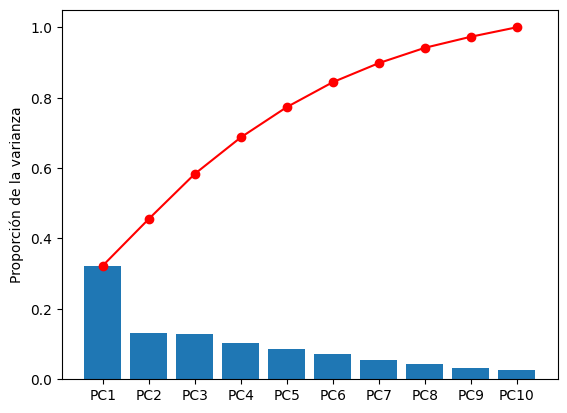

,varianza explicada,acumulada
PC1,0.323,0.323
PC2,0.133,0.455
PC3,0.128,0.583
PC4,0.104,0.687
PC5,0.086,0.773
PC6,0.071,0.844
PC7,0.054,0.898
PC8,0.043,0.942
PC9,0.031,0.973
PC10,0.027,1.000


In [56]:
# Aquí hago el PCA completo, como lo hizo el profe en su cuaderno.
# El PCA toma mis 10 variables de las entidades, ya en z-score, y las convierte en 10 componentes nuevos.
# El primer componente, PC1, es el que guarda más información, el segundo guarda la siguiente más grande, y así.
pca = PCA()
componentes = pca.fit_transform(Z)

# Les pongo nombre a los componentes: PC1, PC2, PC3 y así hasta el último
nombres_pc = ['PC' + str(i + 1) for i in range(componentes.shape[1])]

# Paso los componentes a una tabla donde cada fila es una entidad
componentes = pd.DataFrame(componentes, columns=nombres_pc, index=Z.index)

# Armo una tabla con el porcentaje de información que guarda cada componente y el acumulado.
# Por ejemplo, si PC1 da 0.32 quiere decir que guarda el 32 por ciento de la información.
varianza = pd.DataFrame({
    'varianza explicada': pca.explained_variance_ratio_,
    'acumulada': pca.explained_variance_ratio_.cumsum(),
}, index=nombres_pc)

# Dibujo una barra por componente y una línea roja con el acumulado.
plt.bar(nombres_pc, varianza['varianza explicada'])
plt.plot(nombres_pc, varianza['acumulada'], marker='o', color='red')
plt.ylabel('Proporción de la varianza')
plt.show()

varianza.round(3)

Cargas: qué variables forman cada componente

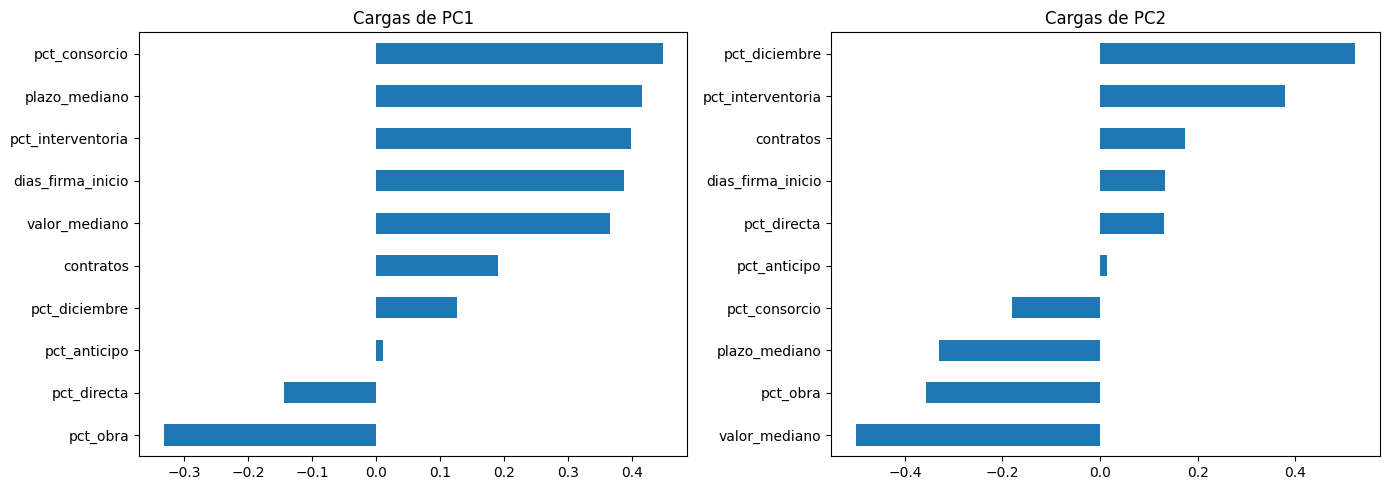

,PC1,PC2
pct_obra,-0.332,-0.356
pct_directa,-0.143,0.131
pct_anticipo,0.011,0.015
pct_diciembre,0.127,0.522
contratos,0.190,0.174
valor_mediano,0.367,-0.499
dias_firma_inicio,0.388,0.133
pct_interventoria,0.399,0.379
plazo_mediano,0.415,-0.330
pct_consorcio,0.448,-0.181


In [57]:
# Las cargas me dicen qué variables pesan más en cada componente.
# Una carga grande, positiva o negativa, quiere decir que esa variable importa mucho en ese componente.
# Esto me sirve para ponerle nombre a los ejes. Por ejemplo, si en PC1 pesan mucho el valor y el plazo,
# puedo decir que PC1 es algo así como el tamaño de los contratos.
cargas = pd.DataFrame(pca.components_.T, index=Z.columns, columns=nombres_pc)

# Dibujo las cargas de PC1 a la izquierda y las de PC2 a la derecha
fig, ejes = plt.subplots(1, 2, figsize=(14, 5))
cargas['PC1'].sort_values().plot.barh(ax=ejes[0], title='Cargas de PC1')
cargas['PC2'].sort_values().plot.barh(ax=ejes[1], title='Cargas de PC2')
plt.tight_layout()
plt.show()

# También las muestro en tabla, ordenadas por PC1
cargas[['PC1', 'PC2']].sort_values('PC1').round(3)

Los segmentos en el plano de PC1 y PC2

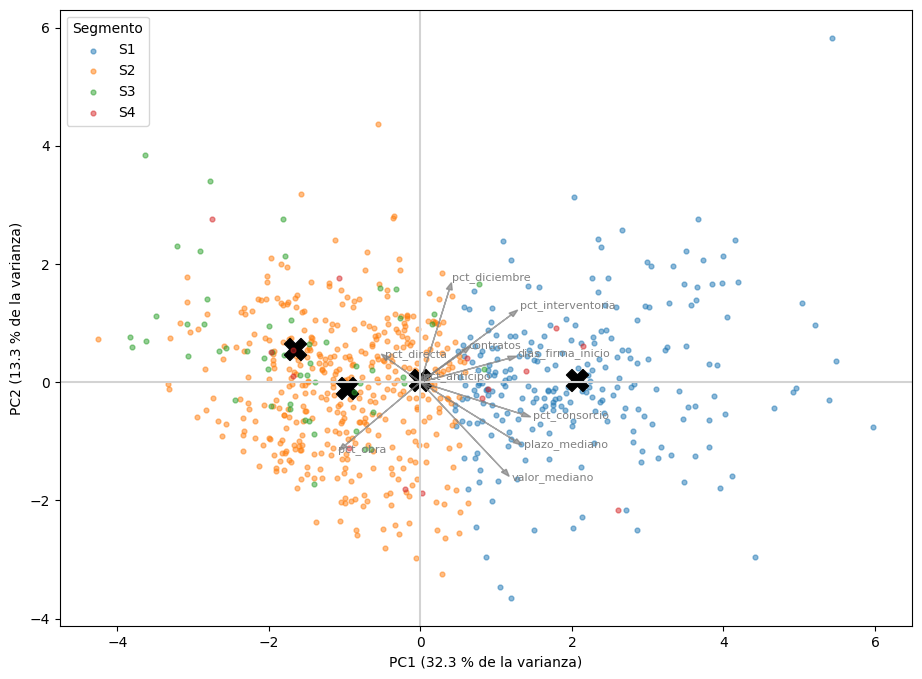

,PC1,PC2
Segmento,,
S1,2.07,0.04
S2,-0.97,-0.10
S3,-1.66,0.56
S4,-0.00,0.03


In [58]:
# Aquí dibujo las entidades en el plano de PC1 y PC2, cada segmento con un color distinto.
# La X negra es el centro de cada segmento.
# Las flechas grises son las variables. Una flecha que apunta hacia un segmento quiere decir
# que ese segmento tiene valores altos en esa variable.
# A diferencia del profe, no le pongo el nombre a cada punto porque son más de 700 entidades y no se vería nada.
plt.figure(figsize=(11, 8))

# Dibujo los puntos de cada segmento y su centro
for segmento in sorted(entidades['Segmento'].unique()):
    filas = componentes[entidades['Segmento'] == segmento]
    plt.scatter(filas['PC1'], filas['PC2'], s=12, alpha=0.5, label=segmento)
    plt.scatter(filas['PC1'].mean(), filas['PC2'].mean(), marker='X', s=250, color='black')

# Dibujo una flecha por cada variable. Las alargo 3 veces para que se alcancen a ver al lado de los puntos.
largo = 3
for variable in cargas.index:
    x = cargas.loc[variable, 'PC1'] * largo
    y = cargas.loc[variable, 'PC2'] * largo
    plt.arrow(0, 0, x, y, color='gray', alpha=0.7, head_width=0.08)
    plt.text(x * 1.1, y * 1.1, variable, color='gray', fontsize=8)

# Líneas del centro y nombres de los ejes con el porcentaje de información que guarda cada uno
plt.axhline(0, color='lightgray')
plt.axvline(0, color='lightgray')
plt.xlabel('PC1 (' + str(round(varianza.loc['PC1', 'varianza explicada'] * 100, 1)) + ' % de la varianza)')
plt.ylabel('PC2 (' + str(round(varianza.loc['PC2', 'varianza explicada'] * 100, 1)) + ' % de la varianza)')
plt.legend(title='Segmento')
plt.show()

# Aquí saco en qué parte del dibujo queda cada segmento en promedio
componentes.groupby(entidades['Segmento'])[['PC1', 'PC2']].mean().round(2)

Comparar con clustering jerárquico

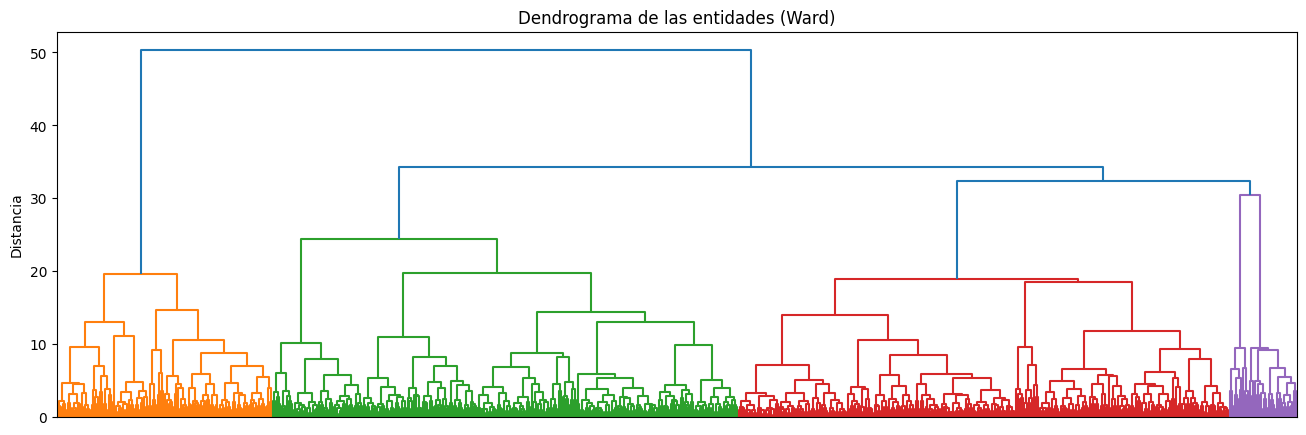

Silhouette K-means: 0.245
Silhouette jerárquico: 0.128 



Grupo jerárquico,J1,J2,J3,J4
Segmento,,,,
S1,126,113,2,0
S2,0,148,272,0
S3,0,13,14,27
S4,1,0,1,13


In [59]:
# Para saber si los segmentos de K-means son de verdad o salieron por cómo arranca el algoritmo,
# armo los grupos con otra técnica: el clustering jerárquico con el método de Ward, el mismo del cuaderno de Redes II.
# El jerárquico va uniendo de a dos las entidades más parecidas hasta que todas quedan en un solo grupo.
# El dendrograma muestra esas uniones; lo corto en el mismo número de grupos que escogí para K-means.
enlaces = linkage(Z, method='ward')
plt.figure(figsize=(16, 5))
dendrogram(enlaces, no_labels=True, color_threshold=enlaces[-(K_ELEGIDO - 1), 2])
plt.ylabel('Distancia')
plt.title('Dendrograma de las entidades (Ward)')
plt.show()

# fcluster corta el árbol en K_ELEGIDO grupos. Les pongo J1, J2, ... para no confundirlos con S1, S2, ...
entidades['Grupo jerárquico'] = 'J' + pd.Series(fcluster(enlaces, K_ELEGIDO, criterion='maxclust'), index=entidades.index).astype(str)

print('Silhouette K-means:', round(silhouette_score(Z, kmeans.labels_), 3))
print('Silhouette jerárquico:', round(silhouette_score(Z, entidades['Grupo jerárquico']), 3), '\n')

# Si cada segmento de K-means cae casi todo en un mismo grupo jerárquico, las dos técnicas encontraron lo mismo
pd.crosstab(entidades['Segmento'], entidades['Grupo jerárquico'])

**Lectura.** El jerárquico separa peor (silhouette de 0,128 frente a 0,245), así que me quedo con K-means. Las dos técnicas coinciden en lo grueso: S2 cae sobre todo en J3 y S4 casi entero en J4 (13 de 15 entidades), y S1 casi nunca cae en J3 (2 de 241). Pero el grupo J2 mezcla entidades de S1 y S2, y S3 se reparte entre tres grupos. Por eso los segmentos se leen como tendencias, sobre todo S3.

¿El segmento le aporta algo al modelo?

In [60]:
# El brief pide decir si la segmentación aporta al modelo o a la decisión.
# Si el modelo final ya entiende la diferencia entre segmentos, su probabilidad promedio en cada segmento
# debería parecerse a la tasa real. Si no se parecen, el segmento tiene información que el modelo no está usando.
# Lo reviso en la validación 2023, con el modelo que aprendió de 2020 a 2022, para no tocar la prueba.
revision = pd.DataFrame({
    'Segmento': entrenamiento.loc[es_2023, 'codigo_entidad'].map(entidades['Segmento']).fillna('Sin segmento').values,
    'atraso': y_val,
    'prob': prob_val[MEJOR],
})
revision.groupby('Segmento').agg(contratos=('atraso', 'size'), tasa_real=('atraso', 'mean'), prob_media_modelo=('prob', 'mean')).round(3)

,contratos,tasa_real,prob_media_modelo
Segmento,,,
S1,4717,0.224,0.202
S2,3116,0.147,0.145
S3,1925,0.159,0.187
S4,209,0.191,0.200
Sin segmento,888,0.113,0.127


**Lectura.** En 2023 la probabilidad promedio del modelo se parece a la tasa real en S2 (14,5 % frente a 14,7 %) y en S4 (20,0 % frente a 19,1 %). En S1 se queda un poco corto (20,2 % frente a 22,4 %) y en S3 se pasa (18,7 % frente a 15,9 %). Como las diferencias son pequeñas, no meto el segmento como variable del modelo; lo uso para decidir cómo tratar a cada tipo de entidad.

Acción por segmento

Las acciones las decido con el entrenamiento; la prueba solo confirma que S1 sigue siendo el más riesgoso.

| Segmento | Perfil | Tasa de atraso (entrenamiento) | Acción para Cimiento |
|---|---|---|---|
| S1 (241 entidades) | Contratos grandes y largos, con muchas interventorías y consorcios, que tardan más en iniciar | 19,8 % | Darles prioridad en el seguimiento de la Directora y pedir la fecha real de inicio antes de emitir. El modelo se queda un poco corto con ellas. |
| S2 (420 entidades) | Obras más baratas y cortas que arrancan rápido | 13,8 % | Tarifa estándar por defecto y trámite rápido; es el segmento donde el Gerente Comercial puede ganar clientes. Recargo solo si el modelo lo marca. |
| S3 (54 entidades) | Muchos contratos por entidad, casi todos obras por contratación directa | 19,7 % | El modelo les sobreestima el riesgo: revisar a mano antes de cobrarles recargo, para no perder clientes que firman mucho. |
| S4 (15 entidades) | Anticipos altos y más firmas en diciembre | 16,6 % | Son muy pocas entidades para una regla propia: vigilar el manejo del anticipo en el radar. |
| Sin segmento | Entidades con menos de 5 contratos | — | El modelo decide solo. |

# Parte 5b. Reglas de asociación: qué combinaciones de contratos se atrasan

Como en la clase de Market Basket, cada contrato es una "canasta" y sus características son los "productos". Busco reglas del tipo "si el contrato es una interventoría y se firmó en diciembre, entonces se atrasa", con su soporte, su confianza y su lift. Todo con el entrenamiento; la prueba solo confirma si la regla se mantiene.

Armar la canasta de cada contrato

In [61]:
# Paso cada contrato a columnas de verdadero o falso, como el one hot encoding de la canasta en clase.
# Solo uso cosas que se saben el día de la firma. Los cortes (valor alto, entidad con atrasos) salen del entrenamiento.
CORTE_VALOR_ALTO = entrenamiento['valor_del_contrato'].quantile(0.8)

# Modalidades: solo las que tienen al menos el 1 % de los contratos, para no tener productos rarísimos
modalidades = entrenamiento['modalidad_de_contratacion'].value_counts(normalize=True)
MODALIDADES_CANASTA = list(modalidades[modalidades >= 0.01].index)

def canasta(tabla):
    items = {}
    # Guardo de qué variable sale cada producto, para no combinar dos productos de la misma variable
    variable_de = {}
    for col, valores in [('tipo_de_contrato', entrenamiento['tipo_de_contrato'].dropna().unique()),
                         ('modalidad_de_contratacion', MODALIDADES_CANASTA),
                         ('orden', entrenamiento['orden'].dropna().unique()),
                         ('tipo_obra', entrenamiento['tipo_obra'].dropna().unique()),
                         ('perfil_contratista', entrenamiento['perfil_contratista'].dropna().unique())]:
        for valor in valores:
            nombre = ETIQUETAS_CANASTA[col] + ': ' + str(valor)
            items[nombre] = (tabla[col] == valor).values
            variable_de[nombre] = col
    otros = {
        'Firmado en diciembre': ('firma_diciembre', tabla['firma_diciembre'] == 1),
        'Más de 30 días entre firma e inicio': ('dias_firma_inicio', tabla['dias_firma_inicio'] > 30),
        'Consorcio o unión temporal': ('es_consorcio_ut', tabla['es_consorcio_ut'] == 1),
        'Entidad con atrasos previos altos': ('ent_tasa_atraso_prev', tabla['ent_tasa_atraso_prev'] > CORTE_REGLA),
        'Valor alto (20 % más caro)': ('valor_del_contrato', tabla['valor_del_contrato'] > CORTE_VALOR_ALTO),
        'Plazo corto para su tipo y valor': ('plazo_relativo', tabla['plazo_relativo'] < 0.7),
    }
    for nombre, (col, marca) in otros.items():
        items[nombre] = marca.fillna(False).values
        variable_de[nombre] = col
    return pd.DataFrame(items, index=tabla.index), variable_de

# Cómo se llama cada variable en las reglas
ETIQUETAS_CANASTA = {
    'tipo_de_contrato': 'Tipo de contrato', 'modalidad_de_contratacion': 'Modalidad', 'orden': 'Orden',
    'tipo_obra': 'Tipo de obra', 'perfil_contratista': 'Contratista',
}
canasta_ent, VARIABLE_DE = canasta(entrenamiento)
canasta_prueba, _ = canasta(prueba)
print('Productos en la canasta:', canasta_ent.shape[1])
canasta_ent.mean().sort_values(ascending=False).round(3).to_frame('soporte')

Productos en la canasta: 33


,soporte
Tipo de contrato: Obra,0.675
Orden: Territorial,0.673
Contratista: Nuevo,0.522
Entidad con atrasos previos altos,0.500
Tipo de obra: mantenimiento,0.365
Plazo corto para su tipo y valor,0.321
Orden: Nacional,0.304
Consorcio o unión temporal,0.263
Modalidad: Mínima cuantía,0.228
Más de 30 días entre firma e inicio,0.223


Buscar las reglas con Apriori

In [62]:
# Algoritmo Apriori, como en clase:
# 1. Me quedo con los productos que aparecen en al menos el 1 % de los contratos (soporte mínimo).
# 2. Combino de a dos solo los productos frecuentes, y me quedo con los pares frecuentes.
# 3. Con los pares frecuentes armo tríos. Si un par no es frecuente, ningún trío que lo contenga lo es (la poda).
# El consecuente de todas las reglas es siempre el mismo: atraso.
SOPORTE_MIN = 0.01
atraso_ent = y_ent == 1

def soporte(columnas, tabla):
    return tabla[list(columnas)].all(axis=1).mean()

# Paso 1
frecuentes_1 = [(p,) for p in canasta_ent.columns if soporte((p,), canasta_ent) >= SOPORTE_MIN]

# Paso 2: pares de productos de variables distintas
frecuentes_2 = []
for i in range(len(frecuentes_1)):
    for j in range(i + 1, len(frecuentes_1)):
        a, b = frecuentes_1[i][0], frecuentes_1[j][0]
        if VARIABLE_DE[a] != VARIABLE_DE[b] and soporte((a, b), canasta_ent) >= SOPORTE_MIN:
            frecuentes_2.append((a, b))

# Paso 3: tríos, solo si sus tres pares son frecuentes
pares = set(frecuentes_2)
frecuentes_3 = []
for (a, b) in frecuentes_2:
    for (c,) in frecuentes_1:
        trio = tuple(sorted((a, b, c)))
        if len({VARIABLE_DE[x] for x in trio}) == 3 and trio not in frecuentes_3:
            todos_pares = [(trio[0], trio[1]), (trio[0], trio[2]), (trio[1], trio[2])]
            if all(par in pares or par[::-1] in pares for par in todos_pares) and soporte(trio, canasta_ent) >= SOPORTE_MIN:
                frecuentes_3.append(trio)

print('Conjuntos frecuentes: de 1 =', len(frecuentes_1), '| de 2 =', len(frecuentes_2), '| de 3 =', len(frecuentes_3))

# Para cada conjunto frecuente A calculo la regla A -> atraso:
# soporte = contratos con A y atraso / total
# confianza = contratos con A y atraso / contratos con A
# lift = confianza / tasa de atraso de todos (si es mayor que 1, A se atrasa más de lo normal)
filas = []
for conjunto in frecuentes_1 + frecuentes_2 + frecuentes_3:
    tiene = canasta_ent[list(conjunto)].all(axis=1).values
    confianza = atraso_ent[tiene].mean()
    filas.append({'Si el contrato tiene': ' + '.join(conjunto), 'productos': len(conjunto),
                  'contratos': tiene.sum(), 'soporte': (tiene & atraso_ent).mean(),
                  'confianza': confianza, 'lift': confianza / TASA_BASE})
reglas = pd.DataFrame(filas).sort_values('lift', ascending=False).reset_index(drop=True)
reglas.head(15).round(3)

Conjuntos frecuentes: de 1 = 33 | de 2 = 268 | de 3 = 823


,Si el contrato tiene,productos,contratos,soporte,confianza,lift
0,Modalidad: Contratación directa + Más de 30 días entre firma e inicio + Orden: Nacional,3,366,0.007,0.607,3.453
1,Contratista: Nuevo + Modalidad: Contratación directa + Más de 30 días entre firma e inicio,3,379,0.007,0.567,3.230
2,Entidad con atrasos previos altos + Modalidad: Contratación directa + Orden: Nacional,3,568,0.011,0.562,3.197
3,Modalidad: Contratación directa + Orden: Nacional + Tipo de obra: mantenimiento,3,602,0.011,0.525,2.988
4,Modalidad: Contratación directa + Tipo de obra: mantenimiento + Valor alto (20 % más caro),3,315,0.005,0.514,2.928
5,Modalidad: Contratación directa + Más de 30 días entre firma e inicio + Tipo de obra: mantenimiento,3,560,0.009,0.498,2.836
6,Entidad con atrasos previos altos + Modalidad: Contratación directa + Más de 30 días entre firma e inicio,3,647,0.010,0.485,2.763
7,Modalidad: Contratación directa + Orden: Nacional + Tipo de contrato: Obra,3,724,0.012,0.482,2.744
8,Modalidad: Contratación directa + Orden: Nacional,2,724,0.012,0.482,2.744
9,Contratista: Nuevo + Modalidad: Contratación directa + Orden: Nacional,3,515,0.008,0.476,2.708


¿Las reglas se mantienen en la prueba y le agregan algo al modelo?

In [63]:
# Una regla solo sirve si se repite con contratos nuevos. Aquí miro las 10 de mayor lift en la prueba.
# Lift en prueba = confianza en prueba / tasa de atraso de la prueba.
# Y como Cimiento ya tendría el modelo, miro si la regla encuentra atrasos que el modelo deja pasar:
# de los contratos de la regla a los que el modelo NO les cobró recargo, cuántos se atrasaron.
# Si esa tasa pasa de 1/6, a esos contratos también les conviene el recargo, aunque el modelo no lo diga.
filas = []
for _, regla in reglas.head(10).iterrows():
    conjunto = regla['Si el contrato tiene'].split(' + ')
    tiene = canasta_prueba[conjunto].all(axis=1).values
    sin_recargo = tiene & ~recargo_mejor
    filas.append({
        'Si el contrato tiene': regla['Si el contrato tiene'],
        'lift entrenamiento': regla['lift'],
        'contratos prueba': tiene.sum(),
        'confianza prueba': y_prueba[tiene].mean(),
        'lift prueba': y_prueba[tiene].mean() / y_prueba.mean(),
        '% que el modelo ya marca': recargo_mejor[tiene].mean() * 100,
        'tasa de atraso sin recargo del modelo': y_prueba[sin_recargo].mean() if sin_recargo.sum() > 0 else np.nan,
    })
pd.DataFrame(filas).round(3)

,Si el contrato tiene,lift entrenamiento,contratos prueba,confianza prueba,lift prueba,% que el modelo ya marca,tasa de atraso sin recargo del modelo
0,Modalidad: Contratación directa + Más de 30 días entre firma e inicio + Orden: Nacional,3.453,108,0.491,2.141,77.778,0.000
1,Contratista: Nuevo + Modalidad: Contratación directa + Más de 30 días entre firma e inicio,3.230,289,0.471,2.053,89.619,0.167
2,Entidad con atrasos previos altos + Modalidad: Contratación directa + Orden: Nacional,3.197,164,0.470,2.049,96.951,0.000
3,Modalidad: Contratación directa + Orden: Nacional + Tipo de obra: mantenimiento,2.988,250,0.260,1.135,47.200,0.023
4,Modalidad: Contratación directa + Tipo de obra: mantenimiento + Valor alto (20 % más caro),2.928,45,0.489,2.133,64.444,0.250
5,Modalidad: Contratación directa + Más de 30 días entre firma e inicio + Tipo de obra: mantenimiento,2.836,234,0.346,1.510,81.624,0.023
6,Entidad con atrasos previos altos + Modalidad: Contratación directa + Más de 30 días entre firma e inicio,2.763,234,0.466,2.033,97.009,0.143
7,Modalidad: Contratación directa + Orden: Nacional + Tipo de contrato: Obra,2.744,350,0.246,1.072,46.571,0.048
8,Modalidad: Contratación directa + Orden: Nacional,2.744,350,0.246,1.072,46.571,0.048
9,Contratista: Nuevo + Modalidad: Contratación directa + Orden: Nacional,2.708,201,0.294,1.281,59.204,0.049


In [64]:
# ¿De qué entidades son los contratos con contratación directa y orden nacional?
tiene = canasta_ent[['Modalidad: Contratación directa', 'Orden: Nacional']].all(axis=1)
entrenamiento.loc[tiene, 'nombre_entidad'].value_counts(normalize=True).head(5).round(3)

,proportion
nombre_entidad,
INVIAS,0.720
CORPORACION NASA KIWE,0.170
MINISTERIO DEL DEPORTE,0.035
MUNICIPIO DE ALBAN,0.014
UNIDAD DE SERVICIOS PENITENCIARIOS Y CARCELARIOS - USPEC1,0.011


**Lectura.** Todas las reglas más fuertes tienen la contratación directa. Cuatro se mantienen en la prueba con lift cercano a 2: casi la mitad de esos contratos se atrasaron, frente al 22,9 % de todos. Las que mezclan contratación directa, orden nacional y obra o mantenimiento no se mantienen (lift de 1,1 en la prueba), así que las descarto. El modelo ya les cobra recargo a casi todos los contratos de las cuatro reglas que sí se mantienen (entre 78 % y 97 %), y de los que deja con tarifa estándar se atrasan pocos, así que las reglas casi no le agregan predicción al modelo. Lo que sí agregan es una forma de explicar en una frase por qué un contrato es riesgoso, que es lo que necesita el Gerente para hablar con los intermediarios.

Los contratos de contratación directa del orden nacional son casi todos de dos entidades: INVIAS (72 %) y la Corporación Nasa Kiwe (17 %). Las reglas con "orden nacional" hablan sobre todo de INVIAS, y por eso la acción con ellas es negociar con INVIAS condiciones especiales para su contratación directa. Las reglas sin "orden nacional" (contratista nuevo o entidad con atrasos, más contratación directa y más de 30 días para iniciar) son las que sirven como regla general.

Acción por regla (soporte = contratos con la regla y atraso / total; confianza y lift con el entrenamiento):

| Regla | Soporte | Confianza | Lift | Confianza en prueba | Acción para Cimiento |
|---|---|---|---|---|---|
| Contratación directa + más de 30 días entre firma e inicio + orden nacional | 0,7 % | 60,7 % | 3,45 | 49,1 % | Negociar con INVIAS garantías especiales para su contratación directa |
| Contratista nuevo + contratación directa + más de 30 días entre firma e inicio | 0,7 % | 56,7 % | 3,23 | 47,1 % | Pedir contragarantía o codeudor al contratista |
| Entidad con atrasos previos altos + contratación directa + orden nacional | 1,1 % | 56,2 % | 3,20 | 47,0 % | Negociar con INVIAS garantías especiales para su contratación directa |
| Entidad con atrasos previos altos + contratación directa + más de 30 días entre firma e inicio | 1,0 % | 48,5 % | 2,76 | 46,6 % | Recargo y pedir la fecha real de inicio antes de emitir |

# Parte 6. Despliegue: cómo usaría Cimiento el modelo

Tabla de tarifas por deciles de riesgo

In [65]:
# Aquí parto los contratos en 10 grupos según su probabilidad de atraso, que son los deciles.
# El decil 1 son los contratos con menos riesgo y el decil 10 los de más riesgo.
# Los cortes y la recomendación de cada decil los saco de las dos ventanas de validación (2022 y 2023),
# con las probabilidades del modelo final en cada una. La prueba solo la uso para ver la tasa real de cada decil.
prob_validacion = np.concatenate(VALIDACION[MEJOR]['probs'])
atraso_validacion = np.concatenate([v['y_v'] for v in VENTANAS_DATOS])

# Los 9 cortes que separan los 10 deciles
CORTES_DECIL = np.quantile(prob_validacion, np.linspace(0.1, 0.9, 9))

# A partir del corte del decil 10 pido garantías adicionales
CORTE_GARANTIAS = CORTES_DECIL[-1]

def decil(prob):
    return np.digitize(prob, CORTES_DECIL) + 1

# Si la probabilidad promedio del decil pasa el umbral del modelo, recargo. Al decil 10, garantías adicionales.
validacion_deciles = pd.DataFrame({'prob': prob_validacion, 'atraso': atraso_validacion, 'decil': decil(prob_validacion)})
tarifas = validacion_deciles.groupby('decil').agg(prob_media_validacion=('prob', 'mean'), tasa_real_validacion=('atraso', 'mean'))
tarifas['recomendación'] = np.where(tarifas['prob_media_validacion'] >= UMBRAL_MEJOR, 'Recargo', 'Tarifa estándar')
tarifas.loc[10, 'recomendación'] = 'Garantías adicionales'

# Ahora sí miro la prueba: cuántos contratos caen en cada decil y cuánto se atrasan de verdad
prueba_deciles = pd.DataFrame({'prob': prob_prueba[MEJOR], 'atraso': y_prueba, 'decil': decil(prob_prueba[MEJOR])})
tarifas['contratos_prueba'] = prueba_deciles.groupby('decil').size()
tarifas['prob_media_prueba'] = prueba_deciles.groupby('decil')['prob'].mean()
tarifas['tasa_real_prueba'] = prueba_deciles.groupby('decil')['atraso'].mean()

print('Umbral de recargo:', UMBRAL_MEJOR, '| corte de garantías:', round(CORTE_GARANTIAS, 3), '\n')
tarifas.round(3)

Umbral de recargo: 0.18 | corte de garantías: 0.297 



,prob_media_validacion,tasa_real_validacion,recomendación,contratos_prueba,prob_media_prueba,tasa_real_prueba
decil,,,,,,
1,0.064,0.038,Tarifa estándar,3863,0.063,0.086
2,0.098,0.066,Tarifa estándar,2412,0.097,0.130
3,0.120,0.103,Tarifa estándar,1594,0.119,0.174
4,0.138,0.124,Tarifa estándar,1395,0.138,0.213
5,0.157,0.142,Tarifa estándar,1165,0.157,0.258
6,0.177,0.173,Tarifa estándar,1298,0.178,0.266
7,0.204,0.213,Recargo,1387,0.203,0.298
8,0.235,0.287,Recargo,1252,0.234,0.339
9,0.272,0.315,Recargo,1147,0.272,0.353


**Lectura.** Con los cortes de 2022 y 2023, los deciles 1 a 6 quedan con tarifa estándar, del 7 al 9 con recargo y el 10 (probabilidad desde 0,297) con garantías adicionales. En la prueba la tasa real sube del decil 1 (8,6 %) al 10 (48,6 %), así que el orden funciona. Pero en todos los deciles la tasa de 2024 y 2025 está por encima de la de validación, y los deciles 3 a 6 (entre 17,4 % y 26,6 %) ya pasan de 1 en 6 aunque tienen tarifa estándar. Por eso el modelo que despliego lo reentreno con 2020-2025.

Curva de ganancia y revisión de 1.000 contratos

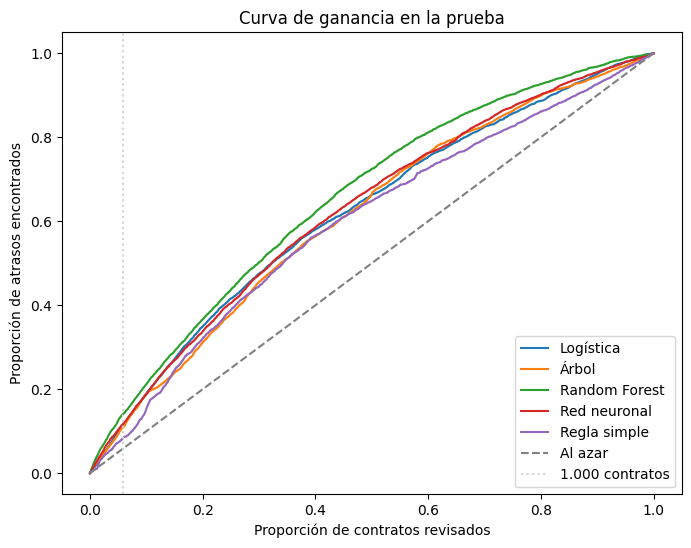

,Atrasos encontrados en 1.000,% de los 1.000,Veces lo del azar
Random Forest,553,55.3,2.41
Red neuronal,459,45.9,2.00
Logística,450,45.0,1.97
Árbol,427,42.7,1.86
Regla simple,328,32.8,1.43
Al azar (esperado),229,22.9,1.00


In [66]:
# La curva de ganancia responde esta pregunta: si reviso primero los contratos más riesgosos,
# qué porcentaje de todos los atrasos encuentro. La pidió el profe en la entrega 1.
# Comparo los cuatro modelos, la regla simple y revisar al azar.
# Entre más arriba esté la curva, mejor, porque encuentro más atrasos revisando menos contratos.

ordenes = {}
# Para los modelos ordeno de la probabilidad más alta a la más baja.
# argsort ordena de menor a mayor; con el signo menos queda de mayor a menor.
for nombre in NOMBRES_MODELOS:
    ordenes[nombre] = np.argsort(-prob_prueba[nombre])

# Con la regla hay muchos empates (todas las entidades con la misma tasa), así que los desempato al azar
orden_regla = pd.DataFrame({'regla': regla_prueba, 'desempate': np.random.default_rng(SEMILLA).random(n_prueba)})
ordenes['Regla simple'] = orden_regla.sort_values(['regla', 'desempate'], ascending=[False, True]).index.values

revisados = np.arange(1, n_prueba + 1) / n_prueba
plt.figure(figsize=(8, 6))
for nombre, orden in ordenes.items():
    # Voy sumando los atrasos a medida que reviso contratos y lo divido por el total de atrasos
    plt.plot(revisados, y_prueba[orden].cumsum() / y_prueba.sum(), label=nombre)
plt.plot([0, 1], [0, 1], '--', color='gray', label='Al azar')
plt.axvline(CAPACIDAD / n_prueba, color='lightgray', linestyle=':', label='1.000 contratos')
plt.xlabel('Proporción de contratos revisados')
plt.ylabel('Proporción de atrasos encontrados')
plt.title('Curva de ganancia en la prueba')
plt.legend()
plt.show()

# Con la capacidad real de la Directora, que alcanza a revisar 1000 contratos
encontrados = {nombre: y_prueba[orden[:CAPACIDAD]].sum() for nombre, orden in ordenes.items()}
encontrados['Al azar (esperado)'] = round(CAPACIDAD * y_prueba.mean())
revision = pd.DataFrame({'Atrasos encontrados en 1.000': pd.Series(encontrados)})
revision['% de los 1.000'] = revision['Atrasos encontrados en 1.000'] / CAPACIDAD * 100
revision['Veces lo del azar'] = revision['Atrasos encontrados en 1.000'] / encontrados['Al azar (esperado)']
revision.sort_values('Atrasos encontrados en 1.000', ascending=False).round(2)

**Lectura.** Si la Directora revisa los 1.000 contratos que el random forest marca como más riesgosos, encuentra 553 atrasos, frente a 328 con la regla y unos 229 al azar: 2,4 veces más que revisando al azar. El bosque también le gana a la red (459), a la logística (450) y al árbol (427).

Ahorro del modelo frente a la regla simple

In [67]:
# Aquí calculo cuánto se ahorra Cimiento por cada 1000 contratos si usa el modelo en vez de la regla simple.
# El ahorro es el costo de la regla menos el costo del modelo, contrato por contrato.
# Si da positivo, el modelo le ahorra a Cimiento.
# Supuestos: los costos son los del brief (5 y 1), están en unidades y no en pesos,
# y los contratos de 2024 y 2025 se parecen a los que Cimiento va a asegurar.
costo_modelo = costo_por_fila(y_prueba, recargo_mejor)
ahorro = costo_regla - costo_modelo

print('Costo regla simple por 1.000:', round(costo_regla.mean() * 1000, 1))
print('Costo', MEJOR, 'por 1.000:', round(costo_modelo.mean() * 1000, 1))
print('Ahorro por 1.000 contratos:', round(ahorro.mean() * 1000, 1), 'unidades')

# El mismo ahorro en cada uno de los 5 batches de la prueba, para ver si se repite
ahorro_batches = costo_por_batch['Regla simple'] - costo_por_batch[MEJOR]
print('Ahorro en cada batch:', ahorro_batches.round(1).tolist())
print('Media:', round(ahorro_batches.mean(), 1), '| DE:', round(ahorro_batches.std(), 1))

Costo regla simple por 1.000: 753.7
Costo Random Forest por 1.000: 716.0
Ahorro por 1.000 contratos: 37.6 unidades
Ahorro en cada batch: [38.9, 26.7, 48.4, 31.3, 42.9]
Media: 37.6 | DE: 8.7


**Lectura.** Con los costos del brief, usar el random forest en vez de la regla le ahorra a Cimiento 37,6 unidades por cada 1.000 contratos, alrededor de un 5 % del costo de la regla. El ahorro aparece en los cinco batches, entre 26,7 y 48,4. Es menos que en la entrega 1 porque ahora escojo todo con dos ventanas y sin que la validación vea datos del año que valida; esta cifra es más realista.

¿Y si los costos fueran otros?

In [68]:
# El brief deja discutir los costos, pero pide decir qué cambia en la recomendación.
# Toda la recomendación del proyecto está hecha con 5 a 1, que es lo que pide el brief.
# Aquí solo pruebo qué pasaría con otros costos para un atraso no detectado: 2, 3, 5 y 10.
# El recargo innecesario sigue costando 1.
# Para cada costo vuelvo a escoger, sin mirar la prueba:
# el corte de la regla con el entrenamiento, y el umbral del modelo con el promedio de las dos ventanas.
# El umbral teórico es 1 / (1 + costo FN).
def costo_con(real, recargo, costo_fn):
    return (costo_fn * ((real == 1) & ~recargo) + 1 * ((real == 0) & recargo)).mean() * 1000

filas = []
for costo_fn in [2, 3, 5, 10]:
    # Corte de la regla con el entrenamiento
    corte = cortes_posibles[np.argmin([costo_con(y_ent, regla_ent > c, costo_fn) for c in cortes_posibles])]
    # Umbral del modelo con la curva promedio de las dos ventanas
    curva = np.mean([[costo_con(v['y_v'], p >= u, costo_fn) for u in UMBRALES]
                     for v, p in zip(VENTANAS_DATOS, VALIDACION[MEJOR]['probs'])], axis=0)
    umbral = UMBRALES[np.argmin(curva)]
    # Ahora sí, la prueba
    costo_regla_c = costo_con(y_prueba, regla_prueba > corte, costo_fn)
    costo_modelo_c = costo_con(y_prueba, prob_prueba[MEJOR] >= umbral, costo_fn)
    filas.append({
        'Costo FN': costo_fn,
        'Umbral teórico': round(1 / (1 + costo_fn), 3),
        'Umbral escogido': umbral,
        'Corte de la regla': corte,
        'Tarifa estándar a todos': costo_con(y_prueba, np.zeros(n_prueba, dtype=bool), costo_fn),
        'Recargo a todos': costo_con(y_prueba, np.ones(n_prueba, dtype=bool), costo_fn),
        'Regla simple': costo_regla_c,
        MEJOR: costo_modelo_c,
        'Ahorro del modelo': costo_regla_c - costo_modelo_c,
        '% con recargo': (prob_prueba[MEJOR] >= umbral).mean() * 100,
    })
pd.DataFrame(filas).set_index('Costo FN').round(2)

,Umbral teórico,Umbral escogido,Corte de la regla,Tarifa estándar a todos,Recargo a todos,Regla simple,Random Forest,Ahorro del modelo,% con recargo
Costo FN,,,,,,,,,
2,0.33,0.60,0.50,458.34,770.83,454.33,458.34,-4.00,0.00
3,0.25,0.22,0.25,687.50,770.83,589.21,540.79,48.42,23.79
5,0.17,0.18,0.06,1145.84,770.83,753.67,716.03,37.63,35.09
10,0.09,0.12,0.03,2291.68,770.83,1063.44,857.76,205.68,58.56


**Lectura.** Mi recomendación está hecha con los costos del brief (5 a 1). Si cambian, cambia la respuesta. Con costo 3 o 5 el modelo es la mejor opción (ahorra 48,4 y 37,6 frente a la regla). Con costo 2 el modelo no le cobra recargo a nadie, y la regla queda apenas mejor (454,3 frente a 458,3). Con costo 10 lo más barato es cobrarle recargo a todos (770,8), por encima del modelo (857,8) y de la regla (1.063,4), porque en la prueba se atrasa el 22,9 % de los contratos, más que el umbral de 1/11.

Cuánto vale el modelo en pesos

In [69]:
# El brief deja pasar las unidades a pesos con un supuesto escrito.
# Una unidad es lo que Cimiento pierde cuando un contratista se va a otra aseguradora por un recargo que no merecía,
# o sea, más o menos la prima de una póliza. Entonces calculo la prima de una póliza típica.
# SUPUESTOS (si consiguen un dato mejor, solo cambian estos dos números):
COBERTURA = 0.10  # la garantía cubre al menos el 10 % del valor del contrato (brief, Colombia Compra Eficiente)
TASA_PRIMA = 0.003  # la prima es el 0,3 % del valor asegurado. Sale de pólizas reales de cumplimiento publicadas en
# Colombia Compra Eficiente (Bolívar 0,18 %, SURA 0,22 %, Berkley 0,42 %, Liberty 0,77 %): entre más larga la póliza, más alta la tasa,
# y la mayoría de nuestros contratos dura menos de un año.

# Uso la mediana del valor y no el promedio, porque unos pocos contratos gigantes subirían mucho el promedio
valor_tipico = entrenamiento['valor_del_contrato'].median()
prima_tipica = valor_tipico * COBERTURA * TASA_PRIMA

# Contratos al año: el promedio de los años completos que hay en los datos (2021 a 2025)
contratos_por_anio = df_secop[df_secop['anio_firma'].between(2021, 2025)].groupby('anio_firma').size().mean()

ahorro_por_contrato = ahorro.mean()
print('Valor típico de un contrato: $' + format(round(valor_tipico), ','))
print('Prima típica (= 1 unidad): $' + format(round(prima_tipica), ','))
print('Ahorro por 1.000 contratos:', round(ahorro_por_contrato * 1000, 1), 'unidades = $' + format(round(ahorro_por_contrato * 1000 * prima_tipica), ','))
print('Contratos al año en los datos:', round(contratos_por_anio))
print('Ahorro al año si Cimiento asegurara todo ese mercado: $' + format(round(ahorro_por_contrato * contratos_por_anio * prima_tipica), ','))

Valor típico de un contrato: $212,299,359
Prima típica (= 1 unidad): $63,690
Ahorro por 1.000 contratos: 37.6 unidades = $2,396,908
Contratos al año en los datos: 10020
Ahorro al año si Cimiento asegurara todo ese mercado: $24,017,981


**Lectura.** Con una prima del 0,3 % sobre una garantía del 10 % del valor, la póliza de un contrato típico ($212 millones) vale unos $64.000, y esa es una unidad. Así, el ahorro del modelo es de unos $2,4 millones por cada 1.000 contratos. Si Cimiento asegurara todo el mercado de los datos (unos 10.000 contratos al año), serían unos $24 millones al año, pero eso es un techo: Cimiento solo tiene una parte del mercado. La tasa sale de pólizas reales publicadas en Colombia Compra Eficiente, que cobran entre 0,2 % y 0,8 % según cuánto dure la póliza.

Modelo desplegado: el mismo modelo, reentrenado con 2020-2025

In [70]:
# Hasta aquí todo lo medí con el modelo que aprendió con 2020-2023, que es el que se evaluó en la prueba.
# Como ya terminé de medir, ahora lo reentreno con todos los contratos terminados de 2020 a 2025,
# como recomendó el profe. Así aprende también de 2024 y 2025, que es cuando más subió el atraso.
# Este modelo desplegado es distinto del evaluado: es el que uso para el radar y el que guardo para la app.
# Mantengo el mismo tipo de modelo, la misma configuración, el mismo umbral y el mismo corte de garantías.
# Toda la preparación (recortes, plazo normal, promedios) la vuelvo a calcular con 2020-2025.
desplegado_crudo = pd.concat([entrenamiento_crudo, prueba_crudo])
X_desp, (X_radar_desp,), INFO_DESP = preparar_periodo(desplegado_crudo, [radar_crudo])
y_desp = desplegado_crudo[OBJETIVO].astype(int).values

if MEJOR == 'Logística':
    COLS_DESP = columnas_logistica(INFO_DESP['columnas'])
else:
    COLS_DESP = INFO_DESP['columnas']
X_desp, X_radar_desp = X_desp[COLS_DESP], X_radar_desp[COLS_DESP]

ZSCORE_DESP = None
if MEJOR in USAN_ZSCORE:
    ZSCORE_DESP = centro_y_escala(X_desp)
    X_desp = (X_desp - ZSCORE_DESP[0]) / ZSCORE_DESP[1]
    X_radar_desp = (X_radar_desp - ZSCORE_DESP[0]) / ZSCORE_DESP[1]

modelo_desplegado = CREAR[MEJOR]()
modelo_desplegado.fit(X_desp, y_desp)
prob_radar_desplegado = modelo_desplegado.predict_proba(X_radar_desp)[:, 1]

print('Modelo desplegado:', MEJOR, '| aprendió con', len(y_desp), 'contratos de 2020 a 2025 | tasa de atraso', round(y_desp.mean(), 3))
print('Probabilidad media en el radar: evaluado', round(prob_radar[MEJOR].mean(), 3), '| desplegado', round(prob_radar_desplegado.mean(), 3))

Modelo desplegado: Random Forest | aprendió con 47219 contratos de 2020 a 2025 | tasa de atraso 0.195
Probabilidad media en el radar: evaluado 0.203 | desplegado 0.241


**Lectura.** El modelo desplegado aprendió con 47.219 contratos de 2020 a 2025, que se atrasaron el 19,5 %. Como ya vio los años de más atraso, en el radar da una probabilidad media de 24,1 %, frente a 20,3 % del modelo evaluado. Es justo lo que buscaba: corregir que el modelo evaluado se quedaba corto con el riesgo reciente. Este no es el modelo que medí en la prueba; es el mismo tipo de modelo con la misma configuración y el mismo umbral, entrenado con más años.

Radar de contratos en ejecución

In [71]:
# Aquí uso el modelo desplegado con los contratos que siguen en ejecución, que son el radar.
# A cada uno le pongo su probabilidad de atraso y la recomendación de la tabla de tarifas.
radar['prob_atraso'] = prob_radar_desplegado.round(3)
radar['recomendacion'] = np.where(radar['prob_atraso'] >= UMBRAL_MEJOR, 'Recargo', 'Tarifa estándar')
radar.loc[radar['prob_atraso'] >= CORTE_GARANTIAS, 'recomendacion'] = 'Garantías adicionales'

# Saco los 1000 contratos con más riesgo, que son los que la Directora debería revisar primero
top_radar = radar.sort_values('prob_atraso', ascending=False).head(CAPACIDAD).copy()

# Las razones salen de las 10 variables más importantes del modelo final.
# Si el modelo final es el árbol o el bosque uso su importancia; si no, el Info. gain del ranking de Orange.
if MEJOR in importancia_todos.columns:
    importancia_final = importancia_todos[MEJOR]
else:
    importancia_final = ranking.set_index('Variable')['Info. gain']
VARIABLES_RAZON = [v for v in importancia_final.sort_values(ascending=False).index[:10] if v in entrenamiento.columns]

# Para cada una de esas variables miro, con el entrenamiento, qué porcentaje de atraso tuvieron los contratos parecidos,
# igual que las tablas de tasa de atraso por grupos de la Parte 1:
# si la variable es una categoría (o tiene pocos valores), los contratos con el mismo valor;
# si es un número, los que caen en el mismo rango de 10 que armo con pd.qcut.
# Los vacíos quedan en su propio grupo. Si un grupo tiene menos de 30 contratos no confío en su tasa y uso la tasa base.
def tasa_de_parecidos(variable, tabla):
    if variable in CATEGORICAS or entrenamiento[variable].nunique() <= 10:
        grupo_ent = entrenamiento[variable].fillna('Sin dato').astype(str)
        grupo_nuevo = tabla[variable].fillna('Sin dato').astype(str)
    else:
        _, bordes = pd.qcut(entrenamiento[variable], 10, retbins=True, duplicates='drop')
        # Abro los bordes de los extremos para que un contrato más chico o más grande que todos también tenga rango
        bordes[0], bordes[-1] = -np.inf, np.inf
        grupo_ent = pd.cut(entrenamiento[variable], bordes).astype(str)
        grupo_nuevo = pd.cut(tabla[variable], bordes).astype(str)
    resumen = entrenamiento[OBJETIVO].groupby(grupo_ent).agg(['mean', 'size'])
    tasa = resumen['mean'].where(resumen['size'] >= 30, TASA_BASE)
    return grupo_nuevo.map(tasa).fillna(TASA_BASE)

tasas_parecidos = pd.DataFrame({v: tasa_de_parecidos(v, top_radar) for v in VARIABLES_RAZON})

# Nombres en palabras sencillas para las variables que más aparecen
NOMBRES = {
    'ent_tasa_atraso_prev': 'Atrasos previos de la entidad', 'ent_ratio_medio_prev': 'Días que suele agregar la entidad',
    'ent_n_previos_obs': 'Contratos terminados de la entidad', 'ent_n_firmados_prev': 'Contratos firmados por la entidad',
    'prov_tasa_atraso_prev': 'Atrasos previos del contratista', 'prov_ratio_medio_prev': 'Días que suele agregar el contratista',
    'prov_n_previos_obs': 'Contratos terminados del contratista', 'prov_n_firmados_prev': 'Contratos firmados por el contratista',
    'valor_del_contrato': 'Valor', 'duracion_pactada_dias': 'Plazo pactado (días)', 'dias_firma_inicio': 'Días entre firma e inicio',
    'plazo_relativo': 'Plazo frente a contratos parecidos', 'firma_diciembre': 'Firmado en diciembre',
    'tipo_de_contrato': 'Tipo de contrato', 'modalidad_de_contratacion': 'Modalidad', 'departamento': 'Departamento',
    'orden': 'Orden', 'sector': 'Sector', 'tipo_obra': 'Tipo de obra', 'pct_anticipo': 'Anticipo (%)',
    'edad_proveedor_anios': 'Años del contratista', 'es_consorcio_ut': 'Consorcio o unión temporal',
}

# Esta receta escribe cada razón con el valor que tiene el contrato
def describir(variable, valor):
    nombre = NOMBRES.get(variable, variable)
    if pd.isna(valor):
        return nombre + ': sin dato'
    if isinstance(valor, str):
        return nombre + ': ' + valor
    if variable.endswith('tasa_atraso_prev'):
        return nombre + ': ' + str(round(valor * 100)) + ' %'
    if variable == 'valor_del_contrato':
        return nombre + ': $' + format(round(valor / 1e6), ',').replace(',', '.') + ' millones'
    if variable in ['firma_diciembre', 'es_consorcio_ut', 'prov_sin_historia', 'ent_sin_historia', 'puede_prorrogarse', 'en_rues']:
        return nombre + ': ' + ('sí' if valor == 1 else 'no')
    if abs(valor) >= 10:
        return nombre + ': ' + format(round(valor), ',').replace(',', '.')
    return nombre + ': ' + str(round(valor, 2))

# A cada contrato le dejo las tres variables donde los parecidos se atrasaron más, si pasan la tasa base
razones = []
for indice, fila in tasas_parecidos.iterrows():
    tres = fila[fila > TASA_BASE].sort_values(ascending=False).head(3)
    textos = []
    for variable, tasa in tres.items():
        textos.append(describir(variable, top_radar.loc[indice, variable]) + ' (parecidos: ' + str(round(tasa * 100)) + ' % de atraso)')
    razones.append(' | '.join(textos))
top_radar['razones'] = razones

# Solo muestro el número del contrato y la entidad, que es pública. No muestro nombres ni nit de contratistas,
# porque pueden ser personas naturales y la Ley 1581 protege sus datos.
VER = ['id_contrato', 'nombre_entidad', 'tipo_de_contrato', 'departamento', 'prob_atraso', 'recomendacion', 'razones']
print('Recomendaciones en todo el radar:')
print(radar['recomendacion'].value_counts(), '\n')
print('Entidades distintas en los 1000 primeros:', top_radar['codigo_entidad'].nunique())
print(top_radar['nombre_entidad'].value_counts().head(5), '\n')
top_radar[VER].head(15)

Recomendaciones en todo el radar:
recomendacion
Recargo                  6006
Tarifa estándar          4036
Garantías adicionales    3675
Name: count, dtype: int64 

Entidades distintas en los 1000 primeros: 67
nombre_entidad
INVIAS                                                          248
INSTITUTO DE CAMINOS Y CONSTRUCCIONES DE CUNDINAMARCA - ICCU    146
GOBERNACION DEL MAGDALENA                                        73
AGENCIA PARA LA INFRAESTRUCTURA DEL META                         73
MUNICIPIO DE MANIZALES                                           67
Name: count, dtype: int64 



,id_contrato,nombre_entidad,tipo_de_contrato,departamento,prob_atraso,recomendacion,razones
45789,CO1.PCCNTR.8236925,INVIAS,Interventoría,Distrito Capital de Bogotá,0.777,Garantías adicionales,Días que suele agregar la entidad: 0.32 (parecidos: 31 % de atraso) | Atrasos previos de la entidad: 34 % (parecidos: 30 % de atraso) | Contratos firmados por la entidad: 3.105 (parecidos: 26 % de...
45624,CO1.PCCNTR.8223294,INVIAS,Obra,Distrito Capital de Bogotá,0.774,Garantías adicionales,Días que suele agregar la entidad: 0.32 (parecidos: 31 % de atraso) | Atrasos previos de la entidad: 34 % (parecidos: 30 % de atraso) | Días entre firma e inicio: 62 (parecidos: 28 % de atraso)
50597,CO1.PCCNTR.8578921,INVIAS,Consultoría,Distrito Capital de Bogotá,0.760,Garantías adicionales,Días que suele agregar la entidad: 0.32 (parecidos: 31 % de atraso) | Atrasos previos de la entidad: 34 % (parecidos: 30 % de atraso) | Contratos firmados por la entidad: 3.204 (parecidos: 26 % de...
50607,CO1.PCCNTR.8579205,INVIAS,Consultoría,Distrito Capital de Bogotá,0.749,Garantías adicionales,Días que suele agregar la entidad: 0.32 (parecidos: 31 % de atraso) | Atrasos previos de la entidad: 34 % (parecidos: 30 % de atraso) | Contratos firmados por la entidad: 3.209 (parecidos: 26 % de...
50789,CO1.PCCNTR.8589533,INVIAS,Interventoría,Distrito Capital de Bogotá,0.745,Garantías adicionales,Días que suele agregar la entidad: 0.32 (parecidos: 31 % de atraso) | Atrasos previos de la entidad: 34 % (parecidos: 30 % de atraso) | Contratos firmados por la entidad: 3.199 (parecidos: 26 % de...
47914,CO1.PCCNTR.8405605,GOBERNACION DEL MAGDALENA,Obra,Magdalena,0.722,Garantías adicionales,Departamento: Magdalena (parecidos: 34 % de atraso) | Atrasos previos de la entidad: 49 % (parecidos: 31 % de atraso) | Días que suele agregar la entidad: 0.48 (parecidos: 28 % de atraso)
51149,CO1.PCCNTR.8614199,INVIAS,Interventoría,Distrito Capital de Bogotá,0.720,Garantías adicionales,Días que suele agregar la entidad: 0.32 (parecidos: 31 % de atraso) | Atrasos previos de la entidad: 34 % (parecidos: 30 % de atraso) | Días entre firma e inicio: 95 (parecidos: 28 % de atraso)
47413,CO1.PCCNTR.8364110,GOBERNACION DEL MAGDALENA,Obra,Magdalena,0.718,Garantías adicionales,Departamento: Magdalena (parecidos: 34 % de atraso) | Atrasos previos de la entidad: 49 % (parecidos: 31 % de atraso) | Días que suele agregar la entidad: 0.48 (parecidos: 28 % de atraso)
46639,CO1.PCCNTR.8303770,GOBERNACION DEL MAGDALENA,Obra,Magdalena,0.717,Garantías adicionales,Departamento: Magdalena (parecidos: 34 % de atraso) | Atrasos previos de la entidad: 46 % (parecidos: 31 % de atraso) | Días que suele agregar la entidad: 0.49 (parecidos: 28 % de atraso)
47403,CO1.PCCNTR.8363793,GOBERNACION DEL MAGDALENA,Obra,Magdalena,0.715,Garantías adicionales,Departamento: Magdalena (parecidos: 34 % de atraso) | Atrasos previos de la entidad: 49 % (parecidos: 31 % de atraso) | Días que suele agregar la entidad: 0.48 (parecidos: 28 % de atraso)


**Lectura.** De los 13.717 contratos en ejecución, 3.675 quedan con garantías adicionales, 6.006 con recargo y 4.036 con tarifa estándar. Hay más garantías que antes porque el modelo desplegado da probabilidades más altas y el corte de garantías es el mismo. Como estos contratos ya están firmados, lo útil para la Directora es el orden: qué revisar primero. Los 1.000 más riesgosos están en 67 entidades; INVIAS tiene 248 y el ICCU de Cundinamarca 146. Las razones dicen en qué variables el contrato se parece a los que más se atrasaron en 2020-2023. Son una estimación de riesgo, no una prueba de que la entidad o el contratista hayan hecho algo mal.

Guardar el modelo y los archivos para la app

In [72]:
# Aquí guardo todo lo que necesito para usar el modelo en la app de Streamlit, con el mismo formato
# del paquete que usa el profe en sus cuadernos (modelo, columnas, medias, categóricas, tipo y umbral).
# Le agrego lo que la app necesita para preparar un contrato nuevo igual que aquí:
# el corte de garantías, los límites del recorte, los cortes de valor, el plazo normal y las palabras del tipo de obra.
# Guardo el modelo desplegado (2020-2025), no el evaluado. Todo lo de preparar los datos también sale de 2020-2025.
paquete = {
    'modelo': modelo_desplegado,
    'entrenado_con': 'contratos terminados de 2020 a 2025 (el evaluado en la prueba aprendió con 2020-2023)',
    'columnas': COLS_DESP,
    'medias': INFO_DESP['medias'][COLS_DESP],
    # Si el modelo usa z-score, la app necesita el mismo centro y la misma escala; si no, quedan en None
    'centro': ZSCORE_DESP[0] if ZSCORE_DESP else None,
    'escala': ZSCORE_DESP[1] if ZSCORE_DESP else None,
    'categoricas': CATEGORICAS,
    'tipo': 'clasificacion',
    'umbral': UMBRAL_MEJOR,
    'clase_positiva': 'Atraso',
    'clase_negativa': 'Sin atraso',
    'nombre_modelo': MEJOR,
    'corte_garantias': CORTE_GARANTIAS,
    'limites': INFO_DESP['limites'],
    'cortes_valor': INFO_DESP['cortes_valor'],
    'mediana_plazo': INFO_DESP['mediana_plazo'],
    'palabras_tipo_obra': PALABRAS,
}
joblib.dump(paquete, 'modelo_obrasegura.joblib')

# Guardo los 1000 del radar con sus razones, y el radar completo para poder filtrarlo en la app
top_radar[VER].to_csv('radar_1000.csv', index=False)
radar[['id_contrato', 'nombre_entidad', 'tipo_de_contrato', 'modalidad_de_contratacion', 'departamento',
       'prob_atraso', 'recomendacion']].sort_values('prob_atraso', ascending=False).to_csv('radar_completo.csv', index=False)
print('Archivos guardados: modelo_obrasegura.joblib, radar_1000.csv y radar_completo.csv')

# Si DESCARGAR está en True, los descargo a mi computador
if DESCARGAR:
    from google.colab import files
    for archivo in ['modelo_obrasegura.joblib', 'radar_1000.csv', 'radar_completo.csv']:
        files.download(archivo)

Archivos guardados: modelo_obrasegura.joblib, radar_1000.csv y radar_completo.csv


# Parte 7. Exportar el modelo a la app


Conectar la carpeta de la app

In [73]:
# Aquí le digo al cuaderno dónde está la carpeta de la app en mi Drive.
# Si la pusieron en otra carpeta, solo cambio esta ruta.
CARPETA_APP = '/content/drive/MyDrive/plantilla_app_carpeta/plantilla_app_grupo10/plantilla_app'

from google.colab import drive
drive.mount('/content/drive')

import sys
sys.path.append(CARPETA_APP)
from exportar import exportar

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Las variables de entrada de la app

In [74]:
# La app le pasa al modelo las variables de un contrato. Las que creé yo (días entre firma e inicio,
# firmado en diciembre, sin historia, tipo de obra, plazo relativo, perfil del contratista y valor por día)
# las dejo calculadas antes, como columnas de la tabla, como dice el README de la plantilla.
# El recorte y el plazo normal de cada grupo los saco de 2020-2025, igual que en el modelo desplegado.
def variables_periodo(aprende, otras):
    aprende = aprende.copy()
    otras = [t.copy() for t in otras]
    tablas = [aprende] + otras
    for col in RECORTAR:
        bajo, alto = aprende[col].quantile(0.01), aprende[col].quantile(0.99)
        for t in tablas:
            t[col] = t[col].clip(bajo, alto)
    cortes = aprende['valor_del_contrato'].quantile([0.2, 0.4, 0.6, 0.8]).values
    for t in tablas:
        t['banda_valor'] = np.digitize(t['valor_del_contrato'], cortes)
    mediana = aprende.groupby(['tipo_de_contrato', 'banda_valor'])['duracion_pactada_dias'].median()
    mediana.name = 'plazo_mediano_grupo'
    listas = []
    for t in tablas:
        t = t.drop(columns='plazo_mediano_grupo', errors='ignore').join(mediana, on=['tipo_de_contrato', 'banda_valor'])
        t['plazo_relativo'] = (t['duracion_pactada_dias'] / t['plazo_mediano_grupo']).clip(0, 5)
        t['perfil_contratista'] = perfil_contratista(t)
        t['valor_por_dia'] = t['valor_del_contrato'] / t['duracion_pactada_dias']
        listas.append(t)
    return listas

desplegado_app, radar_app = variables_periodo(desplegado_crudo, [radar_crudo])

# Me quedo con las mismas variables que usa el modelo: quito los identificadores, las fechas, la fuga y el atraso.
# En las de texto dejo los vacíos como vacíos, para que el pipeline los llene con "Sin dato".
def entrada_app(tabla):
    X = tabla.drop(columns=IGNORAR + [OBJETIVO], errors='ignore').copy()
    for col in X.select_dtypes(exclude='number').columns:
        X[col] = X[col].where(X[col].isna(), X[col].astype(str))
    return X

X_app = entrada_app(desplegado_app)
y_app = desplegado_app[OBJETIVO].astype(int).values
print('Variables de entrada de la app:', X_app.shape[1])
print(list(X_app.columns))

Variables de entrada de la app: 35
['tipo_de_contrato', 'modalidad_de_contratacion', 'orden', 'sector', 'departamento', 'entidad_centralizada', 'es_pyme', 'origen_de_los_recursos', 'destino_gasto', 'espostconflicto', 'unspsc_segmento', 'valor_del_contrato', 'duracion_pactada_dias', 'pct_anticipo', 'puede_prorrogarse', 'es_consorcio_ut', 'en_rues', 'edad_proveedor_anios', 'ciiu_seccion', 'prov_n_previos_obs', 'prov_tasa_atraso_prev', 'prov_ratio_medio_prev', 'prov_n_firmados_prev', 'ent_n_previos_obs', 'ent_tasa_atraso_prev', 'ent_ratio_medio_prev', 'ent_n_firmados_prev', 'dias_firma_inicio', 'firma_diciembre', 'prov_sin_historia', 'ent_sin_historia', 'tipo_obra', 'plazo_relativo', 'perfil_contratista', 'valor_por_dia']


El pipeline

In [75]:
# El pipeline hace lo mismo que hice a mano en la Parte 2, pero dentro de un solo objeto:
# - A las columnas con números muy desiguales les saca el logaritmo y llena los vacíos con el promedio.
# - A las demás columnas de números les llena los vacíos con el promedio.
# - A las de texto les pone "Sin dato" en los vacíos y las convierte en columnas de 0 y 1.
#   Si llega una categoría que no vio al entrenar, la deja en 0 en todas (eso es handle_unknown='ignore').
# - Si el modelo final usa z-score (logística o red), también lo hace aquí.
# Al final va el mismo modelo final, con la misma configuración que ganó en las dos ventanas.
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, FunctionTransformer, StandardScaler

numericas_app = X_app.select_dtypes(include='number').columns.tolist()
categoricas_app = [c for c in X_app.columns if c not in numericas_app]
con_log = [c for c in numericas_app if c in TRANSFORMAR_LOG]
sin_log = [c for c in numericas_app if c not in TRANSFORMAR_LOG]

pasos_log = [('log', FunctionTransformer(np.log1p)), ('imputar', SimpleImputer(strategy='mean'))]
pasos_numeros = [('imputar', SimpleImputer(strategy='mean'))]
if MEJOR in USAN_ZSCORE:
    pasos_log.append(('zscore', StandardScaler()))
    pasos_numeros.append(('zscore', StandardScaler()))

preparacion = ColumnTransformer([
    ('log', Pipeline(pasos_log), con_log),
    ('numeros', Pipeline(pasos_numeros), sin_log),
    ('texto', Pipeline([('imputar', SimpleImputer(strategy='constant', fill_value='Sin dato')),
                        ('codificar', OneHotEncoder(handle_unknown='ignore'))]), categoricas_app),
])
pipeline_app = Pipeline([('preparacion', preparacion), ('modelo', CREAR[MEJOR]())])
pipeline_app.fit(X_app, y_app)

# Reviso que el pipeline dé lo mismo que el modelo desplegado de la Parte 6 en el radar.
# No da idéntico porque el bosque sortea las variables en otro orden, pero debe parecerse mucho.
prob_radar_app = pipeline_app.predict_proba(entrada_app(radar_app))[:, 1]
print('Probabilidad media en el radar: modelo desplegado', round(prob_radar_desplegado.mean(), 3),
      '| pipeline de la app', round(prob_radar_app.mean(), 3))
print('Correlación entre los dos:', round(np.corrcoef(prob_radar_desplegado, prob_radar_app)[0, 1], 3))

Probabilidad media en el radar: modelo desplegado 0.241 | pipeline de la app 0.241
Correlación entre los dos: 0.986


Exportar a la carpeta de la app

In [76]:
# Aquí exporto el pipeline con la función de la plantilla. Lo que le paso:
# - Dos umbrales y tres decisiones: menos de UMBRAL_MEJOR es tarifa estándar, desde ahí recargo,
#   y desde el corte de garantías, garantías adicionales.
# - Las cifras de la prueba (2024-2025) que muestra la app en "Cuánto vale el modelo".
# - El radar como la tabla que muestra la app. Solo dejo ver el número del contrato, la entidad,
#   el departamento, el tipo de contrato y la modalidad. Nombres y NIT de contratistas no entran (Ley 1581).
UMBRALES_APP = [float(UMBRAL_MEJOR), float(round(CORTE_GARANTIAS, 3))]
DECISIONES_APP = ['Tarifa estándar', 'Recargo', 'Garantías adicionales']

ahorro_1000 = tabla_final.loc['Regla simple', 'Costo por 1.000'] - tabla_final.loc[MEJOR, 'Costo por 1.000']
metricas_app = {
    'costo_modelo': round(float(tabla_final.loc[MEJOR, 'Costo por 1.000']), 1),
    'costo_regla': round(float(tabla_final.loc['Regla simple', 'Costo por 1.000']), 1),
    'regla_simple': 'Recargo si la entidad se atrasó en más del ' + str(round(CORTE_REGLA * 100)) + ' % de sus contratos anteriores',
    'unidad_costo': 'por cada 1.000 contratos, en unidades (1 unidad es más o menos la prima de una póliza, unos $' + format(round(prima_tipica), ',').replace(',', '.') + ')',
    'Modelo': MEJOR + ', entrenado con contratos terminados de 2020 a 2025',
    'Batches de la prueba en que le gana a la regla': str((costo_por_batch[MEJOR] < costo_por_batch['Regla simple']).sum()) + ' de ' + str(K),
    'Atrasos encontrados revisando 1.000 contratos': str(encontrados[MEJOR]) + ' con el modelo, ' + str(encontrados['Regla simple']) + ' con la regla y ' + str(encontrados['Al azar (esperado)']) + ' al azar',
    'Ahorro en pesos por cada 1.000 contratos': '$' + format(round(ahorro_1000 * prima_tipica), ',').replace(',', '.') + ' (supuesto: prima del 0,3 % del valor asegurado)',
    'Cuándo no usarlo': 'Si un atraso le cuesta a Cimiento 10 veces más que perder un cliente, sale más barato cobrar recargo a todos',
}

# Nombres de negocio para cada variable, que son los que ve el suscriptor en el formulario y en las razones
etiquetas_app = dict(NOMBRES)
etiquetas_app.update({
    'id_contrato': 'Contrato (id SECOP II)', 'nombre_entidad': 'Entidad', 'perfil_contratista': 'Perfil del contratista',
    'valor_por_dia': 'Valor por día', 'ent_sin_historia': 'Entidad sin contratos terminados',
    'prov_sin_historia': 'Contratista sin contratos terminados', 'puede_prorrogarse': 'Puede prorrogarse',
    'en_rues': 'Contratista en el RUES', 'ciiu_seccion': 'Actividad del contratista (CIIU)', 'es_pyme': 'Contratista pyme',
    'origen_de_los_recursos': 'Origen de los recursos', 'destino_gasto': 'Destino del gasto',
    'entidad_centralizada': 'Entidad centralizada', 'espostconflicto': 'Contrato de posconflicto',
    'unspsc_segmento': 'Segmento UNSPSC',
})

columnas_radar = ['id_contrato', 'nombre_entidad'] + list(X_app.columns)
tabla_radar_app = radar_app[columnas_radar].copy()
for col in categoricas_app:
    tabla_radar_app[col] = entrada_app(radar_app)[col]

exportar(
    modelo=pipeline_app,
    X_entrenamiento=X_app,
    umbrales=UMBRALES_APP,
    decisiones=DECISIONES_APP,
    metricas=metricas_app,
    evento='atraso',
    clase_positiva=1,
    tabla_resultados=tabla_radar_app,
    columna_id='id_contrato',
    columnas_a_mostrar=['nombre_entidad', 'departamento', 'tipo_de_contrato', 'modalidad_de_contratacion'],
    etiquetas=etiquetas_app,
)

import os
peso = os.path.getsize(CARPETA_APP + '/model/pipeline.joblib') / 1e6
print('Peso del modelo:', round(peso, 1), 'MB (GitHub acepta hasta 25 MB subiendo desde el navegador)')

Calculando las razones de 13717 filas...
   razones: 3000 de 13717 filas
   razones: 6000 de 13717 filas
   razones: 9000 de 13717 filas
   razones: 12000 de 13717 filas

Listo: /content/drive/MyDrive/plantilla_app_carpeta/plantilla_app_grupo10/plantilla_app/model y requirements.txt actualizados con estas versiones:
   scikit-learn==1.6.1
   pandas==2.2.3
   numpy==2.4.6
   joblib==1.6.0
Modelo exportado con Python 3.13: elijan esa versión al publicar en Streamlit.
Siguiente paso: desplegar (python desplegar.py, o desplegar(...) en Colab).
Peso del modelo: 12.4 MB (GitHub acepta hasta 25 MB subiendo desde el navegador)


Límites

- La tasa de atraso viene subiendo (17,6 % en el entrenamiento y 22,9 % en la prueba) y el modelo aprende con los años de menos atraso, así que subestima el riesgo reciente. Por eso el modelo desplegado se reentrena con 2020-2025, y hay que repetirlo cada año.
- Solo conocemos el desenlace de los contratos que ya vencieron; de 2025 hay sobre todo contratos cortos.
- El target es una prórroga de más del 20 % del plazo, no un siniestro: no todo atraso termina en una indemnización.
- Los días entre la firma y el inicio solo sirven si Cimiento conoce la fecha de inicio cuando emite la póliza.
- El umbral y los parámetros se escogen con dos ventanas de validación (2022 y 2023); cerca del mínimo el costo cambia poco, así que el umbral exacto puede moverse.
- Las entidades y los contratistas con poca historia tienen estimaciones menos confiables.
- La importancia de variables y las razones del radar muestran asociaciones, no causas.
- CA, F1, precisión, recall y MCC están calculadas con el umbral de costo de cada modelo, no con el 0,5 que usa Orange por defecto, así que no coinciden con las que daría Orange.
- La prueba se revisó partida en 5 batches.
- El modelo que se despliega (radar y app) aprendió con 2020-2025 y no es el mismo que se midió en la prueba (2020-2023); sus resultados en la prueba son una referencia, no una medición de ese modelo.
- El valor en pesos depende de dos supuestos escritos en el cuaderno: la cobertura del 10 % y una prima del 0,3 % del valor asegurado, tomada de pólizas reales publicadas en Colombia Compra Eficiente (entre 0,2 % y 0,8 %).